# Predicting Airline Satisfaction (Kaggle Playground S6E10)

**Goal:** predict the probability that a passenger is satisfied with their flight.
**Metric:** ROC AUC, which only cares about how well the predictions *rank* satisfied passengers above unsatisfied ones.

This notebook follows the ML Project Routine. This part covers:

| Section | Routine step | What it answers |
|---|---|---|
| 0–2. Setup, loading, first look | 3. Get the data | Is the data complete and clean? |
| 3. Validation strategy | 4. Split and choose validation | How do we measure progress honestly? |
| 4. Exploratory data analysis | 5. Explore the data | What drives satisfaction? |
| 5. Synthetic vs original data | 5. Explore the data | How does the competition data differ from the real dataset it was generated from? |
| 6. Preprocessing | 7. Features and pipelines | What cleaning do the models need? |
| 7–8. Feature engineering and feature check | 7. Features and pipelines | Which new features actually improve CV AUC? |
| 9. Preprocessing for linear models | 7. Features and pipelines | What extra preparation do logistic regression and SVM need? |
| 10. Model comparison | 8. Iterate on models | Which of 12 algorithms works best on the same folds? |
| 11. Blending | 8. Iterate on models | Does combining models beat the best single one? |
| 12. Submission files | 9. Tune, finalize, submit | Are the files in Kaggle's format? |
| 13. Adding the original rows | 8. Iterate on models | Do the 130k real rows help as extra training data? |
| 14. Hyperparameter tuning | 9. Tune, finalize, submit | Do searched settings beat the hand-picked ones, and how much does the blend gain? |
| 15. Rating-pattern features | 7–8. Features, iterate | Do the repeated rating patterns carry extra signal? |
| 16. Seed averaging | 9. Tune, finalize, submit | Does averaging 3 seeds per model improve the models and the stack? |

Sections 10–12 cover modeling: 12 algorithms on the same folds, a blend, and the submission files. Section 14 tunes the three strongest models and rebuilds the blend.

## 0. Setup

All settings live in the next cell: paths, the random seed, the target and id column names. Every later cell uses these names instead of typing paths or numbers again, so a change made here applies everywhere.

In [1]:
from itertools import product
from pathlib import Path
import gc
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter, PercentFormatter
import seaborn as sns
from scipy import sparse
import lightgbm as lgb
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import KBinsDiscretizer, OneHotEncoder, StandardScaler, TargetEncoder

# Paths and project-wide settings: change them here, never further down
DATA = Path("data")
PREDS = Path("preds")              # saved out-of-fold and test predictions
SUBMISSIONS = Path("submissions")
PREDS.mkdir(exist_ok=True)
SUBMISSIONS.mkdir(exist_ok=True)

SEED = 42
TARGET = "satisfaction"
ID_COL = "id"
N_FOLDS = 5

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 160)

The chart style is set once here. Each colour has one fixed meaning in every chart, and the palette was checked for colour-blind safety:

- **blue** marks satisfied passengers, or a higher-than-average satisfaction rate;
- **orange** marks a lower-than-average satisfaction rate;
- **aqua** marks the original (real) dataset, or a second series.

In [2]:
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"

# Heatmaps: orange = below the average, light gray = average, blue = above
DIVERGING = LinearSegmentedColormap.from_list("orange_gray_blue", [ORANGE, "#f0efec", BLUE])
# Counts and shares: light blue (few) to dark blue (many)
SEQUENTIAL = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#6da7ec", "#2a78d6", "#184f95", "#0d366b"])
# Axis labels like 20K instead of 20000
THOUSANDS = FuncFormatter(lambda v, _: f"{v / 1000:.0f}K" if v >= 1000 else f"{v:.0f}")

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "figure.titlesize": 13, "figure.titleweight": "semibold",
    "legend.frameon": False, "font.size": 10, "figure.dpi": 110,
})

## 1. Load the data

There are three tables, plus the sample submission:

- `train.csv`: 699,635 passengers **with** the answer (`satisfaction`). The models learn from this table.
- `test.csv`: 299,844 passengers **without** the answer. We predict these rows and submit the predictions to Kaggle.
- `original.csv`: the real 129,880-row [Airline Satisfaction dataset](https://www.kaggle.com/datasets/arseniyshutko/binary-aviation-satisfaction-129k) that Kaggle used to generate the synthetic train and test data. The rules allow external data, so we can use it.

In [3]:
train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")
original = pd.read_csv(DATA / "original.csv")
sample = pd.read_csv(DATA / "sample_submission.csv")

for name, df in [("train", train), ("test", test), ("original", original), ("sample", sample)]:
    print(f"{name:9s} {df.shape[0]:>8,} rows x {df.shape[1]} columns")

train      699,635 rows x 23 columns
test       299,844 rows x 22 columns
original   129,880 rows x 22 columns
sample     299,844 rows x 2 columns


The raw column names contain spaces and `/` (e.g. `Departure/Arrival time convenient`). They're awkward to type, and some model libraries warn about them, so we rename everything to short snake_case names once, right after loading. We also turn the target from `True/False` into `1/0`.

In [4]:
RENAME = {
    "Age": "age",
    "Flight Distance": "distance",
    "Inflight wifi service": "wifi",
    "Departure/Arrival time convenient": "time_convenient",
    "Ease of Online booking": "online_booking",
    "Gate location": "gate_location",
    "Food and drink": "food_drink",
    "Online boarding": "online_boarding",
    "Seat comfort": "seat_comfort",
    "Inflight entertainment": "entertainment",
    "On-board service": "onboard_service",
    "Leg room service": "leg_room",
    "Baggage handling": "baggage",
    "Checkin service": "checkin",
    "Cleanliness": "cleanliness",
    "Departure Delay in Minutes": "dep_delay",
    "Arrival Delay in Minutes": "arr_delay",
    "Gender": "gender",
    "Customer Type": "customer_type",
    "Type of Travel": "travel_type",
    "Class": "cabin_class",
}
train = train.rename(columns=RENAME)
test = test.rename(columns=RENAME)
original = original.rename(columns=RENAME)

train[TARGET] = train[TARGET].astype(int)        # True/False -> 1/0
original[TARGET] = original[TARGET].astype(int)

train.head()

,id,age,distance,wifi,time_convenient,online_booking,gate_location,food_drink,online_boarding,seat_comfort,entertainment,onboard_service,leg_room,baggage,checkin,cleanliness,dep_delay,arr_delay,gender,customer_type,travel_type,cabin_class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,0
1,1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,1
2,2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,0
3,3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,0
4,4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,0


**What the columns mean** (from the original dataset's description):

| Group | Columns | Meaning |
|---|---|---|
| Passenger | `gender`, `customer_type` (Loyal / disloyal), `age` | who is flying |
| Trip | `travel_type` (Business travel / Personal Travel), `cabin_class` (Business / Eco / Eco Plus), `distance` (miles) | what kind of trip |
| Service ratings | 13 columns, scored 0–5: `wifi`, `time_convenient`, `online_booking`, `gate_location`, `food_drink`, `online_boarding`, `seat_comfort`, `entertainment`, `onboard_service`, `leg_room`, `baggage`, `checkin`, `cleanliness` | the passenger's survey answers; **0 = not rated / not applicable** |
| Delays | `dep_delay`, `arr_delay` (minutes) | how late the flight left and arrived |
| Target | `satisfaction` | 1 = satisfied, 0 = neutral or dissatisfied |

We keep three lists of column names (numeric, ratings, categorical) so later code can loop over each group.

In [5]:
NUMERIC = ["age", "distance", "dep_delay", "arr_delay"]
RATINGS = ["wifi", "time_convenient", "online_booking", "gate_location", "food_drink", "online_boarding",
           "seat_comfort", "entertainment", "onboard_service", "leg_room", "baggage", "checkin", "cleanliness"]
CATEGORICAL = ["gender", "customer_type", "travel_type", "cabin_class"]
RAW_FEATURES = NUMERIC + RATINGS + CATEGORICAL

print(f"{len(RAW_FEATURES)} raw features: {len(NUMERIC)} numeric, {len(RATINGS)} ratings, {len(CATEGORICAL)} categorical")

21 raw features: 4 numeric, 13 ratings, 4 categorical


## 2. First look: data quality

One row per feature: its type, how many distinct values it has, how many values are missing in each table, and its range. This is the quickest way to spot broken columns, impossible values or missing data.

In [6]:
def column_summary(col):
    is_cat = col in CATEGORICAL
    return {
        "dtype": str(train[col].dtype),
        "distinct values": train[col].nunique(),
        "missing train": train[col].isna().sum(),
        "missing test": test[col].isna().sum(),
        "missing original": original[col].isna().sum(),
        "min": "" if is_cat else train[col].min(),
        "max": "" if is_cat else train[col].max(),
        "most common": ", ".join(map(str, train[col].value_counts().index[:3])),
    }

pd.DataFrame({col: column_summary(col) for col in RAW_FEATURES}).T

,dtype,distinct values,missing train,missing test,missing original,min,max,most common
age,int64,75,0,0,0,7,85,"25, 39, 40"
distance,int64,3474,0,0,0,67,4983,"594, 862, 2475"
dep_delay,int64,167,0,0,0,0,489,"0, 1, 2"
arr_delay,float64,168,292,130,393,0.0,491.0,"0.0, 1.0, 2.0"
wifi,int64,6,0,0,0,0,5,"2, 3, 4"
time_convenient,int64,6,0,0,0,0,5,"4, 5, 3"
online_booking,int64,6,0,0,0,0,5,"3, 2, 4"
gate_location,int64,6,0,0,0,0,5,"3, 4, 2"
food_drink,int64,6,0,0,0,0,5,"4, 5, 3"
online_boarding,int64,6,0,0,0,0,5,"4, 5, 3"


**What this shows:**
- The data is very clean. The only missing values are in `arr_delay`: 292 in train (0.04%), 130 in test and 393 in the original. We fill them in the preprocessing section.
- Every rating is a whole number from 0 to 5, except `baggage`, which never has a 0.
- All 4 categorical columns have only 2–3 values.
- The ranges look plausible: ages 7–85, distances 67–4,983 miles, delays up to ~490 minutes.

Next, we check the ids, duplicate rows and the target balance.

In [7]:
print("Train ids:", train[ID_COL].min(), "to", train[ID_COL].max(), "| test ids:", test[ID_COL].min(), "to", test[ID_COL].max())
print("Test ids in the same order as sample_submission:", (test[ID_COL].values == sample[ID_COL].values).all())
print("Duplicate feature rows inside train:", train.duplicated(subset=RAW_FEATURES).sum())
print("Feature rows that appear in both train and test:",
      len(train[RAW_FEATURES].merge(test[RAW_FEATURES].drop_duplicates(), on=RAW_FEATURES)))
print("Feature rows that appear in both train and original:",
      len(train[RAW_FEATURES].merge(original[RAW_FEATURES].drop_duplicates(), on=RAW_FEATURES)))

overall_rate = train[TARGET].mean()
print(f"\nSatisfied passengers: {overall_rate:.1%} of train ({train[TARGET].sum():,} of {len(train):,}); "
      f"original dataset: {original[TARGET].mean():.1%}")

Train ids: 0 to 699634 | test ids: 699635 to 999478
Test ids in the same order as sample_submission: True
Duplicate feature rows inside train: 0


Feature rows that appear in both train and test: 0


Feature rows that appear in both train and original: 17

Satisfied passengers: 44.4% of train (310,339 of 699,635); original dataset: 43.4%


**What this shows:**
- The ids are clean: test continues where train stops, in the same order as the sample submission.
- No row appears twice, and train and test share no rows. Only 17 train rows are exact copies of original rows, so the synthetic data is newly generated, not copied.
- **The target is balanced: 44.4% satisfied.** We don't need class weights or resampling. ROC AUC doesn't depend on the class balance anyway.

## 3. Validation strategy (routine step 4)

We need a way to score ideas *before* using up Kaggle submissions. The public leaderboard is computed on only 20% of the test set (~60k rows); the final ranking uses the other 80%. Tuning against the public score therefore tends to overfit, and our own cross-validation (CV) on 700k labelled rows is far more reliable.

Before choosing a CV scheme, we check that test looks like train. **Adversarial validation** means training a model to guess whether a row comes from train or from test:
- AUC ≈ 0.5: the model can't tell them apart, so a random split of train mimics the real test set well;
- AUC well above 0.5: something differs (time, a population shift) and plain random CV would mislead us.

In [8]:
def adversarial_auc(a, b, features, n_splits=3):
    # Label rows of `a` as 0 and rows of `b` as 1, then see how well a model separates them
    X = pd.concat([a[features], b[features]], ignore_index=True)
    for col in CATEGORICAL:
        X[col] = X[col].astype("category")
    is_b = np.r_[np.zeros(len(a)), np.ones(len(b))]
    oof = np.zeros(len(X))
    for tr_idx, va_idx in StratifiedKFold(n_splits, shuffle=True, random_state=SEED).split(X, is_b):
        model = lgb.LGBMClassifier(n_estimators=200, learning_rate=0.1, num_leaves=63, random_state=SEED, verbose=-1)
        model.fit(X.iloc[tr_idx], is_b[tr_idx])
        oof[va_idx] = model.predict_proba(X.iloc[va_idx])[:, 1]
    # Which features gave the difference away (share of total split gain)
    importance = pd.Series(model.booster_.feature_importance("gain"), index=features)
    return roc_auc_score(is_b, oof), (importance / importance.sum()).sort_values(ascending=False)

auc_train_test, _ = adversarial_auc(train, test, RAW_FEATURES)
print(f"Adversarial AUC, train vs test: {auc_train_test:.4f}")

Adversarial AUC, train vs test: 0.4994


**AUC ≈ 0.50: train and test come from the same distribution.** The test set is just a random sample of the same synthetic data.

That makes the choice simple: **stratified 5-fold CV.** We cut train into 5 parts, train on 4, predict the 5th, and repeat 5 times:
- "Stratified" means each fold keeps the same 44.4% satisfied share.
- Each fold's validation part (140k rows) is more than twice the size of the public leaderboard.
- The folds are created **once** and reused by every model. Two models can then be compared fold by fold, and their predictions blended later.

The predictions each model makes for the rows it didn't see are called **out-of-fold (OOF)** predictions. Their AUC over all 700k rows is our main score.

In [9]:
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = list(skf.split(train, train[TARGET]))     # list of (train_idx, valid_idx) pairs

pd.DataFrame({
    "train rows": [len(tr) for tr, _ in folds],
    "valid rows": [len(va) for _, va in folds],
    "satisfied share (valid)": [round(train[TARGET].iloc[va].mean(), 4) for _, va in folds],
}, index=[f"fold {k}" for k in range(N_FOLDS)])

,train rows,valid rows,satisfied share (valid)
fold 0,559708,139927,0.4436
fold 1,559708,139927,0.4436
fold 2,559708,139927,0.4436
fold 3,559708,139927,0.4436
fold 4,559708,139927,0.4436


## 4. Exploratory data analysis (routine step 5)

The question behind every chart: **which passengers are satisfied, and what separates them from the rest?** Most charts show the *satisfaction rate*, the share of passengers in a group who are satisfied, against the overall rate of 44.4%.

### 4.1 Categorical features

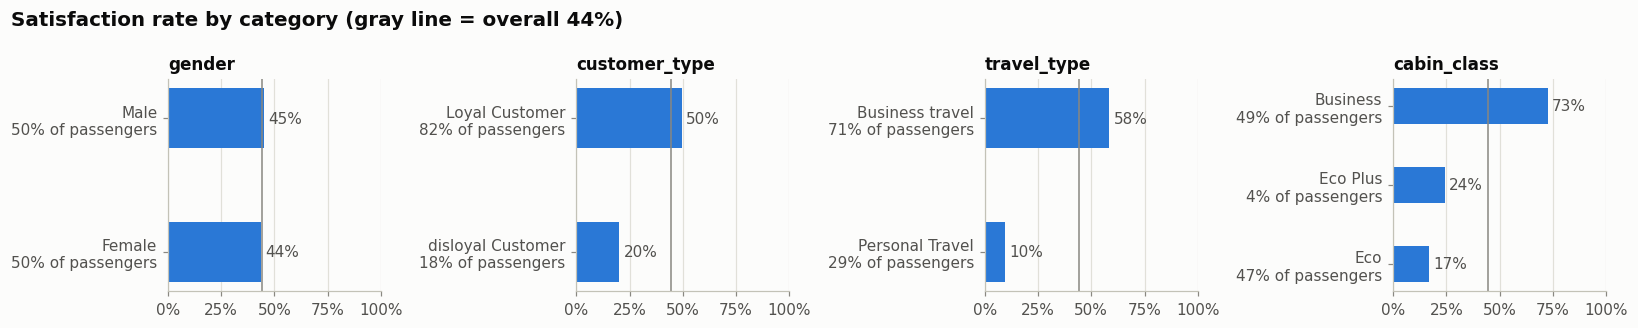

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.0))
for ax, col in zip(axes, CATEGORICAL):
    stats = train.groupby(col)[TARGET].agg(rate="mean", n="size").sort_values("rate")
    labels = [f"{value}\n{n / len(train):.0%} of passengers" for value, n in stats["n"].items()]
    ax.barh(labels, stats["rate"], height=0.45, color=BLUE)
    ax.axvline(overall_rate, color=MUTED, linewidth=1)
    for i, rate in enumerate(stats["rate"]):
        ax.text(rate + 0.02, i, f"{rate:.0%}", va="center", color=INK2)
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis="y", visible=False)
    ax.set_title(col)
fig.suptitle(f"Satisfaction rate by category (gray line = overall {overall_rate:.0%})", x=0.01, ha="left")
fig.tight_layout()
plt.show()

**What this shows:**
- **`travel_type` and `cabin_class` are the big ones.** Business travellers are 58% satisfied and personal travellers only 10%. Business class is 73% satisfied, against 17% in Eco and 24% in Eco Plus.
- **`customer_type` matters too:** loyal customers are 50% satisfied, disloyal ones 20%.
- **`gender` makes no difference** (44% vs 45%). It is close to useless as a feature.

Trip type and cabin class are probably linked: business travellers fly Business class more often. The next chart looks at the two together.

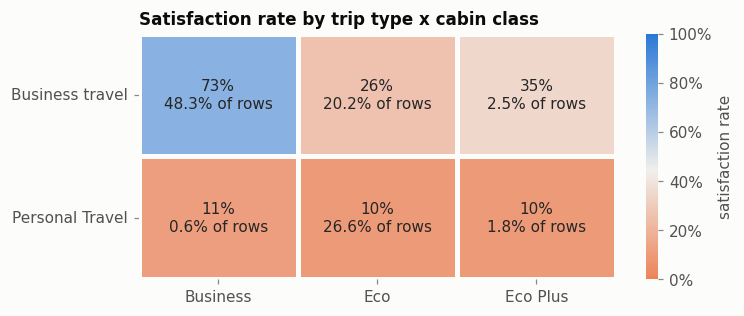

In [11]:
rate = train.pivot_table(index="travel_type", columns="cabin_class", values=TARGET, aggfunc="mean")
share = pd.crosstab(train["travel_type"], train["cabin_class"], normalize=True)
labels = rate.map(lambda r: f"{r:.0%}") + "\n" + share.map(lambda s: f"{s:.1%} of rows")

fig, ax = plt.subplots(figsize=(7, 2.9))
sns.heatmap(rate, annot=labels, fmt="", cmap=DIVERGING, center=overall_rate, vmin=0, vmax=1,
            linewidths=2, linecolor=SURFACE, cbar_kws={"format": PercentFormatter(1), "label": "satisfaction rate"}, ax=ax)
ax.set_title("Satisfaction rate by trip type x cabin class")
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="y", rotation=0)
ax.grid(False)
plt.show()

**What this shows:** satisfaction depends on the *combination* of trip type and cabin class.
- **Business travel in Business class** is the happy core: 73% satisfied, and 48% of all passengers.
- **Personal travel** is about 10% satisfied **whatever the class**. Even the rare personal traveller in Business class (0.6% of rows) is only 11% satisfied.
- Business travellers in Eco or Eco Plus sit in between (26–35%).

Tree models can learn this combination on their own, but a ready-made `travel_class` feature makes it easier for them. We create it in section 7.

### 4.2 Service ratings

There are 13 ratings with 6 possible values each. The left heatmap shows the satisfaction rate for every rating value, and the right one shows how often each value is given.

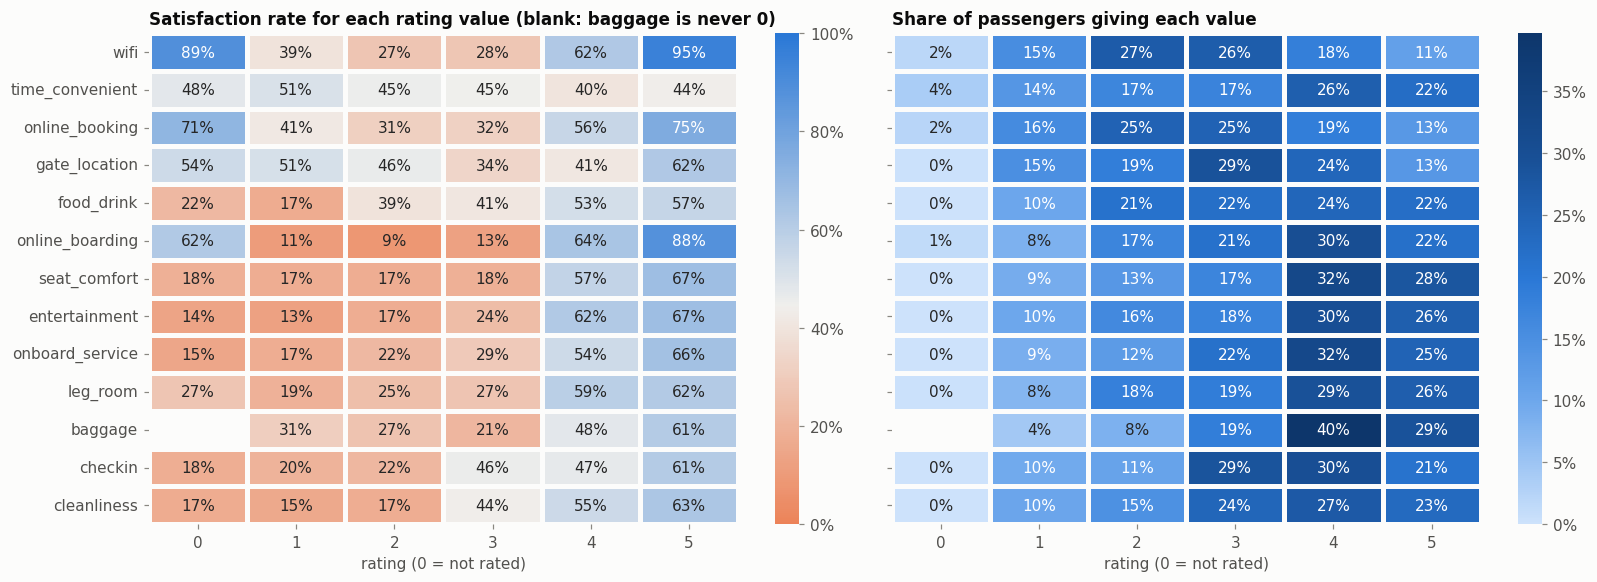

In [12]:
rate_by_value = pd.DataFrame({r: train.groupby(r)[TARGET].mean() for r in RATINGS}).T
share_by_value = pd.DataFrame({r: train[r].value_counts(normalize=True) for r in RATINGS}).T.sort_index(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.4), sharey=True)
sns.heatmap(rate_by_value, annot=True, fmt=".0%", cmap=DIVERGING, center=overall_rate, vmin=0, vmax=1,
            linewidths=2, linecolor=SURFACE, cbar_kws={"format": PercentFormatter(1, decimals=0)}, ax=axes[0])
axes[0].set_title("Satisfaction rate for each rating value (blank: baggage is never 0)")
sns.heatmap(share_by_value, annot=True, fmt=".0%", cmap=SEQUENTIAL, vmin=0,
            linewidths=2, linecolor=SURFACE, cbar_kws={"format": PercentFormatter(1, decimals=0)}, ax=axes[1])
axes[1].set_title("Share of passengers giving each value")
for ax in axes:
    ax.set_xlabel("rating (0 = not rated)")
    ax.grid(False)
fig.tight_layout()
plt.show()

**What this shows:**
- **Comfort ratings have a clear "jump" between 3 and 4.** For `seat_comfort`, `entertainment`, `onboard_service`, `leg_room` and `cleanliness`, ratings 1–3 go with ~15–30% satisfaction and ratings 4–5 with ~55–67%.
- **Digital services are U-shaped.** For `wifi`, `online_booking` and `online_boarding`, ratings 1–3 mean low satisfaction, 4–5 mean high, **and 0 ("not rated") also means high**. Wifi = 0 goes with 89% satisfaction, the highest value in the whole table. This pattern isn't a straight line, so a linear model would miss it; tree models handle it naturally.
- **`online_boarding` is the strongest single rating:** 9–13% satisfied at 1–3, 88% at 5.
- **`time_convenient` and `gate_location` barely matter.** Their rows stay near the average colour, and higher `time_convenient` even goes with slightly *lower* satisfaction.
- **0 is rare** (under 4% for any rating) but carries a strong signal. We keep it as its own value instead of treating it as missing.

How many 0s a passenger gives turns out to be a feature on its own:

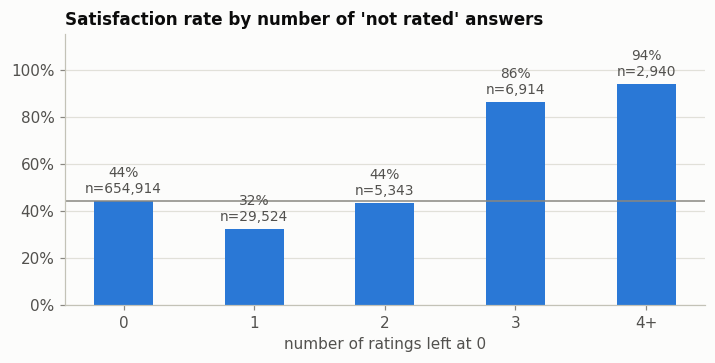

In [13]:
n_zero = (train[RATINGS] == 0).sum(axis=1).clip(upper=4)     # 4, 5 and 6 zeros are rare, so group them as "4+"
stats = train.groupby(n_zero)[TARGET].agg(rate="mean", n="size")

fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.bar(["0", "1", "2", "3", "4+"], stats["rate"], width=0.45, color=BLUE)
ax.axhline(overall_rate, color=MUTED, linewidth=1)
for i, (rate, n) in enumerate(zip(stats["rate"], stats["n"])):
    ax.text(i, rate + 0.02, f"{rate:.0%}\nn={n:,}", ha="center", va="bottom", fontsize=9, color=INK2)
ax.set_ylim(0, 1.15)
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(axis="x", visible=False)
ax.set_xlabel("number of ratings left at 0")
ax.set_title("Satisfaction rate by number of 'not rated' answers")
plt.show()

**What this shows:** passengers who leave **3 or more** ratings at 0 are 86–94% satisfied, although they are only 1.4% of rows. A count of zero ratings (`n_zero_ratings`) goes into the feature set.

### 4.3 Age and flight distance

For each feature, the top chart shows how many passengers there are at each value, and the bottom chart shows their satisfaction rate. Two separate charts are easier to read than one chart with two y-axes.

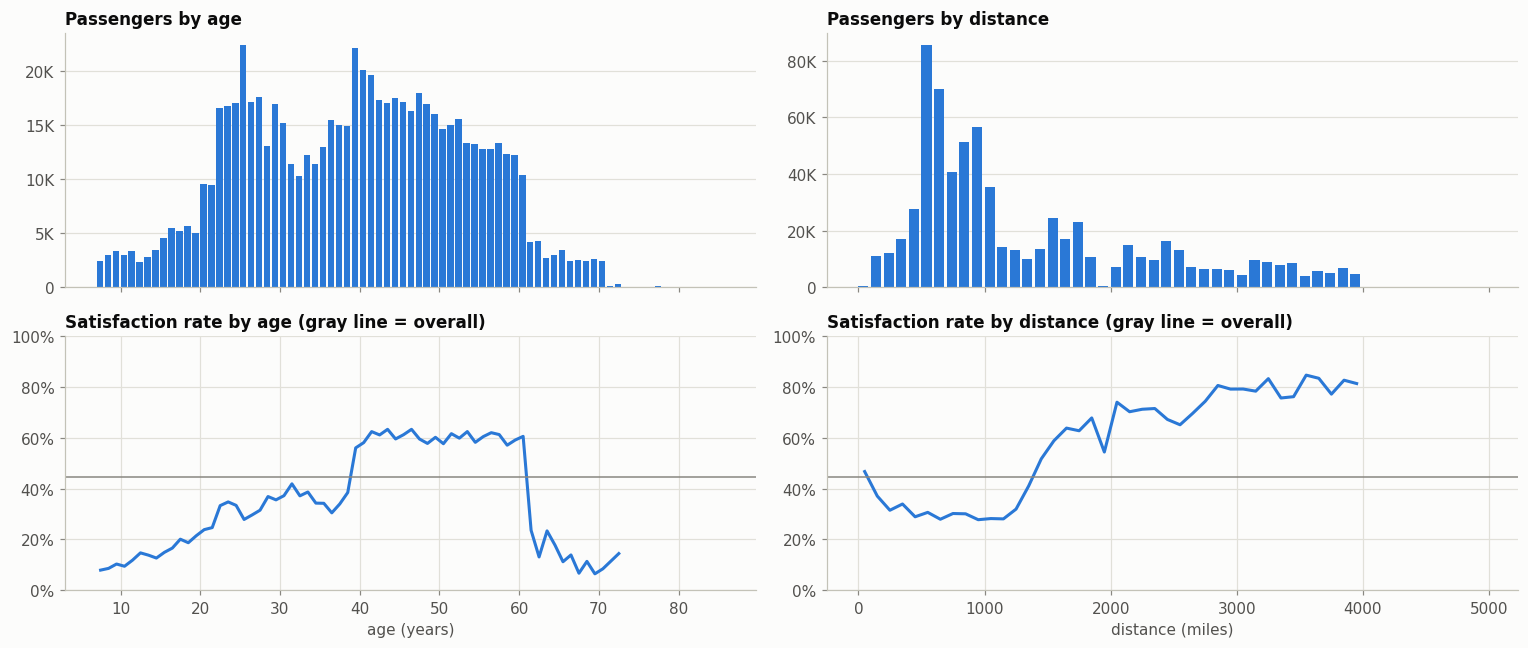

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(14, 6), sharex="col")
for j, (col, width, unit) in enumerate([("age", 1, "years"), ("distance", 100, "miles")]):
    binned = (train[col] // width) * width
    stats = train.groupby(binned)[TARGET].agg(rate="mean", n="size")
    axes[0, j].bar(stats.index, stats["n"], width=width * 0.8, align="edge", color=BLUE)
    axes[0, j].yaxis.set_major_formatter(THOUSANDS)
    axes[0, j].grid(axis="x", visible=False)
    axes[0, j].set_title(f"Passengers by {col}")
    reliable = stats[stats["n"] >= 200]          # hide tiny bins whose rate is just noise
    axes[1, j].plot(reliable.index + width / 2, reliable["rate"], color=BLUE, linewidth=2)
    axes[1, j].axhline(overall_rate, color=MUTED, linewidth=1)
    axes[1, j].set_ylim(0, 1)
    axes[1, j].yaxis.set_major_formatter(PercentFormatter(1))
    axes[1, j].set_title(f"Satisfaction rate by {col} (gray line = overall)")
    axes[1, j].set_xlabel(f"{col} ({unit})")
fig.tight_layout()
plt.show()

**What this shows:**
- **Age is shaped like a hill.** Children and teenagers (≤17: 14%) and passengers over 65 (10%) are rarely satisfied. Ages 40–60 are the happiest (~60%). These are mostly business travellers, so age partly stands in for trip type.
- **The age curve has sharp steps at exactly 40 (up) and 61 (down)**, and the passenger counts jump at the same ages. Real behaviour doesn't change overnight on a birthday, so this is most likely a trace of how the data was generated. A tree model can pick up such steps directly from the raw `age` value.
- **Distance has a step around 1,500 miles.** Short and medium flights (under 1,500 miles) are ~30% satisfied, long-haul flights 62–80%. Long flights are more often business trips in Business class.
- The distance histogram is spiky. Some exact distances (594, 862, 2,475 miles…) occur thousands of times, while others occur only a few times. Section 5 shows that **how common a distance is** carries signal of its own.

### 4.4 Delays

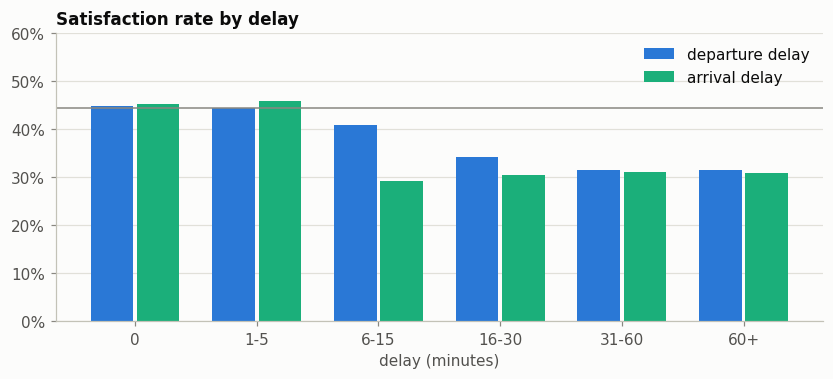

Rows with dep_delay == arr_delay: 86.9%, correlation: 0.84


departure delay           arrival delay          
           passengers satisfied    passengers satisfied
0              635152     0.448        640415     0.452
1-5             25786     0.444         19165     0.459
6-15            20070     0.408         21119     0.293
16-30           11967     0.342         12894     0.304
31-60            6307     0.314          5440     0.310
60+               353     0.314           310     0.310

In [15]:
bins = [-0.5, 0.5, 5, 15, 30, 60, np.inf]
bin_labels = ["0", "1-5", "6-15", "16-30", "31-60", "60+"]
x = np.arange(len(bin_labels))
width = 0.38

fig, ax = plt.subplots(figsize=(9, 3.4))
delay_table = {}
for offset, (col, color, label) in zip([-width / 2, width / 2],
                                       [("dep_delay", BLUE, "departure delay"), ("arr_delay", AQUA, "arrival delay")]):
    stats = train.groupby(pd.cut(train[col], bins, labels=bin_labels), observed=False)[TARGET].agg(rate="mean", n="size")
    ax.bar(x + offset, stats["rate"], width=width - 0.03, color=color, label=label)
    delay_table[(label, "passengers")] = stats["n"]
    delay_table[(label, "satisfied")] = stats["rate"].round(3)
ax.axhline(overall_rate, color=MUTED, linewidth=1)
ax.set_xticks(x, bin_labels)
ax.set_xlabel("delay (minutes)")
ax.set_ylim(0, 0.6)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right")
ax.set_title("Satisfaction rate by delay")
plt.show()

print(f"Rows with dep_delay == arr_delay: {(train['dep_delay'] == train['arr_delay']).mean():.1%}, "
      f"correlation: {train['dep_delay'].corr(train['arr_delay']):.2f}")
pd.DataFrame(delay_table)

**What this shows:**
- **91% of flights have no delay at all.** Delays are rare and mostly short.
- Delays lower satisfaction, but only moderately: from ~45% with no delay to ~30–34% after 15+ minutes. Arrival delay matters a bit more than departure delay, since its rate drops already at 6–15 minutes.
- The two delays are nearly copies of each other: equal in 87% of rows, correlation 0.84. That's why the missing `arr_delay` values can be filled from `dep_delay`.
- On their own, delays are weak features (see the single-feature AUC below).

### 4.5 How the features relate to each other

Spearman correlation measures how well one feature's ranking matches another's. Only correlations of 0.4 or more (in either direction) are labelled.

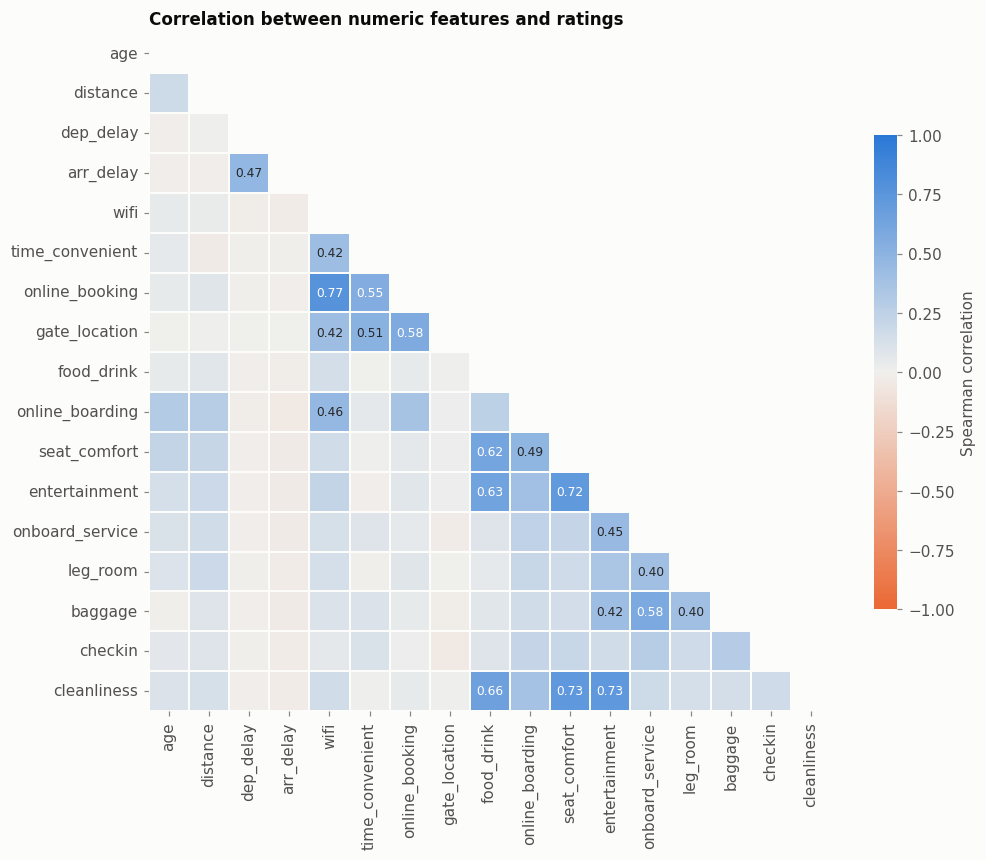

In [16]:
corr = train[NUMERIC + RATINGS].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))                    # show each pair once
labels = corr.map(lambda v: f"{v:.2f}" if abs(v) >= 0.4 else "")

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=labels, fmt="", annot_kws={"fontsize": 8}, cmap=DIVERGING, center=0, vmin=-1, vmax=1,
            linewidths=1, linecolor=SURFACE, cbar_kws={"label": "Spearman correlation", "shrink": 0.7}, ax=ax)
ax.set_title("Correlation between numeric features and ratings")
ax.grid(False)
plt.show()

**What this shows:** the ratings form two clusters.
- **The "digital / pre-flight" cluster:** `wifi`, `online_booking`, `gate_location` and `time_convenient`. `wifi` and `online_booking` are strongly correlated (0.77).
- **The "comfort" cluster:** `seat_comfort`, `entertainment`, `cleanliness` and `food_drink` (0.62–0.73).
- `onboard_service` goes with `baggage` (0.58), and the two delays go together (0.47 here; Spearman is lower than the 0.84 above because 91% of the delays are tied at 0).
- Age and distance are only weakly related to the ratings (at most ~0.3, with `online_boarding` and `seat_comfort`).

Group averages of these clusters (`digital_mean`, `comfort_mean`, `service_mean`) summarise each cluster in one number and smooth out the noise in individual answers.

### 4.6 How strong is each feature on its own?

We rank passengers by a **single** feature and compute the AUC (for a categorical feature, its categories are ranked by their satisfaction rate). An AUC of 0.5 means no signal; 1.0 would be a perfect ranking. A feature that ranks passengers backwards is just as useful, so we report max(AUC, 1 − AUC).

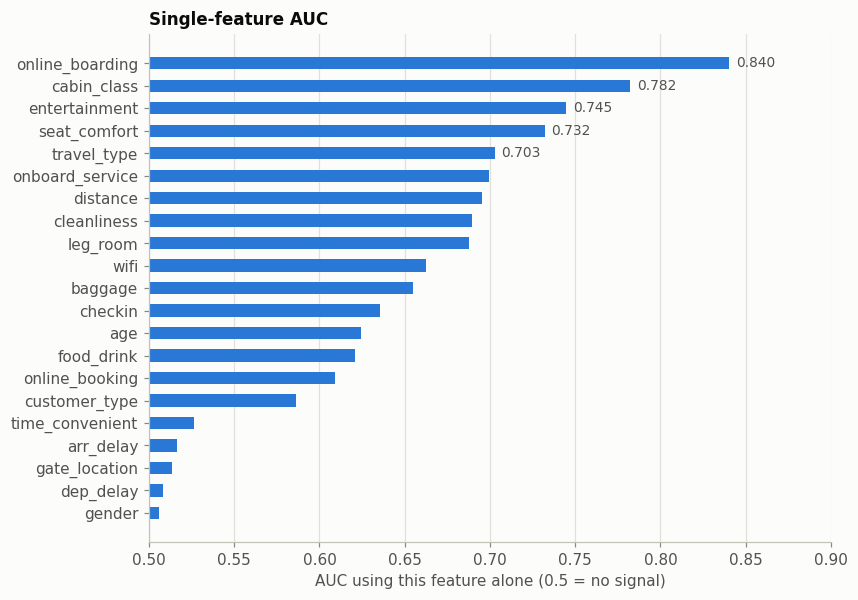

In [17]:
def single_feature_auc(df, col):
    values = df[col]
    if col in CATEGORICAL or values.dtype.name == "category":
        values = values.map(df.groupby(col, observed=True)[TARGET].mean()).astype(float)
    auc = roc_auc_score(df[TARGET], values.fillna(values.median()))
    return max(auc, 1 - auc)

single_auc = pd.Series({col: single_feature_auc(train, col) for col in RAW_FEATURES}).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(single_auc.index, single_auc - 0.5, left=0.5, height=0.55, color=BLUE)   # bars start at 0.5 = no signal
for i, (col, auc) in enumerate(single_auc.items()):
    if i >= len(single_auc) - 5:                                                   # label only the top 5
        ax.text(auc + 0.004, i, f"{auc:.3f}", va="center", fontsize=9, color=INK2)
ax.set_xlim(0.5, 0.9)
ax.grid(axis="y", visible=False)
ax.set_xlabel("AUC using this feature alone (0.5 = no signal)")
ax.set_title("Single-feature AUC")
plt.show()

**What this shows:**
- **`online_boarding` alone already reaches AUC 0.84**, followed by `cabin_class` (0.78), `entertainment` (0.74), `seat_comfort` (0.73) and `travel_type` (0.70).
- **`distance` (0.70) and `age` (0.62) are mid-strength.** They have many distinct values, so they are where engineered features (counts, target encodings) can add the most.
- **`gender`, both delays, `gate_location` and `time_convenient` are almost noise on their own** (0.51–0.53). They may still help in combination with other features.

A good model combines everything and reaches ~0.96 AUC, far above any single feature.

## 5. Synthetic vs original data

Kaggle says the competition data was *"inspired by"* the original dataset: *"Feature distributions are close to, but not exactly the same."* Before using the original data, we need to know **how** it differs. We run the same adversarial validation as before, this time train vs original.

In [18]:
auc_train_orig, adv_importance = adversarial_auc(train.sample(200_000, random_state=SEED), original, RAW_FEATURES)
print(f"Adversarial AUC, train vs original: {auc_train_orig:.4f}")
print("Features that give the difference away (share of split gain):")
print(adv_importance.head(5).round(3).to_string())

Adversarial AUC, train vs original: 0.8331
Features that give the difference away (share of split gain):
arr_delay         0.447
distance          0.252
dep_delay         0.098
age               0.038
online_booking    0.015


**AUC 0.83: the synthetic data is clearly different from the original**, and the difference comes mostly from the **delays** and **distance**. The next table and chart show how.

In [19]:
def delay_profile(df):
    return {
        "flights with no departure delay": f"{(df['dep_delay'] == 0).mean():.1%}",
        "mean departure delay (min)": round(df["dep_delay"].mean(), 1),
        "mean arrival delay (min)": round(df["arr_delay"].mean(), 1),
        "max departure delay (min)": int(df["dep_delay"].max()),
    }

pd.DataFrame({name: delay_profile(df) for name, df in [("train", train), ("test", test), ("original", original)]})

,train,test,original
flights with no departure delay,90.8%,90.8%,56.5%
mean departure delay (min),1.2,1.2,14.7
mean arrival delay (min),1.1,1.1,15.1
max departure delay (min),489,480,1592


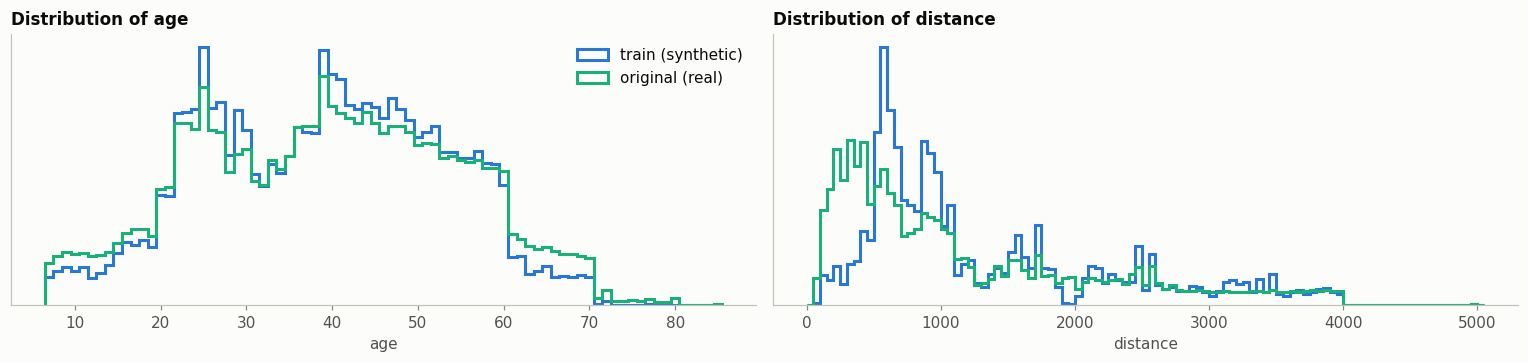

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.4))
for ax, (col, bins) in zip(axes, [("age", np.arange(6.5, 86.5, 1)), ("distance", np.arange(0, 5100, 50))]):
    for df, color, label in [(train, BLUE, "train (synthetic)"), (original, AQUA, "original (real)")]:
        ax.hist(df[col], bins=bins, density=True, histtype="step", linewidth=2, color=color, label=label)
    ax.set_yticks([])
    ax.grid(axis="x", visible=False)
    ax.set_xlabel(col)
    ax.set_title(f"Distribution of {col}")
axes[0].legend(loc="upper right")
fig.tight_layout()
plt.show()

**What this shows:**
- **Delays were heavily shrunk** in the synthetic data. In the original, 56% of flights left on time and the mean delay was ~15 minutes; in train, 91% left on time and the mean is ~1.2 minutes. Delay statistics from the original therefore don't carry over, so we **won't** build original-data features on delays.
- **Age keeps the same shape**, including the steps at 40 and 61. The original just has more children and more passengers over 60.
- **Distance changed more.** The original has many very short flights (under 500 miles), while train has fewer of them and peaks around 550–650 miles.
- Test looks exactly like train, as the adversarial check showed.

Does a feature still *mean* the same thing in both datasets? We compare satisfaction rates per category:

In [21]:
rows = []
for col in CATEGORICAL:
    for value, rate in train.groupby(col)[TARGET].mean().items():
        orig_rate = original.loc[original[col] == value, TARGET].mean()
        rows.append({"feature": col, "value": value, "train": round(rate, 3), "original": round(orig_rate, 3)})
pd.DataFrame(rows).set_index(["feature", "value"])

train  original
feature       value                             
gender        Female             0.438     0.429
              Male               0.449     0.440
customer_type Loyal Customer     0.495     0.478
              disloyal Customer  0.201     0.240
travel_type   Business travel    0.584     0.584
              Personal Travel    0.097     0.101
cabin_class   Business           0.725     0.694
              Eco                0.168     0.188
              Eco Plus           0.242     0.246

**The relationships carry over.** Satisfaction rates per category match within a few points (e.g. Business class: 72.5% in train vs 69.4% in the original). So the original's satisfaction rates per value of `distance`, `age` and passenger segment are useful **lookup features**: for each passenger, "how satisfied were similar passengers in the real data?"

One last discovery, about `distance`:

Distinct distances: train 3474 | test 3317 | original 3821
Train rows whose distance also exists in the original: 100.0%


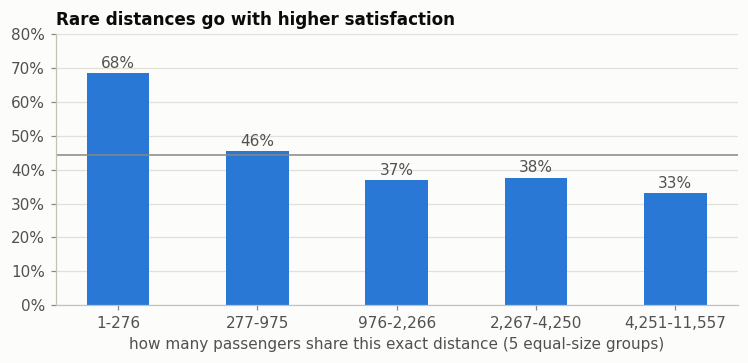

In [22]:
print("Distinct distances: train", train["distance"].nunique(), "| test", test["distance"].nunique(),
      "| original", original["distance"].nunique())
print(f"Train rows whose distance also exists in the original: {train['distance'].isin(original['distance']).mean():.1%}")

# How many train + test passengers share each exact distance (no target used, so this is safe)
distance_count = pd.concat([train["distance"], test["distance"]]).value_counts()
count_bins = pd.qcut(train["distance"].map(distance_count), 5, duplicates="drop")
stats = train.groupby(count_bins, observed=True)[TARGET].mean()

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar([f"{int(b.left) + 1:,}-{int(b.right):,}" for b in stats.index], stats.values, width=0.45, color=BLUE)
ax.axhline(overall_rate, color=MUTED, linewidth=1)
for i, rate in enumerate(stats.values):
    ax.text(i, rate + 0.015, f"{rate:.0%}", ha="center", color=INK2)
ax.set_ylim(0, 0.8)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(axis="x", visible=False)
ax.set_xlabel("how many passengers share this exact distance (5 equal-size groups)")
ax.set_title("Rare distances go with higher satisfaction")
plt.show()

**What this shows:**
- **Every distance in train already exists in the original.** The generator reused the original's distance values instead of inventing new ones.
- **How *common* a distance is predicts satisfaction.** Passengers on rare distances (shared by ≤276 passengers) are 68% satisfied; those on the most common distances are 33% satisfied. Common distances are probably popular short routes, rare ones long-haul routes.

A "value count" therefore adds information that the raw number doesn't contain directly. We add count features for `distance`, `age` and the delays.

**Summary of section 5:**
1. The original data is useful, but it's **different**. We use it as a source of **lookup features** computed from its labels (and as a separate model), not by mixing its rows into our validation.
2. Its delay statistics don't carry over and are skipped.
3. Value counts carry signal that comes from how the data was generated.

## 6. Preprocessing

Gradient-boosted trees (LightGBM, XGBoost, CatBoost) need much less preprocessing than linear models:
- **No scaling**, because trees only compare values against thresholds.
- **No one-hot encoding**, because LightGBM handles pandas `category` columns natively.
- **No outlier removal.** The long delays are real and rare, and trees are not distorted by them.
- **Rating 0 stays a real value**, not missing, because it carries a strong signal (section 4.2).

What we *do* is in `preprocess()` below. It uses no target information, so it's safe to apply to train, test and original alike.

In [23]:
CATEGORY_LEVELS = {col: sorted(train[col].unique()) for col in CATEGORICAL}

def preprocess(df):
    out = df.copy()
    # 1) Missing arrival delays (~0.04%): copy the departure delay, which equals it in 87% of rows
    out["arr_delay"] = out["arr_delay"].fillna(out["dep_delay"])
    # 2) Text -> pandas 'category' with the SAME levels in every table, so category codes match
    for col in CATEGORICAL:
        out[col] = pd.Categorical(out[col], categories=CATEGORY_LEVELS[col])
    # 3) Smaller number types: 0-5 ratings fit in int8, distances in int16 (saves memory on 1M rows)
    out[RATINGS] = out[RATINGS].astype("int8")
    out["age"] = out["age"].astype("int8")
    out["distance"] = out["distance"].astype("int16")
    out[["dep_delay", "arr_delay"]] = out[["dep_delay", "arr_delay"]].astype("float32")
    if TARGET in out:
        out[TARGET] = out[TARGET].astype("int8")
    return out

memory_before = train.memory_usage(deep=True).sum() / 1e6
train_p, test_p, original_p = preprocess(train), preprocess(test), preprocess(original)
y = train_p[TARGET].to_numpy()

print(f"Train memory: {memory_before:.0f} MB -> {train_p.memory_usage(deep=True).sum() / 1e6:.0f} MB")
print("Missing values left:", int(train_p[RAW_FEATURES].isna().sum().sum() + test_p[RAW_FEATURES].isna().sum().sum()
                                  + original_p[RAW_FEATURES].isna().sum().sum()))
train_p[RAW_FEATURES].dtypes.value_counts()

Train memory: 272 MB -> 26 MB
Missing values left: 0


int8        14
float32      2
int16        1
category     1
category     1
category     1
category     1
Name: count, dtype: int64

The data is now clean and takes a fraction of the memory, which matters on an 8 GB Mac once we add dozens of features to a million rows.

## 7. Feature engineering (routine step 7)

Each feature group comes from something the EDA showed. The groups are added one at a time and measured in section 8.

| # | Group | Idea (from section…) | Uses the target? | Where it's computed |
|---|---|---|---|---|
| 1 | **Domain features** | rating averages, number of 0s, delay sums, passenger segments (4.1–4.5) | no | row by row |
| 2 | **Value counts** | rare distances/ages behave differently (5) | no | train + test together |
| 3 | **Distance digits** | the generator may leave patterns in the digits (5) | no | row by row |
| 4 | **Original lookups** | satisfaction rate of the same distance/age/segment in the real data (5) | original's labels only | original data |
| 5 | **Original model** | a model trained on the original data predicts each passenger | original's labels only | original data |
| 6 | **Target encoding** | satisfaction rate of each distance/age (and pairs) in *our* train | **yes** | inside each CV fold |

**Leakage rule:** a feature that uses train's target must never see the labels of the rows it is scored on, or the CV score becomes over-optimistic. Groups 1–3 don't use the target at all. Groups 4–5 use only the original's labels, and our validation never touches original rows. Group 6 uses train's labels, so it's fitted **inside each fold on the training part only**.

### 7.1 Domain features

In [24]:
DIGITAL = ["wifi", "online_booking", "online_boarding"]
COMFORT = ["seat_comfort", "entertainment", "cleanliness", "food_drink", "leg_room"]
SERVICE = ["onboard_service", "baggage", "checkin"]

# Fixed category levels for the combined segments, so they match in every table
TRAVEL_CLASS_LEVELS = [f"{t} / {c}" for t, c in product(CATEGORY_LEVELS["travel_type"], CATEGORY_LEVELS["cabin_class"])]
SEGMENT_LEVELS = [f"{u} / {t} / {c}" for u, t, c in product(CATEGORY_LEVELS["customer_type"],
                                                             CATEGORY_LEVELS["travel_type"], CATEGORY_LEVELS["cabin_class"])]

def add_domain_features(df):
    out = df.copy()
    ratings = out[RATINGS]
    rated = ratings.replace(0, np.nan)            # 0 = "not rated", so it's left out of averages
    # Overall rating summary
    out["rating_mean"] = rated.mean(axis=1).astype("float32")
    out["rating_std"] = rated.std(axis=1).astype("float32")
    out["rating_min"] = rated.min(axis=1).astype("float32")
    out["n_zero_ratings"] = (ratings == 0).sum(axis=1).astype("int8")
    out["n_low_ratings"] = ratings.isin([1, 2]).sum(axis=1).astype("int8")
    out["n_top_ratings"] = (ratings == 5).sum(axis=1).astype("int8")
    # One average per rating cluster (section 4.5)
    out["digital_mean"] = rated[DIGITAL].mean(axis=1).astype("float32")
    out["comfort_mean"] = rated[COMFORT].mean(axis=1).astype("float32")
    out["service_mean"] = rated[SERVICE].mean(axis=1).astype("float32")
    # Delays
    out["total_delay"] = out["dep_delay"] + out["arr_delay"]
    out["delay_change"] = out["arr_delay"] - out["dep_delay"]       # negative = time made up in the air
    out["delayed_15"] = (out["arr_delay"] > 15).astype("int8")
    # Passenger segments (section 4.1): trip type x class, and customer type x trip type x class
    out["travel_class"] = pd.Categorical(out["travel_type"].astype(str) + " / " + out["cabin_class"].astype(str),
                                         categories=TRAVEL_CLASS_LEVELS)
    out["segment"] = pd.Categorical(out["customer_type"].astype(str) + " / " + out["travel_type"].astype(str)
                                    + " / " + out["cabin_class"].astype(str), categories=SEGMENT_LEVELS)
    return out

train_fe, test_fe = add_domain_features(train_p), add_domain_features(test_p)
DOMAIN_FEATURES = [c for c in train_fe.columns if c not in train_p.columns]

pd.Series({col: single_feature_auc(train_fe, col) for col in DOMAIN_FEATURES}).sort_values(ascending=False).round(4).to_frame("single-feature AUC")

,single-feature AUC
segment,0.8403
rating_mean,0.8127
travel_class,0.8069
digital_mean,0.7675
comfort_mean,0.7628
n_top_ratings,0.7562
n_low_ratings,0.7319
service_mean,0.7169
rating_min,0.6798
rating_std,0.5441


Several new features beat almost every raw feature on their own. `rating_mean` reaches ~0.81, close to `online_boarding`, and the segment features combine three weaker categoricals into one strong one. A high single-feature AUC doesn't guarantee the model improves, though, because the model could already combine the raw columns itself. Section 8 measures that.

### 7.2 Value counts

For each value (or pair of values), we count how many passengers in **train + test** have it. No target is used, so counting over test rows too is safe, and it gives more accurate counts.

In [25]:
COUNT_KEYS = [["distance"], ["age"], ["dep_delay"], ["arr_delay"],
              ["distance", "cabin_class"], ["distance", "travel_type"], ["age", "cabin_class"]]

def key_name(cols):
    return "_".join(cols)

def add_count_features(df, reference):
    out = df.copy()
    for cols in COUNT_KEYS:
        counts = reference.groupby(cols, observed=True).size().astype("int32").rename(f"count_{key_name(cols)}")
        out = out.merge(counts.reset_index(), on=cols, how="left")   # a left merge keeps the row order
    return out

reference = pd.concat([train_fe[RAW_FEATURES], test_fe[RAW_FEATURES]], ignore_index=True)
train_fe, test_fe = add_count_features(train_fe, reference), add_count_features(test_fe, reference)
COUNT_FEATURES = [f"count_{key_name(cols)}" for cols in COUNT_KEYS]
train_fe[COUNT_FEATURES].describe().T[["mean", "min", "50%", "max"]].round(0)

,mean,min,50%,max
count_distance,2346.0,1.0,1482.0,11557.0
count_age,20518.0,3.0,22088.0,31913.0
count_dep_delay,824309.0,1.0,907540.0,907540.0
count_arr_delay,838251.0,1.0,915158.0,915158.0
count_distance_cabin_class,1281.0,1.0,713.0,6616.0
count_distance_travel_type,1312.0,1.0,804.0,7170.0
count_age_cabin_class,10458.0,1.0,10700.0,21292.0


### 7.3 Distance digits

Synthetic data generators sometimes leave patterns in the digits of numbers. One example here: distances ending in 0 are rarer in train (5.6%) than in the original (9.4%). A tree can't easily see "the last digit" in a raw number, so we hand it the digits as separate features. This is a Kaggle-specific trick that exploits how the data was generated, not a real-world effect; section 8 shows whether it helps.

In [26]:
def add_digit_features(df):
    out = df.copy()
    out["distance_d1"] = (out["distance"] % 10).astype("int8")           # last digit
    out["distance_d2"] = (out["distance"] // 10 % 10).astype("int8")     # tens
    out["distance_d3"] = (out["distance"] // 100 % 10).astype("int8")    # hundreds
    return out

train_fe, test_fe = add_digit_features(train_fe), add_digit_features(test_fe)
DIGIT_FEATURES = ["distance_d1", "distance_d2", "distance_d3"]

### 7.4 Original-data lookups

For each key (e.g. a passenger's exact distance), we look up in the **original** data how many passengers had that value (`orig_n_…`) and what share of them were satisfied (`orig_rate_…`). Only the original's labels are used, and validation never scores original rows, so there's no leakage. Delays are left out because their distribution changed (section 5).

In [27]:
LOOKUP_KEYS = [["distance"], ["age"], ["distance", "cabin_class"], ["distance", "travel_type"],
               ["age", "cabin_class"], ["age", "travel_type"], ["customer_type", "travel_type", "cabin_class"]]

def add_original_lookups(df, original):
    out = df.copy()
    for cols in LOOKUP_KEYS:
        name = key_name(cols)
        stats = (original.groupby(cols, observed=True)[TARGET].agg(["mean", "size"])
                 .rename(columns={"mean": f"orig_rate_{name}", "size": f"orig_n_{name}"})
                 .astype("float32").reset_index())
        out = out.merge(stats, on=cols, how="left")   # values never seen in the original stay NaN
    return out

train_fe, test_fe = add_original_lookups(train_fe, original_p), add_original_lookups(test_fe, original_p)
LOOKUP_FEATURES = [f"orig_{kind}_{key_name(cols)}" for cols in LOOKUP_KEYS for kind in ("rate", "n")]

pd.DataFrame({
    "coverage in train": train_fe[LOOKUP_FEATURES[::2]].notna().mean().round(3),
    "single-feature AUC": [single_feature_auc(train_fe, c) for c in LOOKUP_FEATURES[::2]],
}).round(4)

,coverage in train,single-feature AUC
orig_rate_distance,1.0,0.7310
orig_rate_age,1.0,0.6853
orig_rate_distance_cabin_class,1.0,0.8307
orig_rate_distance_travel_type,1.0,0.8107
orig_rate_age_cabin_class,1.0,0.8301
orig_rate_age_travel_type,1.0,0.7993
orig_rate_customer_type_travel_type_cabin_class,1.0,0.8403


`orig_rate_distance` (the real-data satisfaction rate for the passenger's exact distance) reaches a single-feature AUC of ~0.73, above raw `distance` (0.70). The pair lookups are much stronger (~0.81–0.84), because they combine distance or age with trip type and class. Every key in train exists in the original, so coverage is 100%.

### 7.5 Original-data model

A more compact way to use the original is to **train a model on the original data alone** and give its predicted probability to our main model as one extra feature. The original model never sees train's labels, so this is leakage-free.

In [28]:
original_model = lgb.LGBMClassifier(n_estimators=500, learning_rate=0.05, num_leaves=31, random_state=SEED, verbose=-1)
original_model.fit(original_p[RAW_FEATURES], original_p[TARGET])

train_fe["orig_model_prob"] = original_model.predict_proba(train_fe[RAW_FEATURES])[:, 1].astype("float32")
test_fe["orig_model_prob"] = original_model.predict_proba(test_fe[RAW_FEATURES])[:, 1].astype("float32")
print(f"AUC of the original-only model on our train set: {roc_auc_score(y, train_fe['orig_model_prob']):.4f}")

AUC of the original-only model on our train set: 0.9527


A model that never saw a single competition row already scores ~0.95 AUC on train, which confirms that the synthetic data follows the real data's patterns closely. The leftover differences are what our main model learns on top.

### 7.6 Target encoding (inside the folds)

Target encoding replaces a value with **the satisfaction rate of passengers with that value in train**: for example, `distance = 594` becomes the share of satisfied passengers among everyone in train who flew exactly 594 miles. It's like the original lookups, but learned from our own, much larger data. It's powerful for features with many values, like `distance` (3,474 values) and pairs like distance x class.

It uses train's labels, so it must be done carefully. Inside each CV fold:
1. the encoder learns rates from the fold's **training part only**;
2. those rates are applied to the validation part and the test set;
3. for the training part itself, scikit-learn's `TargetEncoder` uses an internal 5-fold split. That way no row's own label goes into its own encoding.

Here we only build the integer keys. The encoding happens in the CV loop (section 8).

In [29]:
TE_KEYS = [["distance"], ["age"], ["distance", "cabin_class"], ["distance", "travel_type"],
           ["distance", "customer_type"], ["age", "cabin_class"], ["age", "travel_type"]]

def build_te_keys(df):
    # One integer per key; a pair (distance, class) becomes distance * 10 + class code
    keys = pd.DataFrame(index=df.index)
    for cols in TE_KEYS:
        key = df[cols[0]].astype("int32")
        for col in cols[1:]:
            key = key * 10 + df[col].cat.codes.astype("int32")
        keys[f"te_{key_name(cols)}"] = key
    return keys

def add_target_encoding(X_tr, y_tr, X_va, X_te, keys_tr, keys_va, keys_te):
    # Fit on the fold's training rows only; cross-fitting inside fit_transform protects the training rows themselves
    encoder = TargetEncoder(target_type="binary", cv=StratifiedKFold(5, shuffle=True, random_state=SEED))
    names = list(keys_tr.columns)
    parts = []
    for X, encoded in [(X_tr, encoder.fit_transform(keys_tr, y_tr)), (X_va, encoder.transform(keys_va)),
                       (X_te, encoder.transform(keys_te))]:
        parts.append(pd.concat([X.reset_index(drop=True),
                                pd.DataFrame(encoded.astype("float32"), columns=names)], axis=1))
    return parts

te_keys_train, te_keys_test = build_te_keys(train_fe), build_te_keys(test_fe)
TE_FEATURES = list(te_keys_train.columns)
print(f"{len(TE_FEATURES)} target-encoded keys:", ", ".join(TE_FEATURES))
print("Distinct values per key:", te_keys_train.nunique().to_dict())

7 target-encoded keys: te_distance, te_age, te_distance_cabin_class, te_distance_travel_type, te_distance_customer_type, te_age_cabin_class, te_age_travel_type
Distinct values per key: {'te_distance': 3474, 'te_age': 75, 'te_distance_cabin_class': 5600, 'te_distance_travel_type': 4594, 'te_distance_customer_type': 4607, 'te_age_cabin_class': 223, 'te_age_travel_type': 139}


## 8. Feature check: does each group improve CV AUC?

We add the groups one at a time and train the **same** LightGBM on the **same** 5 folds each time. The model settings are fixed and fast (learning rate 0.1). These runs only compare feature sets; the real tuning comes later.

For each run we report:
- **OOF AUC:** the AUC of all out-of-fold predictions together. This is our main score.
- **Fold AUC mean ± std:** how stable the score is across the 5 folds.
- **Gain vs previous** and **folds improved:** what the newly added group changed, compared fold by fold on identical data. A gain that shows up in all 5 folds is real; a gain in 3 of 5 folds is probably noise.

Each run saves its out-of-fold and test predictions in `preds/`. If the notebook is re-run, the saved predictions are loaded instead of retraining.

A note on early stopping: each fold stops adding trees when its validation AUC stops improving. That makes every score slightly optimistic, but equally for all feature sets, so the comparison stays fair.

In [30]:
LGB_PARAMS = dict(n_estimators=5000, learning_rate=0.1, num_leaves=63, subsample=0.8, subsample_freq=1,
                  colsample_bytree=0.8, random_state=SEED, verbose=-1, n_jobs=-1)

def run_cv(name, features, use_target_encoding=False, params=LGB_PARAMS):
    # Train one LightGBM per fold; return out-of-fold predictions, averaged test predictions and fold AUCs
    oof_path, test_path = PREDS / f"{name}-oof.npy", PREDS / f"{name}-test.npy"
    if oof_path.exists() and test_path.exists():
        oof, test_pred = np.load(oof_path), np.load(test_path)
        print(f"{name}: loaded saved predictions")
    else:
        oof, test_pred = np.zeros(len(train_fe)), np.zeros(len(test_fe))
        start = time.time()
        for tr_idx, va_idx in folds:
            X_tr, X_va, X_te = train_fe[features].iloc[tr_idx], train_fe[features].iloc[va_idx], test_fe[features]
            if use_target_encoding:
                X_tr, X_va, X_te = add_target_encoding(X_tr, y[tr_idx], X_va, X_te, te_keys_train.iloc[tr_idx],
                                                       te_keys_train.iloc[va_idx], te_keys_test)
            model = lgb.LGBMClassifier(**params)
            model.fit(X_tr, y[tr_idx], eval_X=X_va, eval_y=y[va_idx], eval_metric="auc",
                      callbacks=[lgb.early_stopping(100, verbose=False)])
            oof[va_idx] = model.predict_proba(X_va)[:, 1]
            test_pred += model.predict_proba(X_te)[:, 1] / len(folds)
        np.save(oof_path, oof)
        np.save(test_path, test_pred)
        print(f"{name}: trained in {time.time() - start:.0f}s")
    fold_auc = np.array([roc_auc_score(y[va_idx], oof[va_idx]) for _, va_idx in folds])
    return oof, test_pred, fold_auc

The feature sets are cumulative: each one contains the previous set plus one new group.

In [31]:
FEATURE_SETS = {
    "01-lgb-raw":           (RAW_FEATURES, False),
    "02-lgb-domain":        (RAW_FEATURES + DOMAIN_FEATURES, False),
    "03-lgb-counts":        (RAW_FEATURES + DOMAIN_FEATURES + COUNT_FEATURES, False),
    "04-lgb-digits":        (RAW_FEATURES + DOMAIN_FEATURES + COUNT_FEATURES + DIGIT_FEATURES, False),
    "05-lgb-orig-lookups":  (RAW_FEATURES + DOMAIN_FEATURES + COUNT_FEATURES + DIGIT_FEATURES + LOOKUP_FEATURES, False),
    "06-lgb-orig-model":    (RAW_FEATURES + DOMAIN_FEATURES + COUNT_FEATURES + DIGIT_FEATURES + LOOKUP_FEATURES
                             + ["orig_model_prob"], False),
    "07-lgb-target-enc":    (RAW_FEATURES + DOMAIN_FEATURES + COUNT_FEATURES + DIGIT_FEATURES + LOOKUP_FEATURES
                             + ["orig_model_prob"], True),
}

cv_results = {}
for name, (features, use_te) in FEATURE_SETS.items():
    oof, test_pred, fold_auc = run_cv(name, features, use_target_encoding=use_te)
    cv_results[name] = {"features": len(features) + (len(TE_FEATURES) if use_te else 0),
                        "oof_auc": roc_auc_score(y, oof), "fold_auc": fold_auc}

01-lgb-raw: loaded saved predictions


02-lgb-domain: loaded saved predictions


03-lgb-counts: loaded saved predictions


04-lgb-digits: loaded saved predictions


05-lgb-orig-lookups: loaded saved predictions


06-lgb-orig-model: loaded saved predictions


07-lgb-target-enc: loaded saved predictions


In [32]:
rows, previous = [], None
for name, r in cv_results.items():
    row = {"features": r["features"], "OOF AUC": f"{r['oof_auc']:.5f}",
           "fold AUC mean ± std": f"{r['fold_auc'].mean():.5f} ± {r['fold_auc'].std():.5f}"}
    if previous is not None:
        gain = r["fold_auc"] - previous["fold_auc"]
        row["gain vs previous"] = f"{r['oof_auc'] - previous['oof_auc']:+.5f}"
        row["folds improved"] = f"{(gain > 0).sum()}/{N_FOLDS}"
    rows.append(row)
    previous = r
results_table = pd.DataFrame(rows, index=list(cv_results)).fillna("")
results_table

,features,OOF AUC,fold AUC mean ± std,gain vs previous,folds improved
01-lgb-raw,21,0.95862,0.95863 ± 0.00067,,
02-lgb-domain,35,0.95844,0.95845 ± 0.00061,-0.00019,0/5
03-lgb-counts,42,0.95896,0.95897 ± 0.00062,+0.00052,5/5
04-lgb-digits,45,0.95925,0.95926 ± 0.00059,+0.00029,5/5
05-lgb-orig-lookups,59,0.95977,0.95978 ± 0.00045,+0.00052,5/5
06-lgb-orig-model,60,0.96005,0.96006 ± 0.00055,+0.00028,5/5
07-lgb-target-enc,67,0.96037,0.96038 ± 0.00055,+0.00032,5/5


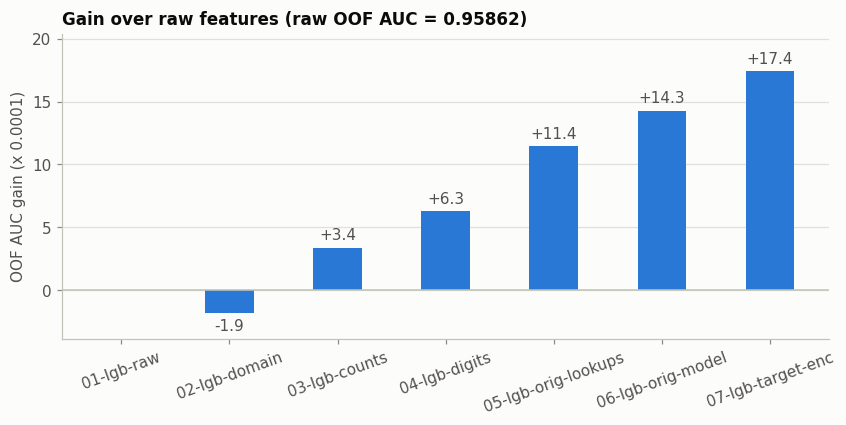

In [33]:
baseline = cv_results["01-lgb-raw"]["oof_auc"]
gains = pd.Series({name: (r["oof_auc"] - baseline) * 1e4 for name, r in cv_results.items()})

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(gains.index, gains.values, width=0.45, color=BLUE)
for i, g in enumerate(gains.values):
    if i > 0:                                                  # the baseline itself has no gain to label
        ax.text(i, g + (0.4 if g >= 0 else -0.4), f"{g:+.1f}", ha="center", va="bottom" if g >= 0 else "top", color=INK2)
ax.axhline(0, color="#c3c2b7", linewidth=1)
ax.set_ylim(min(gains.min() - 2, -1), gains.max() + 3)
ax.set_ylabel("OOF AUC gain (x 0.0001)")
ax.grid(axis="x", visible=False)
ax.tick_params(axis="x", rotation=20)
ax.set_title(f"Gain over raw features (raw OOF AUC = {baseline:.5f})")
plt.show()

**What this shows:**
- **Raw features alone score OOF AUC 0.95862.** A plain LightGBM on the 21 raw columns is already strong.
- **The domain features made it slightly worse** (−0.00019, worse in all 5 folds), despite their high single-feature AUCs. The model can already build rating averages and segments from the raw columns, so the 14 extra columns add no new information. Most likely they just crowd each tree's random sample of columns (80% of them) with redundant choices.
- **Every other group helped, in all 5 folds:**

  | Group | Gain in OOF AUC |
  |---|---|
  | value counts | +0.00052 |
  | distance digits | +0.00029 |
  | original lookups | +0.00052 |
  | original model | +0.00028 |
  | target encoding | +0.00032 |

- **Altogether: 0.95862 → 0.96037 (+0.00174).** That looks small, but the competition is decided by gains of this size: on 29 Oct the top 12 public scores were within 0.0022 of each other.

The sets are cumulative, so the domain features are still part of sets 03–07. The next cell checks whether removing them from the full set helps.

In [34]:
# Set 07 without the domain features: does the model do better without them?
NO_DOMAIN_FEATURES = [f for f in FEATURE_SETS["07-lgb-target-enc"][0] if f not in DOMAIN_FEATURES]
oof, test_pred, fold_auc = run_cv("08-lgb-no-domain", NO_DOMAIN_FEATURES, use_target_encoding=True)
cv_results["08-lgb-no-domain"] = {"features": len(NO_DOMAIN_FEATURES) + len(TE_FEATURES),
                                  "oof_auc": roc_auc_score(y, oof), "fold_auc": fold_auc}

with_domain, without_domain = cv_results["07-lgb-target-enc"], cv_results["08-lgb-no-domain"]
fold_gain = without_domain["fold_auc"] - with_domain["fold_auc"]
print(f"OOF AUC with domain features:    {with_domain['oof_auc']:.5f}")
print(f"OOF AUC without domain features: {without_domain['oof_auc']:.5f} "
      f"({without_domain['oof_auc'] - with_domain['oof_auc']:+.5f}, better in {(fold_gain > 0).sum()}/{N_FOLDS} folds)")

08-lgb-no-domain: loaded saved predictions


OOF AUC with domain features:    0.96037
OOF AUC without domain features: 0.96041 (+0.00004, better in 4/5 folds)


Without the domain features, OOF AUC is **0.96041** against 0.96037 with them: better in 4 of 5 folds, but by only +0.00004, which is within noise. On top of the full feature set they neither help nor hurt, so we **drop them**. The score is the same with 14 fewer columns, which means faster training and a simpler model.

The ideas behind them are still captured in other ways: the passenger segment through `orig_rate_customer_type_travel_type_cabin_class`, and the "not rated" answers through the raw ratings themselves.

In [35]:
# The feature set the modeling sections will use: whichever of 07 / 08 has the higher OOF AUC
best_set = max(["07-lgb-target-enc", "08-lgb-no-domain"], key=lambda name: cv_results[name]["oof_auc"])
MODEL_FEATURES = FEATURE_SETS["07-lgb-target-enc"][0] if best_set == "07-lgb-target-enc" else NO_DOMAIN_FEATURES
USE_TARGET_ENCODING = True
print(f"Feature set for modeling: {best_set}, {len(MODEL_FEATURES)} columns + {len(TE_FEATURES)} target encodings "
      f"(OOF AUC {cv_results[best_set]['oof_auc']:.5f})")

Feature set for modeling: 08-lgb-no-domain, 46 columns + 7 target encodings (OOF AUC 0.96041)


### Which features does the model rely on?

We fit one model on fold 0 with the chosen feature set and look at **gain importance**: how much each feature improved the model's splits in total. This shows what the model uses, not what causes satisfaction.

The shares range from over 80% down to a fraction of a percent, so the x-axis is logarithmic: each gridline is 10 times the previous one.

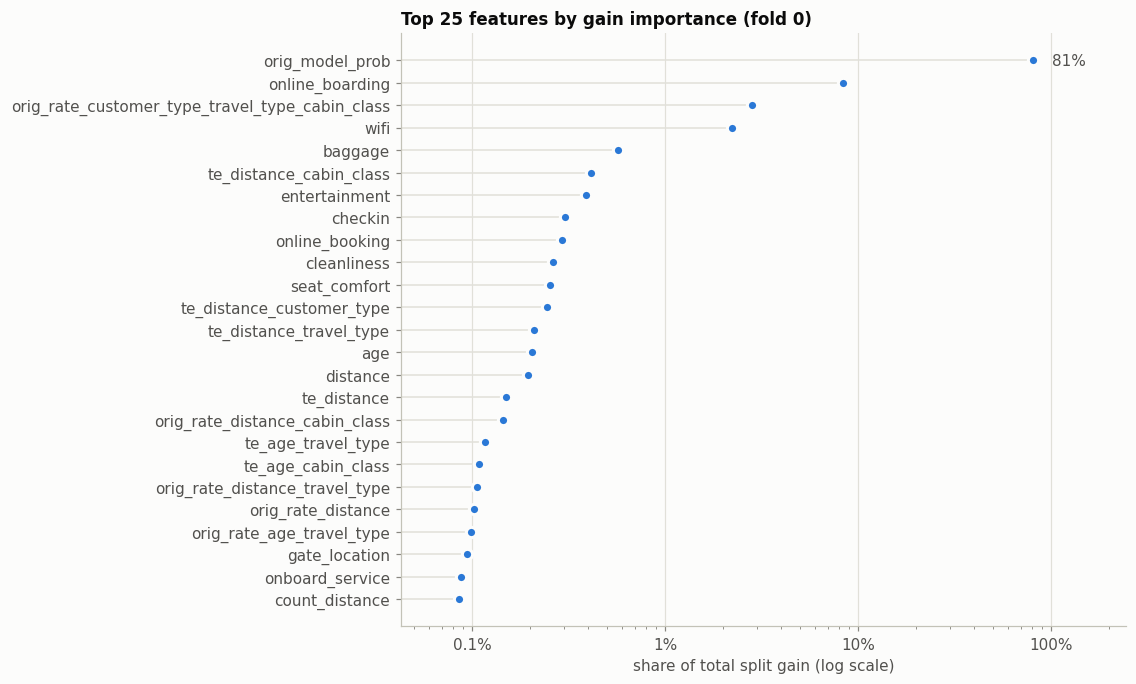

In [36]:
tr_idx, va_idx = folds[0]
X_tr, X_va, _ = add_target_encoding(train_fe[MODEL_FEATURES].iloc[tr_idx], y[tr_idx], train_fe[MODEL_FEATURES].iloc[va_idx],
                                    test_fe[MODEL_FEATURES].iloc[:5], te_keys_train.iloc[tr_idx],
                                    te_keys_train.iloc[va_idx], te_keys_test.iloc[:5])
model = lgb.LGBMClassifier(**LGB_PARAMS).fit(X_tr, y[tr_idx], eval_X=X_va, eval_y=y[va_idx], eval_metric="auc",
                                             callbacks=[lgb.early_stopping(100, verbose=False)])
importance = pd.Series(model.booster_.feature_importance("gain"), index=X_tr.columns)
importance = (importance / importance.sum()).sort_values().tail(25)

fig, ax = plt.subplots(figsize=(8.5, 7))
ax.hlines(importance.index, importance.min() / 2, importance.values, color=GRID, linewidth=1)
ax.scatter(importance.values, importance.index, s=45, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=3)
ax.text(importance.iloc[-1] * 1.25, len(importance) - 1, f"{importance.iloc[-1]:.0%}", va="center", color=INK2)
ax.set_xscale("log")
ax.set_xlim(importance.min() / 2, importance.max() * 3)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.1%}" if v < 0.01 else f"{v:.0%}"))
ax.grid(axis="y", visible=False)
ax.grid(axis="x", which="minor", visible=False)
ax.set_xlabel("share of total split gain (log scale)")
ax.set_title("Top 25 features by gain importance (fold 0)")
plt.show()

**What this shows:** the model leans on `orig_model_prob` for 81% of its split gain. It starts from what the real data says about a passenger and then corrects it, mainly with `online_boarding`, the original segment lookup, `wifi` and the target encodings of distance pairs. The long tail of small contributors is what lifts the score from ~0.953 (the original model alone) to ~0.960.

## 9. Preprocessing for linear models (logistic regression, linear SVM)

So far everything was prepared for tree models. Linear models work differently: they compute a **weighted sum of the columns** and draw one straight boundary between "satisfied" and "not satisfied". That makes them sensitive to things trees ignore:

| Problem for a linear model | Example in our data | What we do |
|---|---|---|
| It can only use numbers | `cabin_class` = "Eco" | **one-hot encoding**: one 0/1 column per category |
| Columns on large scales dominate the fit and the regularization penalty | `distance` goes up to 4,983, ratings only to 5 | **standardization**: every numeric column gets mean 0 and std 1 |
| A few extreme values pull the boundary | delays up to 489 minutes, while 91% are 0 | **outlier handling**: cap at the 99.9th percentile, then take the log |
| A straight line can't follow U-shapes or steps | wifi = 0 and wifi = 5 are both "happy"; age jumps at 40 and 61; distance jumps around 1,500 miles | **one-hot the rating values, bin age and distance**, so each value or range gets its own weight |
| It can't combine two columns by itself | business travel *in* Business class | **bring back the segment features** (`travel_class`, `segment`) |
| Rates and probabilities relate to the target in "log-odds" | `orig_model_prob` = 0.97 | **logit transform**: log(p / (1 − p)) |

Nothing is trained in this section; we only build and inspect the transformed data.

### 9.1 Outliers: remove or cap?

The usual textbook rule (the **IQR rule**) marks a value as an outlier if it lies more than 1.5 x IQR outside the middle 50% of the data. Let's see what it would flag:

In [37]:
def iqr_rule(s):
    q1, q3 = s.quantile([0.25, 0.75])
    low, high = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    return low, high, ((s < low) | (s > high)).mean()

outlier_table = {}
for col in NUMERIC:
    low, high, share = iqr_rule(train_fe[col])
    outlier_table[col] = {"IQR rule: normal range": f"{low:g} to {high:g}", "rows flagged": f"{share:.2%}",
                          "99.9th percentile": train_fe[col].quantile(0.999), "max": train_fe[col].max()}
pd.DataFrame(outlier_table).T

,IQR rule: normal range,rows flagged,99.9th percentile,max
age,-7.5 to 84.5,0.00%,70.0,85
distance,-1143.5 to 3588.5,3.27%,3995.0,4983
dep_delay,0 to 0,9.22%,52.0,489.0
arr_delay,0 to 0,8.43%,49.0,491.0


**What this shows:**
- **Age and distance have no real outliers.** The IQR rule flags no ages and 3.3% of distances (everything above ~3,590 miles). Those are ordinary long-haul flights: the original data covers the same range, and long flights are exactly where satisfaction is highest (section 4.3).
- **For the delays, the IQR rule breaks down.** 91% of the delays are 0, so the "normal range" shrinks to exactly 0, and *every* delayed flight (9% of rows) counts as an outlier.

So we **don't remove any rows**, for three reasons:
1. Removing delayed passengers would throw away exactly the information about how delays affect satisfaction.
2. The test set will contain such passengers too, and every test row needs a prediction. A model that never saw them in training would handle them worse.
3. These values aren't errors: a 300-minute delay really happens.

Instead we **cap** the delays at their 99.9th percentile (52 minutes for departure, 49 for arrival). Only the most extreme 0.1% of values change. A **log transform**, log(1 + x), then squeezes the long tail further, so that 0 → 0, 10 min → 2.4 and 49 min → 3.9. The caps are computed from train and applied unchanged to test.

### 9.2 Building the linear version of the data

The first step is `make_linear_frame()`. It works row by row and learns nothing from the data, apart from the delay caps above:
- **delays:** cap, then log; `total_delay` is dropped because it's just dep + arr;
- **counts** (train + test counts and the original-data counts): log, because they range from 1 to 900,000;
- **rates** (original-data satisfaction rates): smoothed toward the average, then logit (explained below);
- **the original-model probability:** logit;
- **columns that will be one-hot encoded:** passed through unchanged;
- **domain features** (rating summaries, segments): brought back. They didn't help the trees, which build such combinations on their own, but a linear model can't.

**Why smooth the rates?** A rate from a small group is unreliable. If only 3 real passengers flew a certain distance and all 3 were satisfied, the rate is 100%, and its logit would be infinite. That happens for 1.5–2.5% of passengers here. Smoothing pretends every group also contains 10 "average" passengers:

smoothed rate = (satisfied + 10 x 43.4%) / (group size + 10)

A group of 3 satisfied passengers becomes (3 + 4.3) / 13 = 56% instead of 100%. A group of 1,000 barely changes.

In [38]:
DELAY_CAPS = train_fe[["dep_delay", "arr_delay"]].quantile(0.999)          # learned on train, applied everywhere
COUNT_LIKE = COUNT_FEATURES + [c for c in LOOKUP_FEATURES if c.startswith("orig_n_")]
RATE_LIKE = [c for c in LOOKUP_FEATURES if c.startswith("orig_rate_")] + ["orig_model_prob"]
SUMMARY_FEATURES = ["rating_mean", "rating_std", "rating_min", "n_zero_ratings", "n_low_ratings", "n_top_ratings",
                    "digital_mean", "comfort_mean", "service_mean", "delayed_15"]

ORIGINAL_RATE = original_p[TARGET].mean()   # 43.4% satisfied in the original data
SMOOTHING = 10                              # every group counts as if it had 10 extra "average" passengers

def logit(p, eps=1e-6):
    p = np.clip(p, eps, 1 - eps)          # only guards against log(0); keeps the ranking of very confident predictions
    return np.log(p / (1 - p))

def make_linear_frame(df):
    out = pd.DataFrame(index=df.index)
    # Columns that the encoder below turns into 0/1 columns
    for col in CATEGORICAL + ["travel_class", "segment"] + RATINGS + DIGIT_FEATURES + ["age", "distance"]:
        out[col] = df[col]
    # Delays: cap the extreme 0.1%, then log(1 + x)
    dep = df["dep_delay"].clip(upper=DELAY_CAPS["dep_delay"])
    arr = df["arr_delay"].clip(upper=DELAY_CAPS["arr_delay"])
    out["dep_delay_log"] = np.log1p(dep)
    out["arr_delay_log"] = np.log1p(arr)
    out["delay_change"] = arr - dep                                     # minutes gained (<0) or lost (>0) in the air
    # Rating summaries and the delay flag are already on small, even scales
    for col in SUMMARY_FEATURES:
        out[col] = df[col]
    # Counts span 1 to ~900,000: log brings them to a comparable range
    for col in COUNT_LIKE:
        out[f"{col}_log"] = np.log1p(df[col])
    # Rates: smooth small groups toward the average, then logit (the scale a logistic regression works on)
    for col in RATE_LIKE[:-1]:
        group_size = df[col.replace("orig_rate_", "orig_n_")]
        smoothed = (df[col] * group_size + SMOOTHING * ORIGINAL_RATE) / (group_size + SMOOTHING)
        out[f"{col}_logit"] = logit(smoothed)
    out["orig_model_prob_logit"] = logit(df["orig_model_prob"])
    numeric_cols = out.columns[out.columns.get_loc("dep_delay_log"):]
    return out.astype({col: "float32" for col in numeric_cols})

lin_train, lin_test = make_linear_frame(train_fe), make_linear_frame(test_fe)
print(f"Delay caps: departure {DELAY_CAPS['dep_delay']:.0f} min, arrival {DELAY_CAPS['arr_delay']:.0f} min "
      f"({(train_fe['dep_delay'] > DELAY_CAPS['dep_delay']).mean():.2%} of train rows capped)")
print("Linear frame:", lin_train.shape)

Delay caps: departure 52 min, arrival 49 min (0.09% of train rows capped)
Linear frame: (699635, 59)


The charts below show what the log and logit transforms do to three skewed columns. The top row is before, the bottom row after:

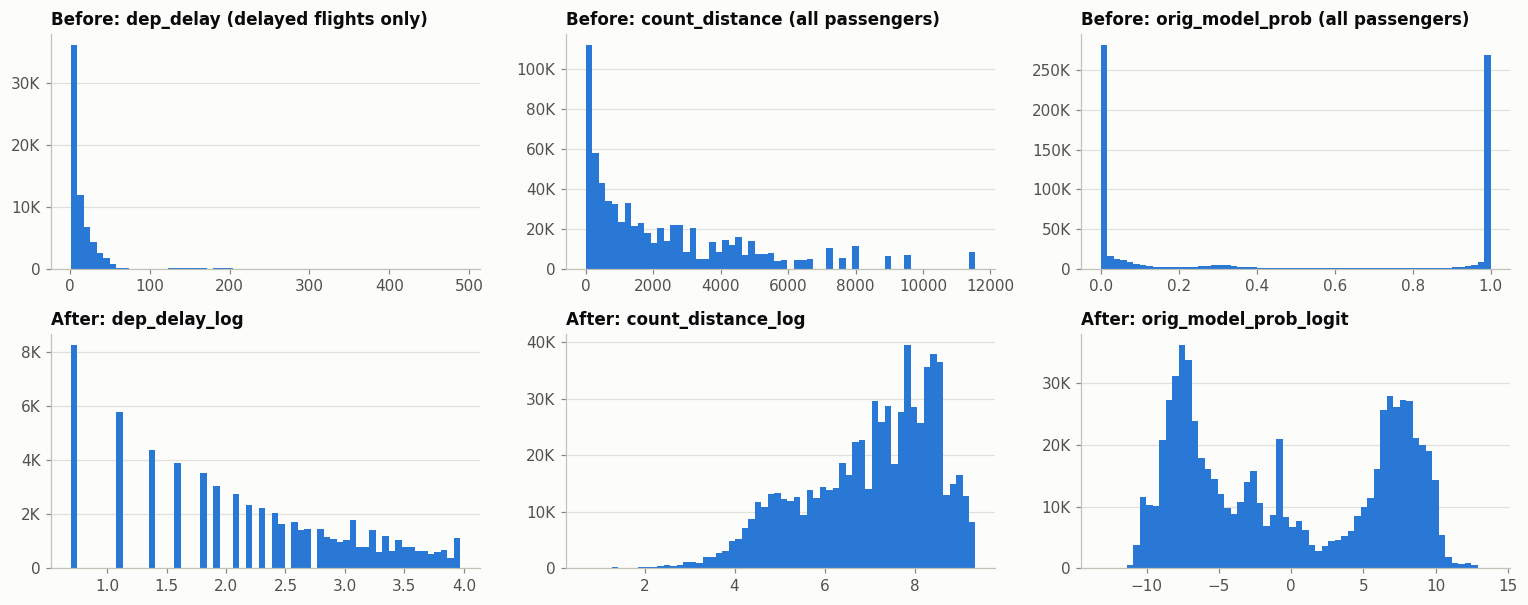

,skewness before,skewness after
dep_delay,12.87,3.62
arr_delay,13.34,3.63
count_distance,1.44,-0.67
count_distance_cabin_class,1.69,-0.49
orig_n_distance,1.27,-0.73


In [39]:
delayed = train_fe["dep_delay"] > 0
panels = [
    ("dep_delay", "dep_delay_log", delayed, "delayed flights only"),
    ("count_distance", "count_distance_log", slice(None), "all passengers"),
    ("orig_model_prob", "orig_model_prob_logit", slice(None), "all passengers"),
]

fig, axes = plt.subplots(2, 3, figsize=(14, 5.6))
for j, (before, after, rows, note) in enumerate(panels):
    axes[0, j].hist(train_fe.loc[rows, before], bins=60, color=BLUE)
    axes[0, j].set_title(f"Before: {before} ({note})")
    axes[1, j].hist(lin_train.loc[rows, after], bins=60, color=BLUE)
    axes[1, j].set_title(f"After: {after}")
    for ax in axes[:, j]:
        ax.yaxis.set_major_formatter(THOUSANDS)
        ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

skew_pairs = [("dep_delay", "dep_delay_log"), ("arr_delay", "arr_delay_log"), ("count_distance", "count_distance_log"),
              ("count_distance_cabin_class", "count_distance_cabin_class_log"), ("orig_n_distance", "orig_n_distance_log")]
pd.DataFrame({before: {"skewness before": train_fe[before].skew(), "skewness after": lin_train[after].skew()}
              for before, after in skew_pairs}).T.round(2)

**What this shows:**
- **Delays:** among delayed flights, most delays are a few minutes with a long tail up to 489. After capping and the log, the values spread more evenly, and skewness drops sharply (0 would be perfectly symmetric).
- **Counts:** the long right tail (a few distances shared by 11,000+ passengers) is pulled in.
- **`orig_model_prob`:** the probabilities pile up near 0 and 1 (half of them are below 0.001 or above 0.999). The logit spreads them out, so the difference between 0.99 and 0.9999 (a big difference in confidence) becomes visible to a linear model. The clipping limit is tiny (0.000001) so that this ranking survives.
- The gaps between the delay bars are there because delays are whole minutes.

Skewness of the delays stays high because 91% of them are still exactly 0. No transform can spread out identical values, which is why `delayed_15` keeps the "was there a delay?" information as a separate flag.

### 9.3 Encoding and scaling

The second step is a scikit-learn `ColumnTransformer`, which applies a different treatment to each group of columns:

| Block | Columns | Treatment |
|---|---|---|
| `onehot` | 4 categoricals, `travel_class`, `segment`, 13 ratings, 3 distance digits | one 0/1 column per value; two-value columns (e.g. `gender`) become a single 0/1 column |
| `age_onehot` | `age` | one 0/1 column per age; ages with fewer than 100 passengers (mostly over 70) share one column |
| `distance_bins` | `distance` | 20 bins with equal numbers of passengers, one 0/1 column each |
| `scaled` | all numeric columns | missing values filled with the median, then standardized to mean 0, std 1 |

Unlike `make_linear_frame()`, these steps **learn** from the data (the categories, the bin edges, the means and stds). They must therefore be fitted on training rows only. Here we fit on all of train just to inspect the result. In the training step this transformer goes inside a scikit-learn `Pipeline`, so that it's re-fitted on each fold's training part automatically.

In [40]:
ONEHOT_COLS = CATEGORICAL + ["travel_class", "segment"] + RATINGS + DIGIT_FEATURES
SCALED_COLS = [c for c in lin_train.columns if c not in ONEHOT_COLS + ["age", "distance"]]

linear_preprocessor = ColumnTransformer([
    ("onehot", OneHotEncoder(drop="if_binary", handle_unknown="infrequent_if_exist", dtype=np.float32), ONEHOT_COLS),
    ("age_onehot", OneHotEncoder(min_frequency=100, handle_unknown="infrequent_if_exist", dtype=np.float32), ["age"]),
    ("distance_bins", KBinsDiscretizer(n_bins=20, encode="onehot", strategy="quantile",
                                       quantile_method="averaged_inverted_cdf", subsample=None, dtype=np.float32), ["distance"]),
    ("scaled", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), SCALED_COLS),
])

X_lin_train = linear_preprocessor.fit_transform(lin_train)
X_lin_test = linear_preprocessor.transform(lin_test)
linear_feature_names = linear_preprocessor.get_feature_names_out()

def matrix_mb(X):
    return (X.data.nbytes + X.indices.nbytes + X.indptr.nbytes) / 1e6 if sparse.issparse(X) else X.nbytes / 1e6

print(f"Train: {lin_train.shape[1]} columns -> {X_lin_train.shape[1]} columns, {type(X_lin_train).__name__}, "
      f"{X_lin_train.dtype}, {matrix_mb(X_lin_train):.0f} MB")
print(f"Test:  {lin_test.shape[1]} columns -> {X_lin_test.shape[1]} columns, {matrix_mb(X_lin_test):.0f} MB")
pd.Series([name.split("__")[0] for name in linear_feature_names]).value_counts().rename("output columns").to_frame()

Train: 59 columns -> 252 columns, csr_matrix, float32, 322 MB
Test:  59 columns -> 252 columns, 138 MB


,output columns
onehot,131
age_onehot,66
scaled,35
distance_bins,20


**Why a sparse matrix?** Most of the new columns are one-hot 0/1 columns, and each passenger has a 1 in only one column per group. A sparse matrix stores only the non-zero values, which saves a lot of memory. Logistic regression and linear SVMs in scikit-learn accept it directly.

Sanity checks: no missing values, the scaled columns really have mean ≈ 0 and std ≈ 1, and each one-hot group has exactly one 1 per row.

In [41]:
scaled_idx = [i for i, name in enumerate(linear_feature_names) if name.startswith("scaled__")]
scaled_part = X_lin_train[:, scaled_idx].toarray()
print("Missing values in train / test:", int(np.isnan(X_lin_train.data).sum()), "/", int(np.isnan(X_lin_test.data).sum()))
print(f"Scaled columns: mean between {scaled_part.mean(axis=0).min():+.3f} and {scaled_part.mean(axis=0).max():+.3f}, "
      f"std between {scaled_part.std(axis=0).min():.3f} and {scaled_part.std(axis=0).max():.3f}")

rating_cols = [i for i, name in enumerate(linear_feature_names) if name.startswith("onehot__wifi_")]
print("wifi one-hot columns:", [linear_feature_names[i] for i in rating_cols])
print("Ones per row in the wifi group: min", int(X_lin_train[:, rating_cols].sum(axis=1).min()),
      "max", int(X_lin_train[:, rating_cols].sum(axis=1).max()))
print("Distance bin edges (miles):", np.round(linear_preprocessor.named_transformers_["distance_bins"].bin_edges_[0]).astype(int).tolist())

Missing values in train / test: 0 / 0


Scaled columns: mean between -0.000 and +0.000, std between 0.998 and 1.003
wifi one-hot columns: ['onehot__wifi_0', 'onehot__wifi_1', 'onehot__wifi_2', 'onehot__wifi_3', 'onehot__wifi_4', 'onehot__wifi_5']
Ones per row in the wifi group: min 1 max 1
Distance bin edges (miles): [67, 373, 508, 551, 591, 631, 680, 751, 842, 896, 954, 1041, 1189, 1464, 1620, 1814, 2240, 2519, 2933, 3408, 4983]


**One passenger, before and after.** The first train passenger in the tree-model data, and the same passenger in the linear-model data:

In [42]:
passenger = 0
print("BEFORE (tree-model data):")
print(train_fe.loc[passenger, RAW_FEATURES].to_string())

row = pd.Series(X_lin_train[passenger].toarray().ravel(), index=linear_feature_names)
active = row[row != 0]
print(f"\nAFTER (linear-model data): {len(row)} columns, {len(active)} of them non-zero for this passenger")
print("One-hot columns set to 1:", ", ".join(n.split("__")[1] for n in active.index if not n.startswith("scaled__")))
active[[n for n in active.index if n.startswith("scaled__")]].round(2).rename("standardized value").to_frame()

BEFORE (tree-model data):
age                             36
distance                       694
dep_delay                      0.0
arr_delay                      0.0
wifi                             4
time_convenient                  4
online_booking                   4
gate_location                    3
food_drink                       1
online_boarding                  4
seat_comfort                     1
entertainment                    1
onboard_service                  3
leg_room                         4
baggage                          4
checkin                          3
cleanliness                      1
gender                      Female
customer_type       Loyal Customer
travel_type        Personal Travel
cabin_class                    Eco

AFTER (linear-model data): 252 columns, 57 of them non-zero for this passenger
One-hot columns set to 1: travel_type_Personal Travel, cabin_class_Eco, travel_class_Personal Travel / Eco, segment_Loyal Customer / Personal Travel / Eco, wif

,standardized value
scaled__dep_delay_log,-0.29
scaled__arr_delay_log,-0.28
scaled__delay_change,0.01
scaled__rating_mean,-0.72
scaled__rating_std,0.76
scaled__rating_min,-0.89
scaled__n_zero_ratings,-0.22
scaled__n_low_ratings,0.15
scaled__n_top_ratings,-1.07
scaled__digital_mean,0.92


**How to read this:**
- **`gender` and `customer_type` aren't in the list of 1s.** For a two-value column only one 0/1 column is kept (`gender_Male`, `customer_type_disloyal Customer`), and 0 means the other value. So this passenger is a woman and a loyal customer.
- **Every rating value is now its own column:** `seat_comfort_1` = 1 means "gave seat comfort a 1".
- **`distance_6.0`** means distance bin number 6 (680–751 miles); her flight was 694 miles.
- **Standardized values are measured in standard deviations from the average passenger.** `comfort_mean` = −1.85 means her comfort ratings are far below average (seat comfort, entertainment, food and cleanliness are all 1). Values near 0 are typical.

### 9.4 What changed, in summary

| Before (tree data) | After (linear data) | Why |
|---|---|---|
| 4 text categoricals | one-hot (two-value columns → one 0/1 column) | linear models need numbers |
| no segment features (they didn't help the trees) | `travel_class` and `segment` one-hot | a linear model can't combine trip type and class by itself |
| 13 ratings as numbers 0–5 | 77 one-hot columns (one per rating value) | U-shapes and the 3→4 jump get their own weights; "0 = not rated" is its own column |
| 3 distance digits as numbers | 30 one-hot columns | a digit is a label, not an amount (digit 8 isn't "twice" digit 4) |
| `age` as a number | one column per age (rare ages, mostly over 70, grouped) | follows the hill shape and the steps at 40 and 61 |
| `distance` as a number | 20 equal-size bins | follows the jump around 1,500 miles |
| delays 0–489 min | capped at 52 / 49 min, log, standardized | extreme values no longer dominate; no rows removed |
| `total_delay` | dropped | exact sum of the two delays, so redundant |
| counts 1 to ~900k | log, standardized | comparable scale |
| original rates and model probability (0–1) | rates smoothed toward the average; then logit, standardized | matches the log-odds scale of logistic regression; tiny groups no longer give 0% / 100% |
| rating summaries | standardized | same scale as everything else |

The target encodings (7 columns) aren't included yet, because they're computed inside each CV fold. In the training step they'll get the same treatment as the other rates (logit, then scaling).

**Notes for the training step:**
- **SVM:** a classic kernel SVM (`SVC`) needs time that grows roughly with the square of the row count, so it's not feasible on 700k rows on this Mac. Use a **linear** SVM instead: `LinearSVC` or `SGDClassifier(loss="hinge")`. SVMs output scores, not probabilities, but AUC only needs the ranking, so `decision_function()` works for scoring. (Kaggle wants values in [0, 1], so the scores would be rescaled for submission.)
- **Correlated columns** (e.g. `wifi` and `online_booking`, 0.77) and the one-hot groups make some columns redundant. Regularization (`C` in both models) handles this, and it also keeps the weights stable.
- The model is wrapped as `Pipeline([("prep", linear_preprocessor), ("model", ...)])`, so every CV fold re-fits the encoders and scalers on its own training rows.

## 10. Model comparison: 11 more algorithms on the same folds (routine step 8)

Until now we only tried LightGBM. This section trains 11 other algorithms, from the simplest (naive Bayes) to the strongest (gradient boosting), so we can compare them fairly and find candidates for a blend.

**How it was built.** Five model families were developed in parallel by separate agents. Each tested its settings on a 50k-row sample (2 CPU threads, at most 2 tests at a time, to protect the laptop's 8 GB RAM). The full 699,635-row runs then went through a queue: **one family at a time**, each in a fresh process on all 8 cores, with a watchdog that would stop any run above 3.5 GB. The queue took ~50 minutes in total, and no run used more than 2.2 GB.

**Why the scores are comparable.** Every model uses:
- the same 5 folds;
- the same features (the run-08 tree features, or the section-9 linear data), both plus the 7 in-fold target encodings;
- the same helper `run_model_cv()`. It trains one model per fold, collects the out-of-fold predictions and saves them in `preds/`.

**Re-running this section** loads the saved predictions in seconds. Without them, it would retrain all 11 models inside this one kernel: ~50 minutes, and more RAM than the separate processes needed. The queue is the safer way to retrain.

In [43]:
N_JOBS = -1            # all CPU cores for every model
model_results = {}     # name -> scores, filled in by run_model_cv


def run_model_cv(name, fit_predict_fold):
    # fit_predict_fold(tr_idx, va_idx) trains on the fold's training rows and returns (valid predictions, test predictions)
    oof_path, test_path = PREDS / f"{name}-oof.npy", PREDS / f"{name}-test.npy"
    if oof_path.exists() and test_path.exists():
        oof, test_pred = np.load(oof_path), np.load(test_path)
        print(f"{name}: loaded saved predictions")
    else:
        oof, test_pred = np.zeros(len(y)), np.zeros(len(test_fe))
        start = time.time()
        for k, (tr_idx, va_idx) in enumerate(folds):
            fold_start = time.time()
            valid_pred, fold_test_pred = fit_predict_fold(tr_idx, va_idx)
            oof[va_idx] = valid_pred
            test_pred += np.asarray(fold_test_pred, dtype=float) / len(folds)
            print(f"  fold {k}: AUC {roc_auc_score(y[va_idx], valid_pred):.5f} ({time.time() - fold_start:.0f}s)")
        np.save(oof_path, oof)
        np.save(test_path, test_pred)
        print(f"{name}: trained in {time.time() - start:.0f}s")
    fold_auc = np.array([roc_auc_score(y[va_idx], oof[va_idx]) for _, va_idx in folds])
    model_results[name] = {"oof_auc": roc_auc_score(y, oof), "fold_auc": fold_auc}
    print(f"{name}: OOF AUC {model_results[name]['oof_auc']:.5f}, folds {fold_auc.mean():.5f} ± {fold_auc.std():.5f}")
    return oof, test_pred

### 10.1 Linear models: logistic regression and linear SVM

**What they are.** Both models give every column of the section-9 data a **weight** and add up weight x value for each
passenger. The sum is a single score: a large positive score means "probably satisfied", a large negative one "probably
not satisfied". Geometrically, the model draws one flat boundary (a hyperplane) through the ~260-dimensional space of
columns, and the score is how far, and on which side, a passenger lies from it.

The two models differ only in **how they choose the weights** during training:
- **Logistic regression** turns the score into a probability with the S-shaped sigmoid, 1 / (1 + e^(−score)), and picks
  the weights that make the observed labels as likely as possible (it minimizes *log loss*). Every passenger counts,
  and confidently wrong ones count the most.
- **Linear SVM** (support vector machine) looks for the boundary with the widest safety **margin** between the two
  classes. Passengers far on the correct side of the boundary are ignored; only those close to it or on the wrong side
  (the "support vectors") shape it. Its output is a distance from the boundary, **not a probability**.

Both are **regularized**: a penalty keeps the weights small, which gives a simpler and more stable model. Logistic
regression sets its strength with `C` (small `C` = strong penalty); the SVM below, trained with SGD, uses `alpha`
(large `alpha` = strong penalty).

**Strengths on this data:** training takes seconds instead of minutes, the result is easy to read (one weight per
column), and they make different kinds of mistakes than tree models, which is what a blend needs.
**Weaknesses:** a weighted sum can't discover interactions or curves by itself. Section 9 had to build them by hand
(one-hot ratings, age and distance bins, `travel_class`, `segment`), and whatever interactions we didn't build
are invisible to these models. So we expect an AUC below LightGBM's 0.9604; their value is as a *different* opinion
in the blend.

**Why not a kernel SVM (`SVC`)?** A kernel SVM can draw curved boundaries, but it compares every training row with
every other one: training time grows roughly with the *square* of the row count and memory with the number of support
vectors. On 560k training rows per fold that means hours and many GB of RAM, far beyond this 8 GB laptop. A **linear**
SVM skips the kernel and trains in seconds.

#### Shared setup: the preprocessor with target encodings, and the per-fold data

Section 9's `linear_preprocessor` has four blocks (one-hot, age one-hot, distance bins, scaled numbers). Here we add a
fifth block for the 7 **target encodings** (`te_*`), which are computed inside each fold by `add_target_encoding()`
so that validation and test rows never see their own labels.

A target encoding is the average satisfaction of a group (for example, all passengers with the same distance and
class), so it's a rate between 0 and 1, just like the original-data rates in section 9. It gets the same treatment:
**logit** (the log-odds scale a linear model works on), then **standardization** (mean 0, std 1).

Why these settings:
- `clone(linear_preprocessor)` gives fresh, unfitted copies of the four blocks, so nothing learned elsewhere in the
  notebook leaks in. Inside each fold, the whole preprocessor is cloned again and fitted on that fold's training rows.
- `sparse_threshold=1.0` makes the result always a **sparse** matrix: each row has ~260 columns but only ~64 non-zero
  values (most are one-hot zeros). Storing only the non-zeros keeps a fold's training matrix near 300 MB instead of
  ~600 MB as a dense float32 array.

In [44]:
import gc

from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.preprocessing import FunctionTransformer

# Section 9's four blocks unchanged, plus one block for the 7 in-fold target encodings
te_block = make_pipeline(FunctionTransformer(logit, feature_names_out="one-to-one"), StandardScaler())
linear_te_preprocessor = ColumnTransformer(
    clone(linear_preprocessor).transformers + [("target_enc", te_block, TE_FEATURES)],
    sparse_threshold=1.0,   # always sparse: only ~64 of ~260 values per row are non-zero
)


def linear_fold_data(tr_idx, va_idx):
    # Target encodings are fitted on this fold's training rows only, then applied to validation and test rows
    return add_target_encoding(lin_train.iloc[tr_idx], y[tr_idx], lin_train.iloc[va_idx], lin_test,
                               te_keys_train.iloc[tr_idx], te_keys_train.iloc[va_idx], te_keys_test)

#### Logistic regression (experiment 09)

Settings and why:
- `C=0.1`: moderate regularization. In smoke tests `C` between 0.03 and 1 changed the AUC by only 0.0002, because ~260
  columns are few compared with hundreds of thousands of rows. 0.03 and 0.1 tied for best, and smaller values also
  converge in fewer iterations.
- `solver="lbfgs"` (the default): on this sparse data it was the fastest of the four solvers we timed (lbfgs,
  newton-cholesky, liblinear, saga). All four reached the same AUC, so speed decided; saga was ~20x slower.
- `max_iter=1000`: lbfgs needed 50–75 iterations in the smoke tests, and more rows tend to need more; the default
  limit of 100 would be cut close on the full data and print a `ConvergenceWarning`, so we leave plenty of room.
  It stops as soon as it has converged, so the higher limit costs nothing.
- No `n_jobs`: a two-class lbfgs fit runs on one core anyway. It's fast enough that this doesn't matter: about
  1–2 minutes for all 5 folds on the full data, adding roughly 1–1.3 GB of RAM on top of the data (most of it is the
  temporary copies made while the preprocessor builds the sparse matrix).

`predict_proba(...)[:, 1]` gives the probability of "satisfied", which can be blended or submitted directly. The
pipeline and data frames are deleted at the end of each fold so their memory is freed before the next one.

In [45]:
def logreg_fold(tr_idx, va_idx):
    X_tr, X_va, X_te = linear_fold_data(tr_idx, va_idx)
    model = make_pipeline(clone(linear_te_preprocessor),
                          LogisticRegression(C=0.1, max_iter=1000, random_state=SEED))
    model.fit(X_tr, y[tr_idx])
    valid_pred, test_pred = model.predict_proba(X_va)[:, 1], model.predict_proba(X_te)[:, 1]
    del model, X_tr, X_va, X_te
    gc.collect()
    return valid_pred, test_pred


logreg_oof, logreg_test = run_model_cv("09-logreg", logreg_fold)

09-logreg: loaded saved predictions


09-logreg: OOF AUC 0.95728, folds 0.95728 ± 0.00057


#### Linear SVM (experiment 10)

We train the linear SVM with scikit-learn's `SGDClassifier(loss="hinge")`. It's the same model as a classic linear SVM:
the **hinge loss** is exactly the SVM's "widest margin" objective. Only the training method differs.
**Stochastic gradient descent (SGD)** walks through the training rows in random order and nudges the weights a little
after each row, passing over the data several times until the weights stop changing.

Why SGD instead of `LinearSVC` (the exact liblinear solver):
- **Memory.** `LinearSVC` copies the whole training matrix twice (to float64, then into its own format), which would
  push this run to ~2.7 GB, right at the laptop's limit. SGD works on the sparse matrix directly: about 1 GB less.
- **Score.** In the smoke tests SGD with plain hinge loss scored slightly *higher* (0.95530) than `LinearSVC`
  (0.95508, which uses the squared hinge loss).

Settings and why:
- `alpha=1e-4`: the regularization strength (SGD's version of `C`, where a *larger* alpha means *stronger*
  regularization). With 1e-4 the weights settle within the allowed passes; a weaker 1e-5 scored a bit higher in the
  smoke test but didn't converge, so we keep the setting that is stable.
- `average=True`: the final weights are the average over all the small updates, which smooths out SGD's zig-zagging
  and makes the result as stable as an exact solver's.
- `max_iter=200`, `tol=1e-4`: at most 200 passes over the data, stopping early once the loss stops improving.
  With 560k rows per fold, a few passes are usually enough.
- `random_state=SEED`: SGD shuffles the rows, and a fixed seed makes every run identical.

**SVM scores are not probabilities.** `decision_function()` returns the signed distance from the boundary. AUC only
looks at the *ranking* of passengers, so these scores are fine for CV and for blending by rank. Kaggle needs values in
[0, 1], so for a submission the scores would first be rescaled (for example with a rank transform, or a sigmoid fitted
on the out-of-fold predictions).

In [46]:
def svm_fold(tr_idx, va_idx):
    X_tr, X_va, X_te = linear_fold_data(tr_idx, va_idx)
    model = make_pipeline(clone(linear_te_preprocessor),
                          SGDClassifier(loss="hinge", alpha=1e-4, average=True, max_iter=200, tol=1e-4,
                                        random_state=SEED))
    model.fit(X_tr, y[tr_idx])
    # Signed distance from the boundary: a ranking score, not a probability
    valid_pred, test_pred = model.decision_function(X_va), model.decision_function(X_te)
    del model, X_tr, X_va, X_te
    gc.collect()
    return valid_pred, test_pred


svm_oof, svm_test = run_model_cv("10-linear-svm", svm_fold)

10-linear-svm: loaded saved predictions


10-linear-svm: OOF AUC 0.95588, folds 0.95589 ± 0.00062


### 10.2 Simple models: decision tree, k-nearest neighbours, naive Bayes

Three classic models that are much simpler than gradient boosting. We don't expect them to beat LightGBM
(OOF AUC 0.9604). We train them for two reasons: they show *how* different kinds of models decide, and because
they make different mistakes than boosting, their predictions might still help in a blend later.

| Model | How it decides | Strength on this data | Weakness on this data |
|---|---|---|---|
| **Decision tree** | Asks a chain of yes/no questions ("online_boarding ≥ 4?", "travel_type = Business?") and predicts the share of satisfied passengers in the final group (leaf). | Fast, handles categories, missing values and interactions on its own; easy to read. | One tree is coarse: every passenger in a leaf gets the same probability, so the ranking (and AUC) is blocky. Boosting fixes this by adding hundreds of trees. |
| **k-nearest neighbours (KNN)** | Finds the *k* training passengers most similar to a new passenger and predicts the share of them who were satisfied. | No training assumptions at all: it just copies what similar passengers did. | Every prediction is compared with every training row, so it is slow on 700k rows; it depends on how "distance" is measured. |
| **Naive Bayes** | Learns, separately for every feature, how common each value is among satisfied vs. unsatisfied passengers, then multiplies this evidence together. | Very fast; needs little data per feature. | Assumes the features are *independent* given the target, so correlated features (13 ratings, many look-ups of the same column) are counted twice. |

Smoke tests showed one more pattern: **each model needs a different version of the data**. The tree uses the tree
features plus target encodings, KNN uses a compressed version of the linear-model features, and naive Bayes uses a
short list of features turned into categories.

#### Shared imports and a helper for categories

`DecisionTreeClassifier` in scikit-learn only accepts numbers, so `with_codes` replaces the 4 pandas `category`
columns with their integer codes (Female = 0, Male = 1, ...). This is fine for a tree: it can split on
`cabin_class ≤ 0` to separate Business from the rest. The original-data lookup columns (`orig_*`) have a few NaNs.
Trees in scikit-learn ≥ 1.3 handle missing values on their own (at each split they also learn which side
missing rows should go to), so we don't impute them.

In [47]:
from sklearn.decomposition import TruncatedSVD
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import CategoricalNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import KBinsDiscretizer, OrdinalEncoder
from sklearn.tree import DecisionTreeClassifier


def with_codes(X):
    # sklearn trees need numbers: category -> integer code (the tree can still split categories apart)
    X = X.copy()
    for col in CATEGORICAL:
        X[col] = X[col].cat.codes.astype("int8")
    return X

#### 11 · Decision tree

**Settings.** The tree uses the 46 tree features plus the 7 in-fold target encodings, so it sees the same
information as our LightGBM. The important setting is how big the tree may grow:
- A deep tree with tiny leaves memorises noise. On a 40k-row smoke sample, `min_samples_leaf = 25` scored 0.9456.
- Limiting the depth instead (`max_depth = 8`: 0.9443, `max_depth = 12`: 0.9506) cuts some useful branches too.
- **`min_samples_leaf = 500`** (no depth limit) scored best (0.9545). Each leaf then averages at least 500
  passengers, so its probability is stable. We got the same best leaf size on a 20k-row sample, so the best size
  seems to depend little on the amount of data. On the full data the tree can therefore grow more leaves (about
  1,000 instead of 60), which gives a finer ranking.

**Cost.** A single tree uses one CPU core. Fitting it on 560k rows takes seconds, and the whole 5-fold run
should take about 1–2 minutes and add only a few hundred MB of RAM (the fold's feature matrices).

In [48]:
def tree_fold(tr_idx, va_idx):
    X = with_codes(train_fe[MODEL_FEATURES])
    X_tr, X_va, X_te = add_target_encoding(X.iloc[tr_idx], y[tr_idx], X.iloc[va_idx], with_codes(test_fe[MODEL_FEATURES]),
                                           te_keys_train.iloc[tr_idx], te_keys_train.iloc[va_idx], te_keys_test)
    # Big leaves = each probability is an average over >= 500 passengers (less noise, better ranking)
    model = DecisionTreeClassifier(min_samples_leaf=500, random_state=SEED).fit(X_tr, y[tr_idx])
    return model.predict_proba(X_va)[:, 1], model.predict_proba(X_te)[:, 1]


tree_oof, tree_test = run_model_cv("11-decision-tree", tree_fold)

11-decision-tree: loaded saved predictions


11-decision-tree: OOF AUC 0.95713, folds 0.95712 ± 0.00044


#### 12 · k-nearest neighbours (KNN)

**The cost problem.** KNN has no real training step. To predict one passenger it measures the distance to
*every* training passenger and keeps the *k* closest. On the full data that is 560k training rows × 440k rows to
predict (140k validation + 300k test) per fold: about 250 billion distances on 252 columns, which would take hours.
Three choices make it fit our budget (≤ 15 min, ≤ 3 GB):

1. **A small dense space.** We reuse the linear-model preprocessing (one-hot columns + standardized numbers,
   252 sparse columns) and compress it with `TruncatedSVD` to **64 columns**. SVD is like PCA for sparse data:
   it keeps the directions in which passengers differ most (here 92% of the variance). In smoke tests 64
   columns scored the same as all 252 columns (16 columns: −0.003 AUC) while using 4× less memory.
2. **Fewer training rows.** Each fold's KNN uses a stratified random sample of **200k** of its 560k training rows
   (the satisfied share stays the same). This is the main trade-off: in smoke tests every doubling of training
   rows added about +0.0015 AUC, so using all 560k rows would probably add about +0.002 more. But the cost grows
   in proportion to the number of rows, and with all of them the run would come close to the 15-minute limit.
3. **Predicting in chunks** of 20k rows, so the table of neighbours (rows × k) never needs much RAM at once.

**Choosing k.** A small *k* gives noisy probabilities, while a large *k* blurs in passengers who aren't really
similar. The best *k* grows with the number of training rows: 35 for 10k rows, 50 for 20k, and about 80 for 40k.
The classic rule of thumb `k ≈ √n` fits this well as **k = 0.4·√n**, which gives 80 on the smoke sample and 179 on
the 200k full-data sample. `weights="distance"` lets closer neighbours count more (a small but steady gain).
We use `algorithm="brute"` (plain distance calculation on all cores), because in 64 dimensions it was faster
than the tree-based search methods (`kd_tree`, `ball_tree`).

In [49]:
KNN_TRAIN_ROWS = 200_000    # time grows with (training rows x predicted rows), so cap the training rows
KNN_DIMS = 64               # SVD columns: same AUC as all 252 columns in smoke tests, 4x less memory


def predict_in_chunks(model, X, chunk_rows=20_000):
    # The neighbour table is (rows x k); chunks keep it small
    return np.concatenate([model.predict_proba(X.iloc[start:start + chunk_rows])[:, 1]
                           for start in range(0, len(X), chunk_rows)])


def knn_fold(tr_idx, va_idx):
    if len(tr_idx) > KNN_TRAIN_ROWS:
        tr_idx, _ = train_test_split(tr_idx, train_size=KNN_TRAIN_ROWS, stratify=y[tr_idx], random_state=SEED)
    n_neighbors = round(0.4 * np.sqrt(len(tr_idx)))       # best k grows with the data: 80 on 40k rows, 179 on 200k
    model = make_pipeline(clone(linear_preprocessor),
                          TruncatedSVD(n_components=KNN_DIMS, random_state=SEED),
                          KNeighborsClassifier(n_neighbors=n_neighbors, weights="distance", algorithm="brute", n_jobs=N_JOBS))
    model.fit(lin_train.iloc[tr_idx], y[tr_idx])
    return predict_in_chunks(model, lin_train.iloc[va_idx]), predict_in_chunks(model, lin_test)


knn_oof, knn_test = run_model_cv("12-knn", knn_fold)

12-knn: loaded saved predictions


12-knn: OOF AUC 0.95167, folds 0.95168 ± 0.00059


#### 13 · Naive Bayes

**The idea.** For every feature, naive Bayes counts how often each value appears among satisfied and among
unsatisfied passengers (for example, how much more common online_boarding = 5 is among satisfied passengers). To predict, it
multiplies these ratios across all features. The *naive* part is the **independence assumption**: it acts as if,
once we know whether a passenger is satisfied, their features tell us nothing about each other. That is false here,
because a passenger who rates wifi highly usually also rates online booking highly. So correlated features
count as several separate pieces of evidence, and the model becomes overconfident.

**Which version.** `CategoricalNB` works on categories, so every feature must be one:
- the 13 ratings (0–5) and the 4 categoricals stay as they are;
- age, distance, the two delays and `orig_model_prob` are cut into 40 equal-count bins (`KBinsDiscretizer`;
  20 bins scored 0.0002 lower, and the full data has 14× more rows per bin, so 40 bins are safe).

In smoke tests the **choice of features mattered more than the type of naive Bayes**. With all 46 tree features, the
counts and the many `orig_*` lookups repeat the same information about age and distance, so they get
counted several times: AUC 0.922. With this short list: **0.945**. Other versions scored lower: Bernoulli NB on the
one-hot features 0.926, multinomial NB 0.931, Gaussian NB on the standardized numbers 0.915. `orig_model_prob`
adds a lot (without it: 0.931), because it already packs many correlated features into one number.

**Cost.** Naive Bayes only counts values, so the full run takes seconds and almost no RAM.

In [50]:
import warnings

NB_BINNED = ["age", "distance", "dep_delay", "arr_delay", "orig_model_prob"]   # short list: fewer double-counted features
NB_BINS = 40
# Over half of the delays are 0 (and ages are whole numbers), so several quantile edges coincide.
# KBinsDiscretizer merges those empty bins, which is what we want, but warns once per fold; hide only that warning.
warnings.filterwarnings("ignore", message="Bins whose width are too small")


def bayes_fold(tr_idx, va_idx):
    to_categories = ColumnTransformer([
        ("as_is", OrdinalEncoder(), RATINGS + CATEGORICAL),
        ("binned", make_pipeline(SimpleImputer(strategy="median"),
                                 KBinsDiscretizer(n_bins=NB_BINS, encode="ordinal", strategy="quantile",
                                                  quantile_method="averaged_inverted_cdf", subsample=None)), NB_BINNED),
    ])
    # min_categories: every column gets room for NB_BINS values, so a value seen only in valid/test can't crash it
    model = make_pipeline(to_categories, CategoricalNB(min_categories=NB_BINS))
    model.fit(train_fe.iloc[tr_idx], y[tr_idx])
    return model.predict_proba(train_fe.iloc[va_idx])[:, 1], model.predict_proba(test_fe)[:, 1]


bayes_oof, bayes_test = run_model_cv("13-naive-bayes", bayes_fold)

13-naive-bayes: loaded saved predictions


13-naive-bayes: OOF AUC 0.94578, folds 0.94578 ± 0.00035


### 10.3 Bagging ensembles: random forest and extra trees

**Bagging** = *bootstrap aggregating*: train many decision trees, each on a slightly different random version of the
training data, and average their predicted probabilities. One deep tree memorises noise (high variance); the average
of hundreds of different deep trees keeps the signal and cancels much of the noise.

- **Random forest (RF)**: every tree sees a random sample of the rows (drawn with replacement), and at every split it
  may only look at a random subset of the features. Within that subset it picks the *best* threshold.
- **Extra trees (ET, "extremely randomized trees")**: also random feature subsets, but the threshold of each candidate
  split is drawn *at random* and only the best of those random splits is kept. Even more randomness: each tree is
  weaker, but the trees disagree more, so averaging helps more; and each candidate split is cheaper to evaluate
  because nothing has to be sorted.

How they decide: a tree asks yes/no questions (`online_boarding <= 3?`, `travel_type == business?`) until a leaf; the
leaf's share of satisfied training passengers is that tree's probability. The forest averages these over all trees.

On this data: trees handle the 0-5 ratings, the categoricals and the count/lookup features without scaling, and missing
values are handled natively. Unlike boosting (LightGBM), each tree is grown independently and never corrects the
errors of the others, so bagging usually scores a bit lower than a tuned gradient-boosting model. Its value for us is
**diversity**: its errors differ from LightGBM's, which can help a blend. Its weak spot is the laptop: deep trees on
560k rows are big, so RAM needs care (see below).

**Fold data for the forests.** Same inputs as the LightGBM model: the 46 run-08 features plus the 7 target
encodings, fitted inside each fold on the fold's training rows only (no leakage). Two small conversions:
- the 4 pandas `category` columns become integer codes (0, 1, 2): a tree only needs an order to split on, and with
  2-3 levels any grouping is reachable with one or two splits;
- everything becomes one `float32` NumPy array, the type sklearn's trees use internally, so sklearn does not make
  another copy of the 560k-row matrix.

Missing values (`arr_delay`, and the `orig_*` lookups in test) stay `NaN`: since scikit-learn 1.4 (random forest) and
1.6 (extra trees) the trees learn at each split which side missing values should go to, so no imputation is needed.

In [51]:
import gc
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier


def bagging_fold_data(tr_idx, va_idx):
    # Run-08 features + in-fold target encodings, returned as float32 arrays (train, valid, test)
    X_tr, X_va, X_te = add_target_encoding(
        train_fe[MODEL_FEATURES].iloc[tr_idx], y[tr_idx], train_fe[MODEL_FEATURES].iloc[va_idx], test_fe[MODEL_FEATURES],
        te_keys_train.iloc[tr_idx], te_keys_train.iloc[va_idx], te_keys_test)
    arrays = []
    for X in (X_tr, X_va, X_te):
        X[CATEGORICAL] = X[CATEGORICAL].apply(lambda col: col.cat.codes)   # trees only need an order: 0, 1, 2
        arrays.append(X.to_numpy(dtype=np.float32, na_value=np.nan))        # NaN stays NaN; trees route it themselves
    return arrays

**Why RAM is the main risk, and how we keep it under control.**

A fitted sklearn tree stores every node as an 80-byte record (64 bytes for children, feature, threshold, counts,
plus 16 bytes for the two class counts). A tree grown until its leaves are tiny has roughly
`rows it sees / leaf size` leaves, so **tree size grows linearly with the number of training rows**. We measured it
on the smoke folds (nodes per tree):

| forest | 20k training rows | 40k training rows | full fold, 560k rows (x14) | 300 trees |
|---|---|---|---|---|
| RF, sklearn defaults (fully grown) | - | 5,760 | ~81k nodes = 6.5 MB | **1.9 GB** |
| RF, our settings | 682 | 1,330 | ~18.6k nodes = 1.5 MB | 450 MB |
| ET, sklearn defaults (fully grown) | - | 13,900 | ~195k nodes = 15.6 MB | **4.7 GB** |
| ET, our settings | 1,130 | 2,249 | ~31.5k nodes = 2.5 MB | 760 MB |

Doubling the rows doubled the nodes (x1.95 for RF, x1.99 for ET), so a linear extrapolation is safe.

So default forests would not fit next to the ~1 GB of data on an 8 GB laptop with only about 2.5 GB free.
The knobs we use:
- `min_samples_leaf` (10 for RF, 20 for ET): stop splitting when a leaf would get fewer rows. Fewer, larger leaves =
  smaller trees, and on noisy labels averaged probabilities from 10-20 passengers rank better than 1-passenger leaves.
- `max_samples=0.5` (RF only): each tree is grown on a bootstrap sample of half the rows: half the size, twice as fast,
  and more variety between trees. Extra trees use every row (their randomness comes from the random thresholds).
- **Training in batches.** A forest's probability is just the average of its trees' probabilities, so 3 forests of
  100 trees with different seeds, averaged, are exactly one 300-tree forest. We fit one batch, predict validation and
  test, delete it, then fit the next: only 100 trees (about 150 MB for RF, 250 MB for ET on a full fold) are ever
  in RAM. More trees cost time, not memory.
- Test predictions need no chunking: each tree returns a 300k x 2 array (5 MB) that is added into a running sum.

The helper prints the size of each fold's first batch, so the full run shows that the estimate held.

In [52]:
def forest_mb(forest):
    # Memory of the fitted trees: every node is one record in tree_.__getstate__()["nodes"] plus its class counts
    return sum(t.tree_.__getstate__()["nodes"].nbytes + t.tree_.value.nbytes for t in forest.estimators_) / 1e6


def fit_forest_in_batches(make_forest, n_batches, X_tr, y_tr, X_va, X_te):
    # Averaging n_batches forests (different seeds) = one forest with all their trees, but only one batch is ever in RAM
    va_pred, te_pred = np.zeros(len(X_va)), np.zeros(len(X_te))
    for batch in range(n_batches):
        forest = make_forest(random_state=SEED + batch).fit(X_tr, y_tr)
        va_pred += forest.predict_proba(X_va)[:, 1] / n_batches
        te_pred += forest.predict_proba(X_te)[:, 1] / n_batches
        if batch == 0:
            nodes = sum(t.tree_.node_count for t in forest.estimators_)
            print(f"    batch of {len(forest.estimators_)} trees: {nodes / len(forest.estimators_):,.0f} nodes per tree, "
                  f"{forest_mb(forest):.0f} MB", flush=True)
        del forest
        gc.collect()
    return va_pred, te_pred

**Random forest (experiment 14).** Settings, chosen on the smoke folds (paired per-fold comparisons):
- `criterion="entropy"`: splits chosen by information gain instead of Gini impurity. It beat Gini on all 5 smoke folds
  (+0.0007 AUC) at the same speed: the probabilities it produces rank passengers slightly better.
- `max_features="sqrt"`: each split looks at about 7 of the 53 features. Looking at 30% of them was no better and
  took twice as long.
- `min_samples_leaf=10`, `max_samples=0.5`: see the RAM cell; leaf sizes 5-20 scored the same, 2 or 40 were worse.
- 3 batches x 100 trees = 300 trees: 500 trees scored the same on the smoke folds.

Expected on the full data (8 cores): about 5 minutes for the 5 folds (time grows a little faster than the rows,
x2.2 per doubling), peak RAM about 2 GB.

In [53]:
def make_random_forest(random_state):
    return RandomForestClassifier(n_estimators=100, criterion="entropy", max_features="sqrt", min_samples_leaf=10,
                                  max_samples=0.5, n_jobs=N_JOBS, random_state=random_state)


def rf_fold(tr_idx, va_idx):
    X_tr, X_va, X_te = bagging_fold_data(tr_idx, va_idx)
    return fit_forest_in_batches(make_random_forest, 3, X_tr, y[tr_idx], X_va, X_te)


rf_oof, rf_test = run_model_cv("14-random-forest", rf_fold)

14-random-forest: loaded saved predictions


14-random-forest: OOF AUC 0.95959, folds 0.95959 ± 0.00041


**Extra trees (experiment 15).** Settings, chosen on the smoke folds:
- `max_features=0.5`: each split draws one random threshold for each of half the features (26) and keeps the best.
  Because the thresholds are random, ET needs more candidate features than RF to find good splits; with leaf 20 it
  beat `"sqrt"` (about 7 features) by +0.0005 AUC, at about 2.5x the training time.
- `min_samples_leaf=20`: random thresholds make deeper trees (a node needs more cuts to become pure), so a larger
  leaf keeps the size in check; 20 beat 10 on all 5 smoke folds, 40 was worse.
- No bootstrap (sklearn's default for ET): every tree sees all training rows. Bootstrapping half the rows was
  slightly worse.
- Gini criterion (default): entropy gave no gain here. 3 batches x 100 trees = 300 trees.

Expected on the full data (8 cores): about 8 minutes for the 5 folds (26 candidate features per split make it
slower than RF here), peak RAM about 2 GB.

In [54]:
def make_extra_trees(random_state):
    return ExtraTreesClassifier(n_estimators=100, max_features=0.5, min_samples_leaf=20,
                                n_jobs=N_JOBS, random_state=random_state)


def et_fold(tr_idx, va_idx):
    X_tr, X_va, X_te = bagging_fold_data(tr_idx, va_idx)
    return fit_forest_in_batches(make_extra_trees, 3, X_tr, y[tr_idx], X_va, X_te)


et_oof, et_test = run_model_cv("15-extra-trees", et_fold)

15-extra-trees: loaded saved predictions


15-extra-trees: OOF AUC 0.95980, folds 0.95981 ± 0.00035


### 10.4 Gradient boosting: LightGBM (tuned), XGBoost, HistGradientBoosting

**What these models are.** Gradient boosting builds a long chain of small decision trees. The first tree makes a rough
guess; every next tree is trained to fix the mistakes the chain still makes (it fits the gradient of the log loss).
The final prediction is the sum of all trees, turned into a probability. The *learning rate* shrinks each tree's
contribution: a smaller rate means smaller, more careful steps and more trees. *Early stopping* watches the AUC
(or loss) on held-out rows and stops adding trees once it stops improving.

**The three libraries** all use the same idea and the same speed trick (they bin each feature into ≤ 256 buckets and
search splits on histograms), but they grow trees differently, which gives them slightly different errors:
- **LightGBM** grows trees *leaf-wise*: it always splits the leaf with the biggest gain, so trees are lopsided and deep
  where the data needs it. Fastest of the three here.
- **XGBoost** (with `tree_method="hist"`) grows trees *depth-wise*: it fills each level before going deeper, which
  gives more balanced trees. A bit slower, but its errors differ from LightGBM's, which helps a blend.
- **HistGradientBoosting** is scikit-learn's own LightGBM-style booster. It has no row subsampling, so it is the least
  random of the three; it is mainly here as a cheap, dependency-free third opinion.

**Why they suit this data.** Boosted trees are the strongest single models on tabular data like ours: they handle
mixed types, missing values (NaN in the `orig_rate_*` test lookups), the 0 = "not rated" rating value, and
interactions such as *rating × class × type of travel* without any scaling. All three read our 4 pandas `category`
columns natively. **Weaknesses:** they need a few settings chosen with care, and the three models are highly correlated
with each other, so their value in a blend comes from small differences.

**Inputs.** All three use the tree feature set from section 8 (`train_fe[MODEL_FEATURES]`, 46 columns) plus the 7
target encodings, which are fitted inside each fold on the training rows only (`add_target_encoding`), so no
validation label leaks into the features.

**Note on early stopping.** Each model stops adding trees when the score on the *validation fold* stops improving.
That fold therefore helped choose one setting (the number of trees), so its score is very slightly optimistic. With
140k validation rows the effect is tiny, and it is the same for all models, so the comparison stays fair.

**Shared fold inputs.** `gb_fold_inputs` cuts out one fold's training, validation and test frames and appends the
7 in-fold target encodings. All three models call it, so they see exactly the same inputs. Selecting
`MODEL_FEATURES` explicitly keeps any extra notebook columns out of the models. The frames stay in their compact
dtypes (`int8`/`float32`/`category`): a full fold is about 560k × 53 values, roughly 0.2 GB for train + valid + test.

In [55]:
import gc

import lightgbm as lgb
import xgboost as xgb
from sklearn.ensemble import HistGradientBoostingClassifier


def gb_fold_inputs(tr_idx, va_idx):
    # Target encodings are fitted on this fold's training rows only, then applied to the valid and test rows
    return add_target_encoding(train_fe[MODEL_FEATURES].iloc[tr_idx], y[tr_idx],
                               train_fe[MODEL_FEATURES].iloc[va_idx], test_fe[MODEL_FEATURES],
                               te_keys_train.iloc[tr_idx], te_keys_train.iloc[va_idx], te_keys_test)

#### 16 · LightGBM, tuned

Starting point: the section-8 model (learning rate 0.1, 63 leaves, 80% rows and 80% columns per tree, OOF AUC 0.96041).
We change only things that are known to help on large data, because the smoke test (40k rows per fold) cannot measure
gains of 0.0001–0.0005 reliably, and settings that win on 40k rows (e.g. smaller trees) often lose on 560k rows.

- **`learning_rate` 0.1 → 0.03** (the main change). Smaller steps mean the ensemble averages over ~3x more trees, which
  smooths out the noise of individual trees; on big tabular data this usually adds a few ten-thousandths of AUC.
  Cost: ~3x more trees, which is affordable because LightGBM builds a 560k-row tree in ~15 ms on 8 cores.
- **Early-stopping patience 100 → 300 rounds**, scaled with the learning rate: 300 rounds at 0.03 cover about the
  same distance as 100 rounds at 0.1, so a slow stretch is not mistaken for the end.
- **`min_child_samples` 20 → 50 and `reg_lambda` 0 → 1**: a light brake on tiny leaves and extreme leaf values.
  At 560k rows these limits rarely bind, so they are a safety margin rather than a big change.
- **Kept:** `num_leaves=63` (127 leaves was worse in the smoke test and is a bigger, riskier change), `subsample=0.8`
  and `colsample_bytree=0.8` (0.5 columns was not better in the smoke test).
- `n_estimators=8000` is only a ceiling: early stopping should end each fold far earlier. The printout shows the tree
  count per fold, so you can see whether the ceiling was ever reached.

Budget: about 2–6 min for 5 folds on 8 cores (worst case, if no fold stops early: ~14 min); peak RAM about 1.8 GB,
most of it the data that is already loaded.

In [56]:
LGB_TUNED_PARAMS = dict(n_estimators=8000, learning_rate=0.03, num_leaves=63, min_child_samples=50, reg_lambda=1.0,
                        subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                        random_state=SEED, verbose=-1, n_jobs=N_JOBS)


def lgb_tuned_fold(tr_idx, va_idx):
    X_tr, X_va, X_te = gb_fold_inputs(tr_idx, va_idx)
    model = lgb.LGBMClassifier(**LGB_TUNED_PARAMS)
    # Patience 300 at learning rate 0.03 ≈ patience 100 at 0.1; predictions then use the best iteration
    model.fit(X_tr, y[tr_idx], eval_X=X_va, eval_y=y[va_idx], eval_metric="auc",
              callbacks=[lgb.early_stopping(300, verbose=False)])
    print(f"  best iteration {model.best_iteration_:,} of {LGB_TUNED_PARAMS['n_estimators']:,}")
    preds = model.predict_proba(X_va)[:, 1], model.predict_proba(X_te)[:, 1]
    del model, X_tr, X_va, X_te
    gc.collect()
    return preds


oof_lgb_tuned, test_lgb_tuned = run_model_cv("16-lightgbm-tuned", lgb_tuned_fold)

16-lightgbm-tuned: loaded saved predictions


16-lightgbm-tuned: OOF AUC 0.96075, folds 0.96075 ± 0.00058


#### 17 · XGBoost

XGBoost with the histogram method and native categorical support (`enable_categorical=True` reads the pandas
`category` columns directly). Settings and why:

- **`max_depth=7`, depth-wise growth**: balanced trees with up to 128 leaves. This differs on purpose from LightGBM's
  leaf-wise trees, so the two models make different mistakes. Depth 6 scored about the same in the smoke test, but
  deeper trees usually pay off at 560k rows.
- **`learning_rate=0.05`**: XGBoost's depth-wise trees take ~2.5x longer per tree than LightGBM's here (~40 ms on
  8 cores), so 0.05 keeps the run well inside the 15-min budget. In the smoke test 0.03 scored the same.
- **`subsample=0.8`, `colsample_bytree=0.6`**: each tree sees 80% of rows and 60% of columns. The randomness
  decorrelates the trees and makes XGBoost's errors less similar to LightGBM's.
- **`min_child_weight=2`, `reg_lambda=1`**: mild limits on tiny leaves (close to XGBoost's defaults).
- **Early stopping**: in xgboost 3.x, `eval_metric` and `early_stopping_rounds` are set in the constructor; `predict_proba`
  then uses the best iteration automatically. Patience 200 at 0.05 ≈ 100 at 0.1.
- `n_estimators=3500` is a ceiling chosen so that even a run that never stops early stays under ~15 min.

Budget: about 3–9 min for 5 folds on 8 cores (worst case, if no fold stops early: ~14 min); peak RAM about 1.8 GB.

In [57]:
XGB_PARAMS = dict(n_estimators=3500, learning_rate=0.05, max_depth=7, min_child_weight=2, reg_lambda=1.0,
                  subsample=0.8, colsample_bytree=0.6, tree_method="hist", enable_categorical=True,
                  eval_metric="auc", early_stopping_rounds=200, random_state=SEED, n_jobs=N_JOBS)


def xgb_fold(tr_idx, va_idx):
    X_tr, X_va, X_te = gb_fold_inputs(tr_idx, va_idx)
    model = xgb.XGBClassifier(**XGB_PARAMS)
    model.fit(X_tr, y[tr_idx], eval_set=[(X_va, y[va_idx])], verbose=False)
    # best_iteration counts from 0, so the number of trees used is one more
    print(f"  best iteration {model.best_iteration + 1:,} of {XGB_PARAMS['n_estimators']:,}")
    preds = model.predict_proba(X_va)[:, 1], model.predict_proba(X_te)[:, 1]
    del model, X_tr, X_va, X_te
    gc.collect()
    return preds


oof_xgb, test_xgb = run_model_cv("17-xgboost", xgb_fold)

17-xgboost: loaded saved predictions


17-xgboost: OOF AUC 0.96075, folds 0.96077 ± 0.00058


#### 18 · HistGradientBoosting (scikit-learn)

scikit-learn's histogram booster. `categorical_features="from_dtype"` treats our 4 pandas `category` columns as
categories. Settings and why:

- **`learning_rate=0.05`, `max_leaf_nodes=63`**: same tree size as LightGBM, a moderate step size.
- **`max_features=0.6`**: each split looks at a random 60% of the features. This model has no row subsampling, so
  this is its only source of randomness, which helps it differ from LightGBM.
- **`min_samples_leaf=40`, `l2_regularization=1`**: mild limits on tiny leaves and extreme leaf values.
- **Early stopping on the validation fold**: we pass the fold as `X_val`/`y_val` (scikit-learn ≥ 1.7) instead of letting
  the model hold out 10% of its own training rows, so it trains on all 560k rows and stops on the same rows as the
  other two models. We stop on the log loss (`scoring="loss"`): in the smoke test it gave the same AUC as stopping on
  AUC, and it is ~15% faster because no AUC has to be computed after every tree.
- **Patience 50 (`n_iter_no_change`)**, shorter than for the other two: unlike LightGBM and XGBoost, this model does
  not roll back to its best iteration, it keeps the extra trees it built while waiting, so long patience costs accuracy.
- It has no `n_jobs` setting: it uses all cores through OpenMP (the smoke harness caps this at 2 threads).
- `max_iter=3000` is a ceiling that keeps a run that never stops early under ~14 min.

Budget: about 2–9 min for 5 folds on 8 cores (worst case ~14 min); peak RAM about 1.9 GB (it converts each frame to a
float64 array before binning, a temporary ~0.3 GB).

In [58]:
HGB_PARAMS = dict(max_iter=3000, learning_rate=0.05, max_leaf_nodes=63, min_samples_leaf=40, l2_regularization=1.0,
                  max_features=0.6, categorical_features="from_dtype", early_stopping=True, scoring="loss",
                  n_iter_no_change=50, random_state=SEED)


def hgb_fold(tr_idx, va_idx):
    X_tr, X_va, X_te = gb_fold_inputs(tr_idx, va_idx)
    model = HistGradientBoostingClassifier(**HGB_PARAMS)
    model.fit(X_tr, y[tr_idx], X_val=X_va, y_val=y[va_idx])
    print(f"  trees built {model.n_iter_:,} of {HGB_PARAMS['max_iter']:,}")
    preds = model.predict_proba(X_va)[:, 1], model.predict_proba(X_te)[:, 1]
    del model, X_tr, X_va, X_te
    gc.collect()
    return preds


oof_hgb, test_hgb = run_model_cv("18-hist-gb", hgb_fold)

18-hist-gb: loaded saved predictions


18-hist-gb: OOF AUC 0.96068, folds 0.96069 ± 0.00055


### 10.5 Gradient boosting: CatBoost

**What it is.** CatBoost is a gradient-boosting library, like LightGBM: it builds hundreds of small decision trees one
after another, and each new tree corrects the mistakes of the trees before it. The prediction is the sum of all trees,
turned into a probability.

**How it differs from LightGBM.**
- **Symmetric (oblivious) trees.** At each depth level, CatBoost uses *the same* split for every node of that level
  (for example "online_boarding ≤ 3" across the whole level). A depth-6 tree therefore asks exactly 6 yes/no questions
  and has 2⁶ = 64 leaves. LightGBM instead grows each branch freely. Symmetric trees are a built-in brake on
  overfitting, they predict very fast, and they make *different mistakes* from LightGBM, which is what a blend needs.
- **Native categories.** CatBoost was built for categorical columns. It can encode them with "ordered target statistics"
  (a leak-free running mean of the target per category) and combine categories automatically.

**Strengths here:** robust defaults, little tuning needed, and a tree shape that adds diversity to our LightGBM.
**Weaknesses here:** training on a CPU is slower than LightGBM, and its famous category handling matters little,
because our 4 categorical columns have only 2–3 values each and we already add target encodings ourselves.

**Settings, and the speed/accuracy trade-off.**
Training time grows roughly with *rows × trees × depth*, and the full run has to fit in about 25 minutes for
5 folds on 560k rows × 53 columns. Each setting below is chosen with that budget in mind:

- `learning_rate=0.08`, `iterations=2500`: the learning rate is how big a step each tree takes. Smaller steps are
  usually a little more accurate but need more trees, so more time. 0.08 is a middle ground. 2,500 is only an upper limit:
  with `early_stopping_rounds=150`, training stops once the validation AUC has not improved for 150 trees, and the model
  keeps the trees up to its best iteration.
- `depth=6`: CatBoost's default. Each extra level adds roughly 20–50% to the time per tree (smoke test: depth 7 costs
  1.2–1.4×, depth 8 costs 1.7–2.1×) and did not help on the sample.
- `one_hot_max_size=4`: our categories have at most 3 values, so we tell CatBoost to one-hot encode them instead of
  computing target statistics. In the smoke test this made each tree **~2.3× faster** with no measurable change in AUC.
- `boosting_type="Plain"`: classic boosting. CatBoost's "Ordered" mode protects small datasets against overfitting
  but is several times slower; on 560k rows Plain is CatBoost's own default. Setting it explicitly makes the
  50k-row smoke test behave like the full run.
- `eval_metric="AUC"`: early stopping watches the competition metric.
- `allow_writing_files=False` stops CatBoost from creating a `catboost_info/` folder; `verbose=False` keeps the output short.

The bootstrap (`MVS`, 80% of rows per tree) and the 254 bins per feature stay at their defaults. Lowering them saved
only ~10% time in the smoke test.

In [59]:
from catboost import CatBoostClassifier
import gc

CATBOOST_PARAMS = dict(
    iterations=2500,            # upper limit; early stopping usually ends training sooner
    learning_rate=0.08,
    depth=6,                    # symmetric trees: 2**6 = 64 leaves
    one_hot_max_size=4,         # categories with <= 4 values are one-hot encoded (much faster than target statistics)
    boosting_type="Plain",      # "Ordered" is meant for small data and is several times slower
    eval_metric="AUC",
    early_stopping_rounds=150,
    random_seed=SEED,
    thread_count=N_JOBS,
    allow_writing_files=False,  # no catboost_info/ folder
    verbose=False,
)

**Training on our folds.** For each of the 5 fixed folds, `catboost_fold`:
1. adds the 7 target encodings, fitted on the fold's training rows only (`add_target_encoding`, no leakage);
2. turns the 4 pandas `category` columns into integer codes. CatBoost accepts categories as integers or strings but not
   as the pandas `category` type. Integer codes take 1 byte per value, while strings would take about 60 bytes, which
   adds ~250 MB on the full data. Train and test share the same category list, so the codes mean the same in both;
3. trains with the validation fold as `eval_set` for early stopping, and prints the best iteration. If a fold reaches the
   2,500-tree limit, the model was still improving, and a higher limit or learning rate would help;
4. predicts the validation fold and the test set, then frees the memory before the next fold.

Note: early stopping picks the best iteration *on the same fold we score*, so the OOF AUC is very slightly optimistic,
the same as in our LightGBM runs. Only one fold's data is in memory at a time, so peak RAM stays well under 3 GB.

In [60]:
def catboost_fold(tr_idx, va_idx):
    X_tr, X_va, X_te = add_target_encoding(
        train_fe[MODEL_FEATURES].iloc[tr_idx], y[tr_idx], train_fe[MODEL_FEATURES].iloc[va_idx], test_fe[MODEL_FEATURES],
        te_keys_train.iloc[tr_idx], te_keys_train.iloc[va_idx], te_keys_test)
    # CatBoost reads categories as int or str, not pandas 'category'; integer codes are the compact choice
    for X in (X_tr, X_va, X_te):
        X[CATEGORICAL] = X[CATEGORICAL].apply(lambda col: col.cat.codes)

    model = CatBoostClassifier(cat_features=CATEGORICAL, **CATBOOST_PARAMS)
    model.fit(X_tr, y[tr_idx], eval_set=(X_va, y[va_idx]))   # keeps the trees up to the best validation AUC
    print(f"  best iteration {model.get_best_iteration()} of {CATBOOST_PARAMS['iterations']}", flush=True)

    valid_pred, test_pred = model.predict_proba(X_va)[:, 1], model.predict_proba(X_te)[:, 1]
    del model, X_tr, X_va, X_te
    gc.collect()
    return valid_pred, test_pred


catboost_oof, catboost_test = run_model_cv("19-catboost", catboost_fold)

19-catboost: loaded saved predictions


19-catboost: OOF AUC 0.96076, folds 0.96077 ± 0.00062


### 10.6 Comparing all models

The table lists, for every model:
- its CV AUC;
- its gain over run 08 (the previous best), averaged over the folds;
- in how many of the 5 folds it beats run 08;
- training time and peak RAM, taken from the full-data queue (`preds/model_run_info.json`).

In [61]:
MODEL_LABELS = {
    "08-lgb-no-domain": "LightGBM, lr 0.1 (run 08)", "09-logreg": "Logistic regression", "10-linear-svm": "Linear SVM (SGD)",
    "11-decision-tree": "Decision tree", "12-knn": "KNN", "13-naive-bayes": "Naive Bayes", "14-random-forest": "Random forest",
    "15-extra-trees": "Extra trees", "16-lightgbm-tuned": "LightGBM (tuned)", "17-xgboost": "XGBoost",
    "18-hist-gb": "HistGradientBoosting", "19-catboost": "CatBoost",
}
model_oof = {name: np.load(PREDS / f"{name}-oof.npy") for name in MODEL_LABELS}
model_test = {name: np.load(PREDS / f"{name}-test.npy") for name in MODEL_LABELS}
info_path = PREDS / "model_run_info.json"
run_info = json.loads(info_path.read_text()) if info_path.exists() else {}


def fold_aucs(pred):
    return np.array([roc_auc_score(y[va_idx], pred[va_idx]) for _, va_idx in folds])


reference_folds = fold_aucs(model_oof["08-lgb-no-domain"])
rows = []
for name, label in MODEL_LABELS.items():
    fold_auc = fold_aucs(model_oof[name])
    gain = fold_auc - reference_folds
    rows.append({"model": label, "CV AUC": roc_auc_score(y, model_oof[name]), "fold std": fold_auc.std(),
                 "gain vs run 08": gain.mean(),
                 "folds better": "reference" if name == "08-lgb-no-domain" else f"{(gain > 0).sum()}/5",
                 "time (min)": run_info.get(name, {}).get("seconds", np.nan) / 60,
                 "peak RAM (GB)": run_info.get(name, {}).get("peak_ram_mb", np.nan) / 1000})
comparison = pd.DataFrame(rows, index=list(MODEL_LABELS)).sort_values("CV AUC", ascending=False)
comparison.style.format({"CV AUC": "{:.5f}", "fold std": "{:.5f}", "gain vs run 08": "{:+.5f}",
                         "time (min)": "{:.1f}", "peak RAM (GB)": "{:.1f}"}, na_rep="")

,model,CV AUC,fold std,gain vs run 08,folds better,time (min),peak RAM (GB)
19-catboost,CatBoost,0.96076,0.00062,+0.00035,5/5,3.4,1.3
17-xgboost,XGBoost,0.96075,0.00058,+0.00035,5/5,2.7,1.3
16-lightgbm-tuned,LightGBM (tuned),0.96075,0.00058,+0.00033,5/5,2.3,1.3
18-hist-gb,HistGradientBoosting,0.96068,0.00055,+0.00026,5/5,2.2,1.5
08-lgb-no-domain,"LightGBM, lr 0.1 (run 08)",0.96041,0.00062,+0.00000,reference,,
15-extra-trees,Extra trees,0.95980,0.00035,-0.00062,0/5,16.9,1.8
14-random-forest,Random forest,0.95959,0.00041,-0.00083,0/5,5.2,1.8
09-logreg,Logistic regression,0.95728,0.00057,-0.00314,0/5,0.9,2.1
11-decision-tree,Decision tree,0.95713,0.00044,-0.00330,0/5,0.9,1.7
10-linear-svm,Linear SVM (SGD),0.95588,0.00062,-0.00453,0/5,1.0,1.9


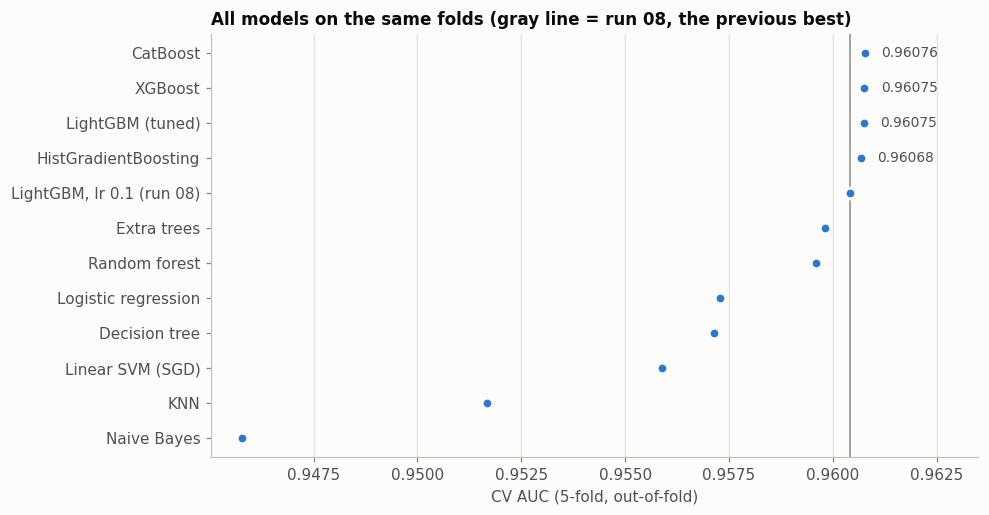

In [62]:
ordered = comparison.sort_values("CV AUC")
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(ordered["CV AUC"], ordered["model"], s=50, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=3)
ax.axvline(comparison.loc["08-lgb-no-domain", "CV AUC"], color=MUTED, linewidth=1)
for i, auc in enumerate(ordered["CV AUC"]):
    if i >= len(ordered) - 4:                                   # label only the top 4
        ax.text(auc + 0.0004, i, f"{auc:.5f}", va="center", fontsize=9, color=INK2)
ax.set_xlim(right=0.9635)
ax.grid(axis="y", visible=False)
ax.set_xlabel("CV AUC (5-fold, out-of-fold)")
ax.set_title("All models on the same folds (gray line = run 08, the previous best)")
plt.show()

How similar are the models' opinions? Below is the correlation between the out-of-fold predictions of the strongest models, compared as rankings (Spearman). 1.0 would mean they rank every passenger identically.

In [63]:
TOP_MODELS = ["19-catboost", "17-xgboost", "16-lightgbm-tuned", "18-hist-gb", "15-extra-trees", "14-random-forest", "09-logreg"]
pd.DataFrame({MODEL_LABELS[name]: model_oof[name] for name in TOP_MODELS}).rank().corr().round(3)

,CatBoost,XGBoost,LightGBM (tuned),HistGradientBoosting,Extra trees,Random forest,Logistic regression
CatBoost,1.000,0.985,0.988,0.985,0.957,0.954,0.933
XGBoost,0.985,1.000,0.989,0.986,0.962,0.959,0.929
LightGBM (tuned),0.988,0.989,1.000,0.990,0.963,0.960,0.930
HistGradientBoosting,0.985,0.986,0.990,1.000,0.961,0.957,0.930
Extra trees,0.957,0.962,0.963,0.961,1.000,0.973,0.914
Random forest,0.954,0.959,0.960,0.957,0.973,1.000,0.920
Logistic regression,0.933,0.929,0.930,0.930,0.914,0.920,1.000


**What this shows:**
- **Gradient boosting wins clearly.** CatBoost (0.96076), XGBoost (0.96075), tuned LightGBM (0.96075) and HistGradientBoosting (0.96068) all beat run 08 **in all 5 folds**, by +0.00026 to +0.00035. The top three are a tie, within 0.00001 of each other.
- **Lowering LightGBM's learning rate** from 0.1 to 0.03 (with more trees) gave +0.00033 on its own.
- **Bagging comes next:** extra trees (0.95980) and random forest (0.95959) are 0.0006–0.0008 behind, and extra trees was the slowest model (17 minutes).
- **The linear models and the single decision tree sit around 0.956–0.957.** KNN reaches 0.952; it used only 200k of the 560k training rows per fold to stay within its time budget. Naive Bayes is last (0.946), because its "independent features" assumption is badly broken here.
- **Correlations:** the boosting models agree with each other almost completely (0.985–0.990). Extra trees is a bit different (~0.96), and logistic regression the most different (~0.93). The next section tests whether these differences can be turned into a better blend.

## 11. Blending (routine step 8)

A **blend** combines the predictions of several models into one. Each model makes some mistakes on different passengers, and averaging cancels part of them. The models themselves aren't changed or merged: the blend is just a formula applied to their saved predictions, e.g. 0.25 x CatBoost + 0.25 x XGBoost + …

**The rule that keeps it honest:** anything the blend learns (its weights) is learned from the **out-of-fold** predictions, each made by a model that never saw that passenger. It is then scored on folds the weights were not fitted on.

We compare two approaches:
- **A. Simple average** of the 4 boosting models. There are no weights to learn, so nothing can overfit.
- **B. Stacking.** A logistic regression (the "meta-model") learns one weight per model from the out-of-fold predictions, converted to log-odds. To check for overfitting, it's fitted on 4 folds and scored on the 5th, rotating through all 5 folds.

In [64]:
from sklearn.linear_model import LogisticRegression

BOOSTING = ["16-lightgbm-tuned", "17-xgboost", "18-hist-gb", "19-catboost"]
catboost_folds = fold_aucs(model_oof["19-catboost"])


def compare_to_catboost(label, pred):
    fold_auc = fold_aucs(pred)
    gain = fold_auc - catboost_folds
    return {"blend": label, "CV AUC": roc_auc_score(y, pred), "fold mean": fold_auc.mean(),
            "gain vs CatBoost": gain.mean(), "folds better": f"{(gain > 0).sum()}/5"}


def as_log_odds(name, pred):
    # SVM scores are already on a log-odds-like scale; probabilities are converted with logit
    return pred if name == "10-linear-svm" else logit(pred)


def stack_with_nested_cv(models):
    X = np.column_stack([as_log_odds(name, model_oof[name]) for name in models])
    held_out, fitted_fold_auc = np.zeros(len(y)), []
    for tr_idx, va_idx in folds:
        meta = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X[tr_idx], y[tr_idx])
        held_out[va_idx] = meta.decision_function(X[va_idx])           # scored on the fold the weights never saw
        fitted_fold_auc.append(roc_auc_score(y[tr_idx], meta.decision_function(X[tr_idx])))
    meta = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X, y)   # final weights from all folds
    return held_out, np.mean(fitted_fold_auc), pd.Series(meta[-1].coef_[0], index=[MODEL_LABELS[n] for n in models])


blend_rows = [compare_to_catboost("CatBoost alone", model_oof["19-catboost"]),
              compare_to_catboost("A: average of the 4 boosting models", np.mean([model_oof[n] for n in BOOSTING], axis=0))]
STACK_SETS = {
    "B: stack of the 4 boosting models": BOOSTING,
    "B: stack of boosting + bagging + logistic regression": BOOSTING + ["15-extra-trees", "14-random-forest", "09-logreg"],
    "B: stack of all 12 models": list(MODEL_LABELS),
}
stack_weights = {}
for label, models in STACK_SETS.items():
    held_out, fitted_auc, weights = stack_with_nested_cv(models)
    blend_rows.append({**compare_to_catboost(label, held_out), "AUC on fitted folds": fitted_auc})
    stack_weights[label] = weights

pd.DataFrame(blend_rows).set_index("blend").style.format(
    {"CV AUC": "{:.5f}", "fold mean": "{:.5f}", "gain vs CatBoost": "{:+.5f}", "AUC on fitted folds": "{:.5f}"}, na_rep="")

,CV AUC,fold mean,gain vs CatBoost,folds better,AUC on fitted folds
blend,,,,,
CatBoost alone,0.96076,0.96077,+0.00000,0/5,
A: average of the 4 boosting models,0.96095,0.96096,+0.00019,5/5,
B: stack of the 4 boosting models,0.96095,0.96096,+0.00019,5/5,0.96096
B: stack of boosting + bagging + logistic regression,0.96097,0.96099,+0.00022,5/5,0.96098
B: stack of all 12 models,0.96095,0.96096,+0.00019,5/5,0.96097


The weights each stacking model learned (on standardized log-odds; a blank means the model wasn't in that set):

In [65]:
pd.DataFrame(stack_weights).reindex([MODEL_LABELS[n] for n in MODEL_LABELS]).round(3)

,B: stack of the 4 boosting models,B: stack of boosting + bagging + logistic regression,B: stack of all 12 models
"LightGBM, lr 0.1 (run 08)",NaN,NaN,-0.013
Logistic regression,NaN,-0.085,0.065
Linear SVM (SGD),NaN,NaN,-0.136
Decision tree,NaN,NaN,-0.069
KNN,NaN,NaN,0.060
Naive Bayes,NaN,NaN,-0.068
Random forest,NaN,0.190,0.189
Extra trees,NaN,0.216,0.165
LightGBM (tuned),0.751,0.541,0.466
XGBoost,0.754,0.722,0.805


**What this shows:**
- **Every blend beats CatBoost alone in all 5 folds,** by about +0.0002.
- **No overfitting.** For each stack, the AUC on the folds used to fit the weights matches the AUC on the held-out fold, to within 0.00001. With 4–12 weights and 700k rows, there's nothing to memorise.
- **The stack gives the 4 boosting models equal weights** (0.75 each), so the "learned" blend turns out to be the simple average.
- **More models don't help.** Adding bagging and logistic regression gains only +0.00002–0.00003, which is within noise. Logistic regression even gets a slightly *negative* weight: its different opinion is mostly noise compared with the boosting models. Using all 12 models doesn't help either.

**Decision: blend A, the simple average of the 4 boosting models.** It scores the same as the best stack, has no learned weights, outputs real probabilities, and is the easiest to explain and reproduce.

In [66]:
blend_oof = np.mean([model_oof[name] for name in BOOSTING], axis=0)
blend_test = np.mean([model_test[name] for name in BOOSTING], axis=0)
np.save(PREDS / "20-blend-boosting-avg-oof.npy", blend_oof)
np.save(PREDS / "20-blend-boosting-avg-test.npy", blend_test)

blend_folds = fold_aucs(blend_oof)
print(f"Final blend (run 20): CV AUC {roc_auc_score(y, blend_oof):.5f}, folds {blend_folds.mean():.5f} ± {blend_folds.std():.5f}, "
      f"better than CatBoost in {(blend_folds > catboost_folds).sum()}/5 folds (+{(blend_folds - catboost_folds).mean():.5f})")

Final blend (run 20): CV AUC 0.96095, folds 0.96096 ± 0.00058, better than CatBoost in 5/5 folds (+0.00019)


## 12. Submission files (routine step 9)

Kaggle wants one row per test passenger, `id,satisfaction`, with a probability. We create two files:
- `01-catboost.csv`: the best single model (CV 0.96076);
- `02-blend-boosting-avg.csv`: the blend (CV 0.96095).

Before a file is written, it's checked:
- the columns match `sample_submission.csv`;
- it has 299,844 rows, with the ids identical to the sample's and in the same order;
- there are no missing values;
- every value is between 0 and 1.

**Creating the files doesn't submit them.** Uploading is a separate step (`kaggle competitions submit`), done only with the user's OK.

In [67]:
def make_submission(file_name, test_pred):
    submission = pd.DataFrame({ID_COL: test[ID_COL].to_numpy(), TARGET: test_pred})
    # Checks before anything is written
    assert list(submission.columns) == list(sample.columns), "columns must match sample_submission.csv"
    assert len(submission) == len(sample) == 299_844, "one row per test passenger"
    assert (submission[ID_COL].to_numpy() == sample[ID_COL].to_numpy()).all(), "ids in the same order as the sample"
    assert submission[TARGET].notna().all(), "no missing predictions"
    assert submission[TARGET].between(0, 1).all(), "probabilities must be in [0, 1]"
    path = SUBMISSIONS / file_name
    submission.to_csv(path, index=False)
    print(f"{path}: {len(submission):,} rows, predictions {submission[TARGET].min():.4f} to {submission[TARGET].max():.4f}, "
          f"mean {submission[TARGET].mean():.4f}")
    return submission


catboost_submission = make_submission("01-catboost.csv", model_test["19-catboost"])
blend_submission = make_submission("02-blend-boosting-avg.csv", blend_test)
blend_submission.head()

submissions/01-catboost.csv: 299,844 rows, predictions 0.0046 to 0.9960, mean 0.4437


submissions/02-blend-boosting-avg.csv: 299,844 rows, predictions 0.0077 to 0.9965, mean 0.4437


,id,satisfaction
0,699635,0.254071
1,699636,0.715781
2,699637,0.939322
3,699638,0.076710
4,699639,0.043398


Both files passed every check. The average prediction (~0.44) matches the share of satisfied passengers in train (44.4%), a quick sign that the probabilities are sensible.

Next: submit both files (with the user's OK), record their public leaderboard scores in the README, and pick the 2 final submissions **by CV**: the blend and CatBoost.

## 13. Adding the original rows to the training folds (routine step 8)

So far the original 129,880 real passengers were used only **indirectly**, through features: the lookups (`orig_rate_*`, `orig_n_*`) and the original-only model (`orig_model_prob`). Here we also use them **directly, as extra training rows**:

```
Fold k   training part:  560k synthetic rows (is_original = 0)  +  130k original rows (is_original = 1)
         validation:     140k synthetic rows only   <- scored, exactly as before
Test:                    300k synthetic rows (is_original = 0)
```

- **Original rows only join the training part.** They never go into validation and are never scored, so the CV score stays directly comparable with run 16.
- **`is_original`** tells the model where a row comes from. The two sources differ (section 5: delays ~10x smaller in the synthetic data, distances shifted), and with the flag a tree can learn those differences instead of mixing them.
- We expect a **small** gain at best, because the features above already carry most of the original's information. The test: LightGBM with exactly run 16's settings, compared fold by fold. We keep the idea only if it improves **at least 4 of 5 folds**.

### 13.1 Features for the original rows, without leakage

The original rows need the same 46 columns as the synthetic ones. Three feature groups were built from the original's own labels, so for the original rows they must be computed **out-of-fold within the original data**. Otherwise each row would see its own answer:

| Feature group | Problem for an original row | Fix |
|---|---|---|
| `orig_rate_*` / `orig_n_*` lookups | its own label is part of its group's satisfaction rate (in small groups it can dominate) | split the original into 5 folds; each row's rates come from the other 4 folds (counts scaled up by 5/4 to match the full-data counts) |
| `orig_model_prob` | the original-only model would predict its *own training rows*, so it would be overconfident | 5 models, each trained on 4 folds of the original and predicting the 5th |
| target encodings `te_*` | must not use original labels at all | fitted on the fold's synthetic training rows only, then applied to the original rows (in the CV loop below) |
| value counts, distance digits | no labels involved | computed as before (counts from train + test) |

In [68]:
# Columns that need no labels: value counts (from train + test) and distance digits
orig_fe = add_digit_features(add_count_features(original_p, reference))
orig_fe[COUNT_FEATURES] = orig_fe[COUNT_FEATURES].fillna(0).astype("int32")   # a value never seen in train + test occurs 0 times

# Lookups computed out-of-fold *within* the original: each row's rates come from the other 80% of original rows
orig_folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(original_p, original_p[TARGET]))
ORIG_N_COLS = [c for c in LOOKUP_FEATURES if c.startswith("orig_n_")]
pieces = []
for fit_idx, apply_idx in orig_folds:
    piece = add_original_lookups(orig_fe.iloc[apply_idx], original_p.iloc[fit_idx])
    piece[ORIG_N_COLS] *= len(original_p) / len(fit_idx)        # counts from 80% of rows, scaled to the full-data scale
    piece.index = apply_idx                                     # merge resets the index; put rows back in place
    pieces.append(piece)
orig_fe = pd.concat(pieces).sort_index()

# Original-model probability out-of-fold: each row is predicted by a model that never saw it
orig_model_prob = np.zeros(len(original_p))
for fit_idx, apply_idx in orig_folds:
    fold_model = lgb.LGBMClassifier(n_estimators=500, learning_rate=0.05, num_leaves=31, random_state=SEED, verbose=-1)
    fold_model.fit(original_p[RAW_FEATURES].iloc[fit_idx], original_p[TARGET].iloc[fit_idx])
    orig_model_prob[apply_idx] = fold_model.predict_proba(original_p[RAW_FEATURES].iloc[apply_idx])[:, 1]
orig_fe["orig_model_prob"] = orig_model_prob.astype("float32")

te_keys_orig = build_te_keys(orig_fe)
y_orig = original_p[TARGET].to_numpy()
orig_fe = orig_fe[MODEL_FEATURES]
print(f"Original rows: {orig_fe.shape[0]:,} x {orig_fe.shape[1]} features (same columns as train_fe[MODEL_FEATURES]), "
      f"{y_orig.mean():.1%} satisfied")
print("Missing values (original-data keys never seen in the other 4 original folds):", int(orig_fe.isna().sum().sum()))

Original rows: 129,880 x 46 features (same columns as train_fe[MODEL_FEATURES]), 43.4% satisfied
Missing values (original-data keys never seen in the other 4 original folds): 1964


**Why the out-of-fold versions matter**, measured on the original rows. The *in-sample* versions (computed with each row's own label) look much better than the honest out-of-fold ones. A model trained on them would learn to trust these columns far too much for original rows:

In [69]:
in_sample_lookup = add_original_lookups(original_p, original_p)["orig_rate_distance_cabin_class"]
pd.DataFrame({
    "in-sample (leaky)": [roc_auc_score(y_orig, original_model.predict_proba(original_p[RAW_FEATURES])[:, 1]),
                          roc_auc_score(y_orig, in_sample_lookup)],
    "out-of-fold (used)": [roc_auc_score(y_orig, orig_fe["orig_model_prob"]),
                           roc_auc_score(y_orig, orig_fe["orig_rate_distance_cabin_class"].fillna(y_orig.mean()))],
}, index=["orig_model_prob", "orig_rate_distance_cabin_class"]).round(4)

,in-sample (leaky),out-of-fold (used)
orig_model_prob,0.9973,0.9949
orig_rate_distance_cabin_class,0.8188,0.7748


### 13.2 LightGBM with the original rows (experiment 21)

`fold_inputs_with_original()` builds each fold's data:
1. it fits the target encoder on the fold's **synthetic** training rows only;
2. it applies the encoder to the validation, test **and original** rows;
3. it adds the `is_original` flag and appends the original rows to the training part.

The validation and test rows are exactly the same as in run 16, with `is_original = 0`.

The model uses **exactly run 16's settings**, so the extra rows are the only difference. Early stopping still watches the synthetic validation fold, so the number of trees is chosen for the data we're scored on.

In [70]:
import gc

import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import TargetEncoder


def fold_inputs_with_original(tr_idx, va_idx):
    # Target encoding: fitted on this fold's synthetic training rows only, then applied to valid, test and original rows
    encoder = TargetEncoder(target_type="binary", cv=StratifiedKFold(5, shuffle=True, random_state=SEED))
    te_train = encoder.fit_transform(te_keys_train.iloc[tr_idx], y[tr_idx])
    te_valid, te_test, te_orig = (encoder.transform(keys) for keys in (te_keys_train.iloc[va_idx], te_keys_test, te_keys_orig))

    def assemble(features, encoded, is_original):
        out = features[MODEL_FEATURES].reset_index(drop=True).copy()
        out[TE_FEATURES] = encoded.astype("float32")
        out["is_original"] = np.int8(is_original)
        return out

    X_tr = pd.concat([assemble(train_fe.iloc[tr_idx], te_train, 0), assemble(orig_fe, te_orig, 1)], ignore_index=True)
    y_tr = np.concatenate([y[tr_idx], y_orig])
    return X_tr, y_tr, assemble(train_fe.iloc[va_idx], te_valid, 0), assemble(test_fe, te_test, 0)


# Exactly run 16's settings, so the original rows are the only difference
LGB_ORIG_PARAMS = dict(n_estimators=8000, learning_rate=0.03, num_leaves=63, min_child_samples=50, reg_lambda=1.0,
                       subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                       random_state=SEED, verbose=-1, n_jobs=N_JOBS)


def lgb_orig_fold(tr_idx, va_idx):
    X_tr, y_tr, X_va, X_te = fold_inputs_with_original(tr_idx, va_idx)
    model = lgb.LGBMClassifier(**LGB_ORIG_PARAMS)
    model.fit(X_tr, y_tr, eval_X=X_va, eval_y=y[va_idx], eval_metric="auc",
              callbacks=[lgb.early_stopping(300, verbose=False)])
    print(f"  best iteration {model.best_iteration_:,} of {LGB_ORIG_PARAMS['n_estimators']:,}")
    preds = model.predict_proba(X_va)[:, 1], model.predict_proba(X_te)[:, 1]
    del model, X_tr, X_va, X_te
    gc.collect()
    return preds


oof_lgb_orig, test_lgb_orig = run_model_cv("21-lightgbm-orig", lgb_orig_fold)

21-lightgbm-orig: loaded saved predictions


21-lightgbm-orig: OOF AUC 0.96081, folds 0.96083 ± 0.00057


### 13.3 Did the original rows help?

Run 21 against run 16, fold by fold. Same folds, same settings; the only difference is the extra rows.

In [71]:
lgb_folds, lgb_orig_folds = fold_aucs(model_oof["16-lightgbm-tuned"]), fold_aucs(oof_lgb_orig)
orig_gain = lgb_orig_folds - lgb_folds
print(f"OOF AUC: run 16 {roc_auc_score(y, model_oof['16-lightgbm-tuned']):.5f} -> run 21 {roc_auc_score(y, oof_lgb_orig):.5f}; "
      f"mean fold gain {orig_gain.mean():+.5f}, better in {(orig_gain > 0).sum()}/{N_FOLDS} folds")
pd.DataFrame({"run 16 (synthetic only)": lgb_folds, "run 21 (+ original rows)": lgb_orig_folds, "gain": orig_gain},
             index=[f"fold {k}" for k in range(N_FOLDS)]).round(5)

OOF AUC: run 16 0.96075 -> run 21 0.96081; mean fold gain +0.00007, better in 3/5 folds


,run 16 (synthetic only),run 21 (+ original rows),gain
fold 0,0.96080,0.96079,-0.00001
fold 1,0.95968,0.95982,0.00014
fold 2,0.96146,0.96157,0.00011
fold 3,0.96096,0.96108,0.00012
fold 4,0.96087,0.96086,-0.00001


**What this shows:**
- **The gain is tiny.** Adding the 130k original rows moved LightGBM's CV AUC from 0.96075 to 0.96081 (+0.00007 per fold on average).
- **It isn't consistent.** It improved 3 of 5 folds (by +0.00011 to +0.00014); the other 2 are ties (−0.00001).
- **By the rule set *before* running** (keep only if at least 4 of 5 folds improve), the idea is **not kept.** The gain is too small and too uneven to rely on. It would also add complexity (the leakage-safe features for the original rows) and ~25% more training time to every model.
- **This matches the expectation:** the lookup features and the original-only model already carry most of what the original data can teach.

So XGBoost, HistGradientBoosting and CatBoost aren't retrained with the original rows, and the blend from section 11 remains the final model.

## 14. Hyperparameter tuning (routine step 9)

**Hyperparameters** are the settings we choose *before* training: tree size, regularization and sampling. The model's own *parameters* (its splits and leaf values) are learned during training. So far our hyperparameters were set by hand on a 50k-row sample (section 10). Here, a search tries many combinations on the full data for the three strongest models.

**How the search works**
- **One fold, full size.** Each trial trains on fold 0's 560k training rows and is scored on its 140k validation rows. A small sample would favour small trees, so we keep the full size and use one fold instead of five. That keeps each trial at ~30–60 s.
- **Each model keeps its learning rate** (LightGBM 0.03, XGBoost 0.05, CatBoost 0.08) and its early stopping, which still picks the number of trees. The search changes the *shape* of the trees and the regularization.
- **Trial 0 is the current setting.** Its fold-0 AUC must equal the old run's fold-0 AUC, which checks the setup. It is also the score to beat.
- **LightGBM and XGBoost: Optuna's TPE search, 30 trials each.** The first ~10 trials are random. After that, TPE builds a model of which values gave good scores and proposes new settings near them (a form of Bayesian optimization). It finds good regions with far fewer trials than a grid would need.
- **CatBoost: a grid of 4 depths × 3 regularization strengths (12 fits).** CatBoost has fewer settings that matter, each fit is slower, and a grid shows the effect of tree depth directly.
- **No pruning.** Optuna can stop weak trials halfway, but early stopping already ends ours after 250–1,000 trees. Pruning would save little, and it would unfairly stop settings that learn slowly at first but finish better, such as small, regularized trees.
- **Resumable.** Every finished trial is saved in `preds/<study>.optuna.log`. Rerunning the notebook loads the finished studies in seconds.

**Two traps, and how we avoid them**
1. **The winner's curse.** With 30 trials, the best fold-0 score is partly luck: random row and column sampling alone moves a fold's AUC by ~0.0001. So the best setting is **retrained on all 5 folds** and compared fold by fold with the old run. Folds 1–4 played no part in the search, so they are the honest test.
2. **Same rule as before:** a tuned model replaces the old one only if it is better in **at least 4 of 5 folds**. Fold 0 is favoured by the search, so in practice at least 3 of the 4 untouched folds must improve.

Budget: ~20 min for each search, ~15 min for the CatBoost grid, and ~10 min for the three 5-fold runs. Peak RAM is about 1.5 GB.

**Shared tuning tools.**
- `tuning_inputs()` builds fold 0's training and validation frames once, with the in-fold target encodings, and reuses them for every trial.
- `run_study()` creates or reloads a study, puts the current setting first, runs only the trials that are still missing, and prints one line per trial.

In [72]:
import optuna
from optuna.storages import JournalStorage
from optuna.storages.journal import JournalFileBackend
from optuna.trial import TrialState

optuna.logging.set_verbosity(optuna.logging.WARNING)     # print_trial() below writes one short line per trial instead
TUNE_FOLD = 0
tune_tr, tune_va = folds[TUNE_FOLD]
_tuning_frames = {}


def tuning_inputs(for_catboost=False):
    # Fold 0's train/valid frames with in-fold target encodings, built on first use and reused by every trial
    if not _tuning_frames:
        X_tr, X_va, _ = gb_fold_inputs(tune_tr, tune_va)        # the test part isn't needed while tuning
        _tuning_frames.update(lgb=(X_tr, X_va))
    if for_catboost and "catboost" not in _tuning_frames:
        _tuning_frames["catboost"] = tuple(catboost_codes(X) for X in _tuning_frames["lgb"])
    return _tuning_frames["catboost" if for_catboost else "lgb"]


def catboost_codes(X):
    # CatBoost reads categories as integer codes, not as pandas 'category' (section 10.5)
    X = X.copy()
    X[CATEGORICAL] = X[CATEGORICAL].apply(lambda col: col.cat.codes)
    return X


def print_trial(study, trial):
    settings = ", ".join(f"{k}={v:.3g}" if isinstance(v, float) else f"{k}={v}" for k, v in trial.params.items())
    print(f"  trial {trial.number:2d}: AUC {trial.value:.5f} (best {study.best_value:.5f}), {trial.user_attrs['trees']:,} trees, "
          f"{trial.duration.total_seconds():.0f}s | {settings}", flush=True)


def run_study(name, objective, sampler, n_trials, current):
    # Each finished trial is appended to preds/<name>.optuna.log, so a rerun (or a crash) continues instead of starting over
    storage = JournalStorage(JournalFileBackend(str(PREDS / f"{name}.optuna.log")))
    study = optuna.create_study(study_name=name, storage=storage, direction="maximize", sampler=sampler, load_if_exists=True)
    if not study.trials and not isinstance(sampler, optuna.samplers.GridSampler):
        study.enqueue_trial(current)                              # trial 0 = the current setting (a grid already contains it)
    done = sum(trial.state == TrialState.COMPLETE for trial in study.trials)
    if done < n_trials:
        study.optimize(objective, n_trials=n_trials - done, callbacks=[print_trial])
    baseline = next(trial for trial in study.trials if trial.params == current)
    print(f"{name}: {len(study.trials)} trials. Current setting (trial {baseline.number}) {baseline.value:.5f}, "
          f"best (trial {study.best_trial.number}) {study.best_value:.5f}: {study.best_value - baseline.value:+.5f} on fold {TUNE_FOLD}")
    return study

### 14.1 LightGBM: TPE search over 5 settings

LightGBM grows trees leaf by leaf, so **`num_leaves` is its main size control**. Like run 16, every trial uses learning rate 0.03, at most 8,000 trees and early-stopping patience 300.

| Setting | Search range | Run 16 | What it controls |
|---|---|---|---|
| `num_leaves` | 15–255 (log) | 63 | tree size: more leaves capture more interactions but fit more noise |
| `min_child_samples` | 10–400 (log) | 50 | the fewest rows a leaf may hold: larger means smoother trees |
| `reg_lambda` | 0.001–30 (log) | 1 | L2 penalty that pulls leaf values toward 0 |
| `subsample` | 0.5–1.0 | 0.8 | share of rows each tree sees |
| `colsample_bytree` | 0.3–1.0 | 0.8 | share of columns each tree sees |

**Log** means the values are spread evenly on a log scale, so 15→30 leaves gets as much attention as 128→255. `multivariate=True` lets TPE learn how settings work *together*, e.g. bigger trees need larger leaves.

In [73]:
def fit_lightgbm(params, X_tr, y_tr, X_va, y_va):
    # The same fit as run 16: early stopping on the validation fold's AUC, patience 300
    model = lgb.LGBMClassifier(**params)
    model.fit(X_tr, y_tr, eval_X=X_va, eval_y=y_va, eval_metric="auc", callbacks=[lgb.early_stopping(300, verbose=False)])
    return model


LGB_CURRENT = {name: LGB_TUNED_PARAMS[name] for name in ["num_leaves", "min_child_samples", "reg_lambda", "subsample", "colsample_bytree"]}


def lgb_objective(trial):
    params = {**LGB_TUNED_PARAMS,                                 # run 16's settings; the search replaces 5 of them
              "num_leaves": trial.suggest_int("num_leaves", 15, 255, log=True),
              "min_child_samples": trial.suggest_int("min_child_samples", 10, 400, log=True),
              "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 30, log=True),
              "subsample": trial.suggest_float("subsample", 0.5, 1.0),
              "colsample_bytree": trial.suggest_float("colsample_bytree", 0.3, 1.0)}
    X_tr, X_va = tuning_inputs()
    model = fit_lightgbm(params, X_tr, y[tune_tr], X_va, y[tune_va])
    trial.set_user_attr("trees", model.best_iteration_)
    auc = roc_auc_score(y[tune_va], model.predict_proba(X_va)[:, 1])
    del model
    gc.collect()
    return auc


lgb_study = run_study("tuning-lightgbm", lgb_objective, optuna.samplers.TPESampler(seed=SEED, multivariate=True, n_startup_trials=10),
                      n_trials=30, current=LGB_CURRENT)

tuning-lightgbm: 30 trials. Current setting (trial 0) 0.96080, best (trial 26) 0.96121: +0.00041 on fold 0


**The best setting on all 5 folds (run 22).** The same fit as run 16, with the search's best values in place of the old ones.

In [74]:
LGB_OPTUNA_PARAMS = {**LGB_TUNED_PARAMS, **lgb_study.best_params}


def lgb_optuna_fold(tr_idx, va_idx):
    X_tr, X_va, X_te = gb_fold_inputs(tr_idx, va_idx)
    model = fit_lightgbm(LGB_OPTUNA_PARAMS, X_tr, y[tr_idx], X_va, y[va_idx])
    print(f"  best iteration {model.best_iteration_:,}")
    preds = model.predict_proba(X_va)[:, 1], model.predict_proba(X_te)[:, 1]
    del model, X_tr, X_va, X_te
    gc.collect()
    return preds


oof_lgb_optuna, test_lgb_optuna = run_model_cv("22-lightgbm-optuna", lgb_optuna_fold)

22-lightgbm-optuna: loaded saved predictions


22-lightgbm-optuna: OOF AUC 0.96104, folds 0.96104 ± 0.00053


### 14.2 XGBoost: TPE search over 5 settings

XGBoost grows trees level by level, so **`max_depth` is its size control**: a depth-*d* tree has up to 2^*d* leaves. Like run 17, every trial uses learning rate 0.05, at most 3,500 trees and early-stopping patience 200.

| Setting | Search range | Run 17 | What it controls |
|---|---|---|---|
| `max_depth` | 4–10 | 7 | tree depth (up to 16–1,024 leaves) |
| `min_child_weight` | 0.5–50 (log) | 2 | the least "evidence" a leaf needs. For log loss, this is roughly p·(1−p) summed over its rows, so 2 ≈ 10 rows |
| `reg_lambda` | 0.01–30 (log) | 1 | L2 penalty on leaf values |
| `subsample` | 0.5–1.0 | 0.8 | share of rows each tree sees |
| `colsample_bytree` | 0.3–1.0 | 0.6 | share of columns each tree sees |

In [75]:
def fit_xgboost(params, X_tr, y_tr, X_va, y_va):
    # The same fit as run 17: early stopping on the validation fold's AUC, set in XGB_PARAMS
    model = xgb.XGBClassifier(**params)
    model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
    return model


XGB_CURRENT = {name: XGB_PARAMS[name] for name in ["max_depth", "min_child_weight", "reg_lambda", "subsample", "colsample_bytree"]}


def xgb_objective(trial):
    params = {**XGB_PARAMS,                                       # run 17's settings; the search replaces 5 of them
              "max_depth": trial.suggest_int("max_depth", 4, 10),
              "min_child_weight": trial.suggest_float("min_child_weight", 0.5, 50, log=True),
              "reg_lambda": trial.suggest_float("reg_lambda", 1e-2, 30, log=True),
              "subsample": trial.suggest_float("subsample", 0.5, 1.0),
              "colsample_bytree": trial.suggest_float("colsample_bytree", 0.3, 1.0)}
    X_tr, X_va = tuning_inputs()
    model = fit_xgboost(params, X_tr, y[tune_tr], X_va, y[tune_va])
    trial.set_user_attr("trees", model.best_iteration + 1)
    auc = roc_auc_score(y[tune_va], model.predict_proba(X_va)[:, 1])
    del model
    gc.collect()
    return auc


xgb_study = run_study("tuning-xgboost", xgb_objective, optuna.samplers.TPESampler(seed=SEED, multivariate=True, n_startup_trials=10),
                      n_trials=30, current=XGB_CURRENT)

tuning-xgboost: 30 trials. Current setting (trial 0) 0.96088, best (trial 27) 0.96102: +0.00014 on fold 0


**The best setting on all 5 folds (run 23).**

In [76]:
XGB_OPTUNA_PARAMS = {**XGB_PARAMS, **xgb_study.best_params}


def xgb_optuna_fold(tr_idx, va_idx):
    X_tr, X_va, X_te = gb_fold_inputs(tr_idx, va_idx)
    model = fit_xgboost(XGB_OPTUNA_PARAMS, X_tr, y[tr_idx], X_va, y[va_idx])
    print(f"  best iteration {model.best_iteration + 1:,}")
    preds = model.predict_proba(X_va)[:, 1], model.predict_proba(X_te)[:, 1]
    del model, X_tr, X_va, X_te
    gc.collect()
    return preds


oof_xgb_optuna, test_xgb_optuna = run_model_cv("23-xgboost-optuna", xgb_optuna_fold)

23-xgboost-optuna: loaded saved predictions


23-xgboost-optuna: OOF AUC 0.96082, folds 0.96083 ± 0.00058


### 14.3 CatBoost: a grid over depth and L2 regularization

CatBoost's symmetric trees ask the same question across a whole level, so a depth-*d* tree always has exactly 2^*d* leaves. That makes **`depth`** its main setting. **`l2_leaf_reg`** is its L2 penalty on leaf values (default 3). Like run 19, every fit uses learning rate 0.08, at most 2,500 trees and early-stopping patience 150. The grid has 12 combinations, and depth 6 with `l2_leaf_reg` 3 is run 19:

| | `l2_leaf_reg` 1 | 3 | 10 |
|---|---|---|---|
| **depth 6** (64 leaves) | | run 19 | |
| **depth 7** (128) | | | |
| **depth 8** (256) | | | |
| **depth 9** (512) | | | |

`GridSampler` is Optuna's grid search: it simply runs every combination once, in random order, so the same `run_study()` tool works here too.

In [77]:
def fit_catboost(params, X_tr, y_tr, X_va, y_va):
    # The same fit as run 19: frames with integer category codes, early stopping on the validation AUC
    model = CatBoostClassifier(cat_features=CATEGORICAL, **params)
    model.fit(X_tr, y_tr, eval_set=(X_va, y_va))
    return model


CATBOOST_GRID = {"depth": [6, 7, 8, 9], "l2_leaf_reg": [1, 3, 10]}
CATBOOST_CURRENT = {"depth": CATBOOST_PARAMS["depth"], "l2_leaf_reg": 3}     # 3 is CatBoost's default


def catboost_objective(trial):
    params = {**CATBOOST_PARAMS,
              "depth": trial.suggest_categorical("depth", CATBOOST_GRID["depth"]),
              "l2_leaf_reg": trial.suggest_categorical("l2_leaf_reg", CATBOOST_GRID["l2_leaf_reg"])}
    X_tr, X_va = tuning_inputs(for_catboost=True)
    model = fit_catboost(params, X_tr, y[tune_tr], X_va, y[tune_va])
    trial.set_user_attr("trees", model.get_best_iteration() + 1)
    auc = roc_auc_score(y[tune_va], model.predict_proba(X_va)[:, 1])
    del model
    gc.collect()
    return auc


catboost_study = run_study("tuning-catboost", catboost_objective, optuna.samplers.GridSampler(CATBOOST_GRID, seed=SEED),
                           n_trials=12, current=CATBOOST_CURRENT)

tuning-catboost: 12 trials. Current setting (trial 6) 0.96078, best (trial 8) 0.96081: +0.00003 on fold 0


**The best setting on all 5 folds (run 24).**

In [78]:
CATBOOST_GRID_PARAMS = {**CATBOOST_PARAMS, **catboost_study.best_params}


def catboost_grid_fold(tr_idx, va_idx):
    X_tr, X_va, X_te = (catboost_codes(X) for X in gb_fold_inputs(tr_idx, va_idx))
    model = fit_catboost(CATBOOST_GRID_PARAMS, X_tr, y[tr_idx], X_va, y[va_idx])
    print(f"  best iteration {model.get_best_iteration() + 1:,}")
    preds = model.predict_proba(X_va)[:, 1], model.predict_proba(X_te)[:, 1]
    del model, X_tr, X_va, X_te
    gc.collect()
    return preds


oof_catboost_grid, test_catboost_grid = run_model_cv("24-catboost-grid", catboost_grid_fold)

24-catboost-grid: loaded saved predictions


24-catboost-grid: OOF AUC 0.96077, folds 0.96078 ± 0.00060


### 14.4 What the searches found

Each dot is one trial's fold-0 AUC. The blue line is the best score found so far, and the dashed line is trial 0, our previous setting.

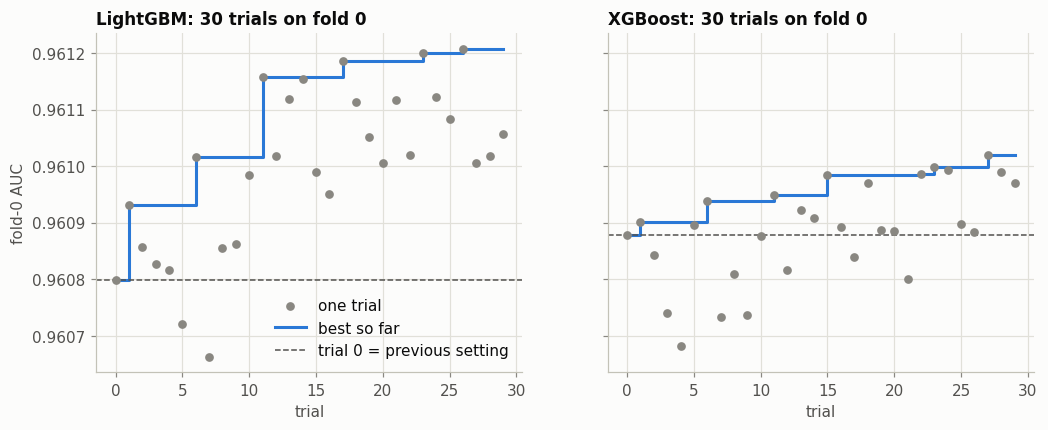

In [79]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (label, study) in zip(axes, [("LightGBM", lgb_study), ("XGBoost", xgb_study)]):
    trials = study.trials_dataframe()
    ax.scatter(trials["number"], trials["value"], s=22, color=MUTED, zorder=3, label="one trial")
    ax.step(trials["number"], trials["value"].cummax(), where="post", color=BLUE, linewidth=2, label="best so far")
    ax.axhline(trials.loc[0, "value"], color=INK2, linestyle="--", linewidth=1, label="trial 0 = previous setting")
    ax.set_title(f"{label}: {len(trials)} trials on fold 0")
    ax.set_xlabel("trial")
axes[0].set_ylabel("fold-0 AUC")
axes[0].yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.4f}"))
axes[0].legend(loc="lower right")
plt.show()

The CatBoost grid, fold-0 AUC for every combination (run 19's setting is depth 6, `l2_leaf_reg` 3):

In [80]:
catboost_grid = catboost_study.trials_dataframe().pivot(index="params_depth", columns="params_l2_leaf_reg", values="value")
catboost_grid.index.name, catboost_grid.columns.name = "depth", "l2_leaf_reg"
catboost_grid.style.format("{:.5f}").background_gradient(cmap=SEQUENTIAL, axis=None)

l2_leaf_reg,1,3,10
depth,,,
6,0.96075,0.96078,0.96079
7,0.96069,0.96081,0.96071
8,0.96069,0.96079,0.96077
9,0.96062,0.96070,0.96075


How the best settings differ from the previous ones:

In [81]:
def settings_change(label, previous, best):
    show = lambda v: f"{v:.3g}" if isinstance(v, float) else str(v)
    return pd.DataFrame({"model": label, "setting": list(previous), "previous": [show(previous[k]) for k in previous],
                         "best trial": [show(best[k]) for k in previous]})


pd.concat([settings_change("LightGBM", LGB_CURRENT, lgb_study.best_params),
           settings_change("XGBoost", XGB_CURRENT, xgb_study.best_params),
           settings_change("CatBoost", CATBOOST_CURRENT, catboost_study.best_params)]).set_index(["model", "setting"])

previous best trial
model    setting                              
LightGBM num_leaves              63         89
         min_child_samples       50         13
         reg_lambda               1       3.42
         subsample              0.8      0.982
         colsample_bytree       0.8      0.311
XGBoost  max_depth                7          9
         min_child_weight         2      0.628
         reg_lambda               1         16
         subsample              0.8       0.86
         colsample_bytree       0.6      0.471
CatBoost depth                    6          7
         l2_leaf_reg              3          3

**Which settings mattered?** Across the 30 trials, each setting's rank correlation with the fold-0 AUC: a positive value means larger values scored better. With 30 trials this is a rough guide, not a precise measurement.

In [82]:
def setting_effects(study):
    trials = study.trials_dataframe()
    columns = [c for c in trials if c.startswith("params_")]
    return trials[columns + ["value"]].corr(method="spearman")["value"].drop("value").rename(lambda c: c[len("params_"):])


pd.DataFrame({"LightGBM": setting_effects(lgb_study), "XGBoost": setting_effects(xgb_study)}).style.format("{:+.2f}", na_rep="")   # blank = not a setting of that model

,LightGBM,XGBoost
colsample_bytree,-0.70,-0.14
max_depth,,+0.50
min_child_samples,-0.39,
min_child_weight,,-0.32
num_leaves,+0.31,
reg_lambda,+0.71,+0.56
subsample,+0.46,+0.22


**What this shows:**
- **LightGBM gained the most: +0.00041 on fold 0** (0.96080 → 0.96121). The two settings that mattered most were **fewer columns per tree** (`colsample_bytree` 0.8 → 0.31) and a **stronger L2 penalty**. All 10 best trials used 31–51% of the columns and `reg_lambda` ≥ 3.4. When each tree sees only a third of the columns, the trees are forced to use different features, and their average is more robust. Tree size mattered less: the 10 best trials ranged from 55 to 203 leaves.
- **XGBoost gained +0.00014** (0.96088 → 0.96102), mainly from **deeper trees** (depth 7 → 9; all 10 best trials used depth 8–10) and a **stronger L2 penalty** (1 → 16).
- **CatBoost's grid is flat.** All 12 combinations score within 0.0002 of each other. The best (depth 7) is only +0.00003 above run 19's setting, which is noise. Depth 9 is too deep, and depth 6–8 are equally good, so run 19's setting was already right.

### 14.5 Did the tuned settings hold up on all 5 folds?

Each tuned run against the run it would replace, fold by fold. Folds 1–4 played no part in the search, so they are the honest test. Fold 0 repeats the search score.

In [83]:
TUNING_PAIRS = {"LightGBM": ("16-lightgbm-tuned", oof_lgb_optuna, "22-lightgbm-optuna"),
                "XGBoost": ("17-xgboost", oof_xgb_optuna, "23-xgboost-optuna"),
                "CatBoost": ("19-catboost", oof_catboost_grid, "24-catboost-grid")}
summary_rows, fold_gains = [], {}
for label, (old_name, new_oof, new_name) in TUNING_PAIRS.items():
    gain = fold_aucs(new_oof) - fold_aucs(model_oof[old_name])
    fold_gains[f"{label}: run {new_name[:2]} vs {old_name[:2]}"] = gain
    summary_rows.append({"model": label, "previous CV AUC": roc_auc_score(y, model_oof[old_name]),
                         "tuned CV AUC": roc_auc_score(y, new_oof), "mean fold gain": gain.mean(),
                         "gain on folds 1-4": gain[1:].mean(), "folds better": f"{(gain > 0).sum()}/5",
                         "keep tuned (>= 4/5)?": "yes" if (gain > 0).sum() >= 4 else "no"})
display(pd.DataFrame(summary_rows).set_index("model").style.format(
    {"previous CV AUC": "{:.5f}", "tuned CV AUC": "{:.5f}", "mean fold gain": "{:+.5f}", "gain on folds 1-4": "{:+.5f}"}))
pd.DataFrame(fold_gains, index=[f"fold {k}" + (" (searched)" if k == TUNE_FOLD else "") for k in range(N_FOLDS)]).style.format("{:+.6f}")

,previous CV AUC,tuned CV AUC,mean fold gain,gain on folds 1-4,folds better,keep tuned (>= 4/5)?
model,,,,,,
LightGBM,0.96075,0.96104,+0.00029,+0.00026,5/5,yes
XGBoost,0.96075,0.96082,+0.00006,+0.00004,4/5,yes
CatBoost,0.96076,0.96077,+0.00001,+0.00001,4/5,yes


,LightGBM: run 22 vs 16,XGBoost: run 23 vs 17,CatBoost: run 24 vs 19
fold 0 (searched),+0.000408,+0.000141,+0.000034
fold 1,+0.000355,+0.000024,+0.000050
fold 2,+0.000158,-0.000009,+0.000002
fold 3,+0.000246,+0.000025,-0.000051
fold 4,+0.000285,+0.000131,+0.000018


**What this shows:**
- **LightGBM: a clear, real gain.** Run 22 beats run 16 in **all 5 folds**: +0.00029 on average, and +0.00026 on the four untouched folds. That is almost as much as on the searched fold, so this isn't the winner's curse. At **0.96104**, the tuned LightGBM alone beats the old 4-model blend (0.96095).
- **XGBoost: kept, but the gain is small.** Run 23 beats run 17 in 4 of 5 folds, by +0.00006 on average and only +0.00004 on the untouched folds. It was already close to its best settings.
- **CatBoost: in practice a tie.** Run 24 passes the rule, but only just. Its fold-2 "win" is +0.000002, twenty times smaller than the noise between two seeds, and it loses fold 3. The mean gain is +0.00001.
- **A lesson about our rule:** "better in ≥ 4 of 5 folds" counts the *direction* of each fold's change, not its *size*. That is enough for real gains like LightGBM's, but a near-zero change can pass by luck, as CatBoost's did. We follow the rule as written: tuned XGBoost and CatBoost are kept, and the next section shows this changes the blend by less than 0.00001. For future experiments, a better rule also requires a minimum mean gain, e.g. +0.00005, decided *before* the run.

### 14.6 Rebuilding the blend

The blend uses the same 4 boosting models as before (section 11), now with the tuned versions: LightGBM 22, XGBoost 23, CatBoost 24, and HistGradientBoosting 18, which wasn't tuned. As in section 11, we compare **A, the simple average**, with **B, stacking**, where a logistic regression learns one weight per model with nested CV. In section 11 the stack gave all 4 models equal weights. Now one model is clearly stronger than the others, so it may deserve more weight.

In [84]:
TUNED_RUNS = {"22-lightgbm-optuna": ("LightGBM (Optuna)", oof_lgb_optuna, test_lgb_optuna),
              "23-xgboost-optuna": ("XGBoost (Optuna)", oof_xgb_optuna, test_xgb_optuna),
              "24-catboost-grid": ("CatBoost (grid)", oof_catboost_grid, test_catboost_grid)}
for name, (label, oof_pred, test_pred) in TUNED_RUNS.items():
    MODEL_LABELS[name], model_oof[name], model_test[name] = label, oof_pred, test_pred

BOOSTING_TUNED = ["22-lightgbm-optuna", "23-xgboost-optuna", "18-hist-gb", "24-catboost-grid"]
run20_folds = fold_aucs(blend_oof)


def compare_to_run20(label, pred):
    gain = fold_aucs(pred) - run20_folds
    return {"blend": label, "CV AUC": roc_auc_score(y, pred), "gain vs run 20": gain.mean(), "folds better": f"{(gain > 0).sum()}/5"}


tuned_avg_oof = np.mean([model_oof[name] for name in BOOSTING_TUNED], axis=0)
tuned_stack_oof, tuned_stack_fitted_auc, tuned_stack_weights = stack_with_nested_cv(BOOSTING_TUNED)
display(pd.DataFrame([
    compare_to_run20("run 20: average of the previous 4 models", blend_oof),
    compare_to_run20("LightGBM (Optuna) alone", oof_lgb_optuna),
    compare_to_run20("A: average of the tuned 4", tuned_avg_oof),
    {**compare_to_run20("B: stack of the tuned 4", tuned_stack_oof), "AUC on fitted folds": tuned_stack_fitted_auc},
]).set_index("blend").style.format({"CV AUC": "{:.5f}", "gain vs run 20": "{:+.5f}", "AUC on fitted folds": "{:.5f}"}, na_rep=""))

stack_vs_avg = fold_aucs(tuned_stack_oof) - fold_aucs(tuned_avg_oof)
print(f"Stack vs simple average: {stack_vs_avg.mean():+.5f} per fold, better in {(stack_vs_avg > 0).sum()}/5 folds")
print("Stack weights (standardized log-odds):", tuned_stack_weights.round(2).to_dict())

,CV AUC,gain vs run 20,folds better,AUC on fitted folds
blend,,,,
run 20: average of the previous 4 models,0.96095,+0.00000,0/5,
LightGBM (Optuna) alone,0.96104,+0.00008,4/5,
A: average of the tuned 4,0.96108,+0.00012,5/5,
B: stack of the tuned 4,0.96110,+0.00015,5/5,0.96111


Stack vs simple average: +0.00003 per fold, better in 4/5 folds
Stack weights (standardized log-odds): {'LightGBM (Optuna)': 1.41, 'XGBoost (Optuna)': 0.77, 'HistGradientBoosting': 0.29, 'CatBoost (grid)': 0.54}


**What this shows:**
- **Both new blends beat run 20 in all 5 folds:** the average by +0.00012 and the stack by +0.00015. Almost all of the gain comes from the tuned LightGBM.
- **The stack now gives unequal weights,** about 1.4 for LightGBM, 0.8 for XGBoost, 0.5 for CatBoost and 0.3 for HistGradientBoosting. It learned that LightGBM is now the strongest model.
- **The stack beats the simple average in 4 of 5 folds, by +0.00003.** That is small, but its direction makes sense (more weight on the best model), and it is honest: every fold is scored with weights fitted on the other four, and the AUC on the fitted folds equals the held-out AUC, so there is no overfitting.

**Decision: blend B, the stack of the tuned 4 models (run 25),** with CV **0.96110**: +0.00015 over run 20, better in 5 of 5 folds. Its final weights are fitted on all the out-of-fold predictions and then applied to the test predictions.

In [85]:
X_stack_oof = np.column_stack([as_log_odds(name, model_oof[name]) for name in BOOSTING_TUNED])
X_stack_test = np.column_stack([as_log_odds(name, model_test[name]) for name in BOOSTING_TUNED])
final_stack = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_stack_oof, y)
stack_test = final_stack.predict_proba(X_stack_test)[:, 1]
stack_oof = 1 / (1 + np.exp(-tuned_stack_oof))          # the nested-CV log-odds as probabilities, for saving
np.save(PREDS / "25-blend-tuned-stack-oof.npy", stack_oof)
np.save(PREDS / "25-blend-tuned-stack-test.npy", stack_test)
print(f"Run 25 (stack of the tuned 4): CV AUC {roc_auc_score(y, stack_oof):.5f}; "
      f"test predictions rank-correlate {pd.Series(stack_test).corr(pd.Series(blend_test), method='spearman'):.4f} with run 20's")

Run 25 (stack of the tuned 4): CV AUC 0.96110; test predictions rank-correlate 0.9977 with run 20's


### 14.7 New submission files

- **`03-blend-tuned-stack.csv`:** run 25, the best CV so far (0.96110).
- **`04-lightgbm-optuna.csv`:** run 22, the best single model (0.96104). It is a different, robust candidate for the second final pick.

The same checks as in section 12 run before each file is written. Creating the files doesn't submit them.

In [86]:
stack_submission = make_submission("03-blend-tuned-stack.csv", stack_test)
lgb_optuna_submission = make_submission("04-lightgbm-optuna.csv", test_lgb_optuna)

submissions/03-blend-tuned-stack.csv: 299,844 rows, predictions 0.0077 to 0.9958, mean 0.4437


submissions/04-lightgbm-optuna.csv: 299,844 rows, predictions 0.0071 to 0.9961, mean 0.4437


### 14.8 The original rows again, with the tuned LightGBM (experiment 26)

In section 13, the 130k original rows gave run 16 only +0.00007 (3/5 folds), so they were not kept. The tuned LightGBM is a different model: it has bigger trees, stronger regularization and samples a third of the columns per tree, so it might use the extra rows better. This is **one planned re-test**, not a search for a variant that happens to pass.

- **Same setup as run 21:** `fold_inputs_with_original()` from section 13, with the original rows in every training fold, their label-based features computed out-of-fold within the original, target encodings fitted on synthetic rows only, and the `is_original` flag.
- **Same model as run 22:** `LGB_OPTUNA_PARAMS` and `fit_lightgbm()`, so the extra rows are the only difference.
- **Rule, set before the run:** keep the rows only if run 26 beats run 22 in **at least 4 of 5 folds** *and* by **at least +0.00005 on average**. That second condition is the minimum gain suggested in 14.5.

In [87]:
def lgb_optuna_orig_fold(tr_idx, va_idx):
    X_tr, y_tr, X_va, X_te = fold_inputs_with_original(tr_idx, va_idx)
    model = fit_lightgbm(LGB_OPTUNA_PARAMS, X_tr, y_tr, X_va, y[va_idx])
    print(f"  best iteration {model.best_iteration_:,}")
    preds = model.predict_proba(X_va)[:, 1], model.predict_proba(X_te)[:, 1]
    del model, X_tr, X_va, X_te
    gc.collect()
    return preds


oof_lgb_optuna_orig, test_lgb_optuna_orig = run_model_cv("26-lightgbm-optuna-orig", lgb_optuna_orig_fold)

26-lightgbm-optuna-orig: loaded saved predictions


26-lightgbm-optuna-orig: OOF AUC 0.96107, folds 0.96108 ± 0.00052


Run 26 against run 22, fold by fold. The last column repeats section 13's result for run 16's settings (run 21 − run 16), for comparison.

In [88]:
orig_tuned_gain = fold_aucs(oof_lgb_optuna_orig) - fold_aucs(oof_lgb_optuna)
keep_orig_rows = (orig_tuned_gain > 0).sum() >= 4 and orig_tuned_gain.mean() >= 0.00005
print(f"OOF AUC: run 22 {roc_auc_score(y, oof_lgb_optuna):.5f} -> run 26 {roc_auc_score(y, oof_lgb_optuna_orig):.5f}; "
      f"mean fold gain {orig_tuned_gain.mean():+.6f}, better in {(orig_tuned_gain > 0).sum()}/{N_FOLDS} folds "
      f"-> keep the original rows: {'yes' if keep_orig_rows else 'no'}")
pd.DataFrame({"run 22 (synthetic only)": fold_aucs(oof_lgb_optuna), "run 26 (+ original rows)": fold_aucs(oof_lgb_optuna_orig),
              "gain": orig_tuned_gain, "gain with run 16's settings": orig_gain},
             index=[f"fold {k}" for k in range(N_FOLDS)]).style.format("{:.5f}").format("{:+.6f}", subset=["gain", "gain with run 16's settings"])

OOF AUC: run 22 0.96104 -> run 26 0.96107; mean fold gain +0.000033, better in 4/5 folds -> keep the original rows: no


,run 22 (synthetic only),run 26 (+ original rows),gain,gain with run 16's settings
fold 0,0.96121,0.96123,+0.000027,-0.000007
fold 1,0.96004,0.96009,+0.000051,+0.000139
fold 2,0.96162,0.96165,+0.000038,+0.000115
fold 3,0.96120,0.96126,+0.000055,+0.000122
fold 4,0.96115,0.96115,-0.000003,-0.000005


**What this shows:**
- **Better in 4 of 5 folds, but only by +0.00003 on average** (OOF 0.96104 → 0.96107), and fold 4 is a tie.
- **Not kept:** it fails the minimum-gain condition (+0.00005) set before the run. By the old rule alone (4/5 folds) it would have passed. This is the case the size condition is for: a consistent but tiny gain. It would move the blend by about +0.00001, too little to justify ~25% more training time for every model and the extra feature code for the original rows.
- **Tuning first did not make the original rows more useful.** The gain *shrank*, from +0.00007 with run 16's settings to +0.00003 with the tuned ones. The tuned model already gets more out of the synthetic data, so the original rows have less left to add. Their information already reaches the model through the lookup features and the original-only model (section 7).

This closes the original-rows idea. The stack (run 25) remains the final model.

## 15. Rating-pattern features (routine steps 7–8)

All our engineered features so far (counts, original lookups, target encodings) are built from distance, age, delays and the 4 categories. **None use the 13 service ratings**, even though they are the strongest predictors. A quick check shows they hide a strong trace of how the data was generated:

| Rating combination | Train rows whose exact pattern appears again in train/test | Train rows whose pattern also exists in the original | AUC of the original's satisfaction rate for the pattern, alone |
|---|---|---|---|
| All 13 ratings | 67% | 41% | 0.922 |
| The 6 strongest ratings | 100% | 98% | 0.932 |

13 ratings with 6 values each allow 13 billion combinations, so if the ratings were independent, almost no two rows would share all 13. Instead, two-thirds of rows have an exact twin. The generator seems to reuse whole rating patterns, many copied from real passengers.

**Why this can help even though the model already sees every rating:** a tree needs many splits to isolate one exact 13-value pattern, and it can't do that at all for rare patterns. A pattern feature hands that information over as one number.

**Three feature groups**, each built for three pattern keys: all 13 ratings, the 6 strongest ratings, and the 13 ratings + class + travel type:
1. **Pattern counts:** how often the pattern occurs in train + test. This uses no labels, like the distance counts in section 7.
2. **Original lookups:** the satisfaction rate and count of the pattern among the 130k real passengers, like `orig_rate_*`. They use only the original's labels, so they can't leak into our folds.
3. **In-fold target encoding:** the pattern's satisfaction rate in the fold's training rows, cross-fitted like our other target encodings. scikit-learn's `TargetEncoder` shrinks rare patterns toward the overall rate (`smooth="auto"`), so a pattern seen twice isn't trusted much.

**Procedure:** the groups are added one at a time to the tuned LightGBM (run 22's settings, unchanged), each on top of the groups kept before it, as in section 8. **Rule, set before the runs:** keep a group only if it's better in **≥ 4 of 5 folds** and by **≥ +0.00005** on average. If any group is kept, XGBoost, HistGradientBoosting and CatBoost are retrained with the kept features, and the stack is rebuilt.

**Building the features.** `pattern_codes()` turns each row's combination of values into one integer, reading the values as the digits of a base-7 number: ratings are 0–5 and category codes 0–2, so 7 digits are enough. Two rows get the same code exactly when they have the same pattern. The 6 strongest ratings are those with the highest single-rating AUC on train.

In [89]:
TOP6_RATINGS = ["online_boarding", "entertainment", "seat_comfort", "onboard_service", "cleanliness", "leg_room"]
RATING_PATTERNS = {"ratings13": RATINGS, "ratings6": TOP6_RATINGS, "ratings13_segment": RATINGS + ["cabin_class", "travel_type"]}


def pattern_codes(df, cols):
    # One integer per row for its exact combination of values, read as a base-7 number
    code = np.zeros(len(df), dtype=np.int64)
    for col in cols:
        values = df[col].cat.codes if isinstance(df[col].dtype, pd.CategoricalDtype) else df[col]
        code = code * 7 + values.to_numpy().astype(np.int64)
    return code


# 1. Pattern counts over train + test (no labels)
PATTERN_COUNT_FEATURES = []
for name, cols in RATING_PATTERNS.items():
    codes = np.concatenate([pattern_codes(train_fe, cols), pattern_codes(test_fe, cols)])
    _, inverse, counts = np.unique(codes, return_inverse=True, return_counts=True)
    n = counts[inverse].astype("int32")
    train_fe[f"count_{name}"], test_fe[f"count_{name}"] = n[:len(train_fe)], n[len(train_fe):]
    PATTERN_COUNT_FEATURES.append(f"count_{name}")

# 2. Satisfaction rate and count of the pattern in the original data (original labels only)
PATTERN_LOOKUP_FEATURES = []
for name, cols in RATING_PATTERNS.items():
    stats = pd.Series(y_orig).groupby(pattern_codes(orig_fe, cols)).agg(["mean", "size"])
    for df in (train_fe, test_fe):
        codes = pd.Series(pattern_codes(df, cols))
        df[f"orig_rate_{name}"] = codes.map(stats["mean"]).to_numpy(dtype="float32")   # NaN: pattern not in the original
        df[f"orig_n_{name}"] = codes.map(stats["size"]).to_numpy(dtype="float32")
    PATTERN_LOOKUP_FEATURES += [f"orig_rate_{name}", f"orig_n_{name}"]

# 3. Keys for the in-fold target encoding (encoded later, inside each fold)
pattern_te_train = pd.DataFrame({f"te_{name}": pattern_codes(train_fe, cols) for name, cols in RATING_PATTERNS.items()},
                                index=te_keys_train.index)
pattern_te_test = pd.DataFrame({f"te_{name}": pattern_codes(test_fe, cols) for name, cols in RATING_PATTERNS.items()},
                               index=te_keys_test.index)
PATTERN_TE_FEATURES = list(pattern_te_train.columns)

print("Distinct patterns in train:", pattern_te_train.nunique().to_dict())
train_fe[PATTERN_COUNT_FEATURES + PATTERN_LOOKUP_FEATURES].describe().T[["count", "mean", "50%", "max"]].round(3)

Distinct patterns in train: {'te_ratings13': 337881, 'te_ratings6': 10983, 'te_ratings13_segment': 383907}


,count,mean,50%,max
count_ratings13,699635.0,22.757,4.000,313.0
count_ratings6,699635.0,2767.987,1171.000,13669.0
count_ratings13_segment,699635.0,21.256,3.000,278.0
orig_rate_ratings13,287472.0,0.597,1.000,1.0
orig_n_ratings13,287472.0,5.140,3.000,29.0
orig_rate_ratings6,672200.0,0.460,0.356,1.0
orig_n_ratings6,672200.0,299.375,149.000,1331.0
orig_rate_ratings13_segment,236671.0,0.687,1.000,1.0
orig_n_ratings13_segment,236671.0,5.711,4.000,28.0


**Testing the groups on the tuned LightGBM (runs 27–29).** `pattern_inputs()` is `gb_fold_inputs()` with a chosen feature list and set of target-encoding keys. The loop adds one group at a time, compares it fold by fold with the best run so far, and keeps it only if it passes the rule.

In [90]:
def pattern_inputs(tr_idx, va_idx, features, te_keys_tr, te_keys_te):
    # Like gb_fold_inputs, with a chosen feature list and target-encoding keys (fitted on the fold's training rows only)
    return add_target_encoding(train_fe[features].iloc[tr_idx], y[tr_idx], train_fe[features].iloc[va_idx], test_fe[features],
                               te_keys_tr.iloc[tr_idx], te_keys_tr.iloc[va_idx], te_keys_te)


def fold_gain(new_oof, old_oof):
    return np.array([roc_auc_score(y[va], new_oof[va]) - roc_auc_score(y[va], old_oof[va]) for _, va in folds])


def keep_change(gain):
    # The rule set before these runs: better in >= 4 of 5 folds, and by >= +0.00005 on average
    return (gain > 0).sum() >= 4 and gain.mean() >= 0.00005


PATTERN_STEPS = [("27-lgb-pattern-counts", "1. pattern counts", PATTERN_COUNT_FEATURES, []),
                 ("28-lgb-pattern-orig", "2. original lookups", PATTERN_LOOKUP_FEATURES, []),
                 ("29-lgb-pattern-te", "3. in-fold target encoding", [], PATTERN_TE_FEATURES)]
pattern_features, pattern_te = list(MODEL_FEATURES), []          # grow with every kept group
best_oof, best_test, best_run = oof_lgb_optuna, test_lgb_optuna, "22-lightgbm-optuna"
pattern_log = []
for run_name, label, new_features, new_te in PATTERN_STEPS:
    features, te_cols = pattern_features + new_features, pattern_te + new_te
    te_tr = pd.concat([te_keys_train, pattern_te_train[te_cols]], axis=1)
    te_te = pd.concat([te_keys_test, pattern_te_test[te_cols]], axis=1)

    def lgb_pattern_fold(tr_idx, va_idx):
        X_tr, X_va, X_te = pattern_inputs(tr_idx, va_idx, features, te_tr, te_te)
        model = fit_lightgbm(LGB_OPTUNA_PARAMS, X_tr, y[tr_idx], X_va, y[va_idx])
        print(f"  best iteration {model.best_iteration_:,}")
        preds = model.predict_proba(X_va)[:, 1], model.predict_proba(X_te)[:, 1]
        del model, X_tr, X_va, X_te
        gc.collect()
        return preds

    oof, test_pred = run_model_cv(run_name, lgb_pattern_fold)
    gain = fold_gain(oof, best_oof)
    kept = keep_change(gain)
    pattern_log.append({"run": run_name, "group added": label, "compared with": best_run, "OOF AUC": roc_auc_score(y, oof),
                        "mean fold gain": gain.mean(), "folds better": f"{(gain > 0).sum()}/5", "kept": "yes" if kept else "no"})
    print(f"{label}: vs {best_run}: mean fold gain {gain.mean():+.6f}, better in {(gain > 0).sum()}/5 folds "
          f"-> {'KEEP' if kept else 'drop'}", flush=True)
    if kept:
        pattern_features, pattern_te = features, te_cols
        best_oof, best_test, best_run = oof, test_pred, run_name

PATTERN_KEPT = best_run != "22-lightgbm-optuna"
print(f"Kept: {best_run if PATTERN_KEPT else 'nothing'}; final LightGBM uses {len(pattern_features)} features + "
      f"{len(TE_FEATURES) + len(pattern_te)} target encodings")

27-lgb-pattern-counts: loaded saved predictions


27-lgb-pattern-counts: OOF AUC 0.96095, folds 0.96095 ± 0.00057


1. pattern counts: vs 22-lightgbm-optuna: mean fold gain -0.000093, better in 0/5 folds -> drop


28-lgb-pattern-orig: loaded saved predictions


28-lgb-pattern-orig: OOF AUC 0.96094, folds 0.96095 ± 0.00052


2. original lookups: vs 22-lightgbm-optuna: mean fold gain -0.000097, better in 0/5 folds -> drop


29-lgb-pattern-te: loaded saved predictions


29-lgb-pattern-te: OOF AUC 0.96094, folds 0.96096 ± 0.00051


3. in-fold target encoding: vs 22-lightgbm-optuna: mean fold gain -0.000088, better in 0/5 folds -> drop


Kept: nothing; final LightGBM uses 46 features + 7 target encodings


**Step 2: the other three models with the kept features (runs 30–32).** This runs only if a group was kept. Each model keeps the settings it has in the current stack: XGBoost from run 23, HistGradientBoosting from run 18, and CatBoost from run 24. The new features are the only difference.

In [91]:
if PATTERN_KEPT:
    te_tr = pd.concat([te_keys_train, pattern_te_train[pattern_te]], axis=1)
    te_te = pd.concat([te_keys_test, pattern_te_test[pattern_te]], axis=1)

    def xgb_pattern_fold(tr_idx, va_idx):
        X_tr, X_va, X_te = pattern_inputs(tr_idx, va_idx, pattern_features, te_tr, te_te)
        model = fit_xgboost(XGB_OPTUNA_PARAMS, X_tr, y[tr_idx], X_va, y[va_idx])
        print(f"  best iteration {model.best_iteration + 1:,}")
        preds = model.predict_proba(X_va)[:, 1], model.predict_proba(X_te)[:, 1]
        del model, X_tr, X_va, X_te
        gc.collect()
        return preds

    def hgb_pattern_fold(tr_idx, va_idx):
        X_tr, X_va, X_te = pattern_inputs(tr_idx, va_idx, pattern_features, te_tr, te_te)
        model = HistGradientBoostingClassifier(**HGB_PARAMS).fit(X_tr, y[tr_idx], X_val=X_va, y_val=y[va_idx])
        print(f"  trees built {model.n_iter_:,}")
        preds = model.predict_proba(X_va)[:, 1], model.predict_proba(X_te)[:, 1]
        del model, X_tr, X_va, X_te
        gc.collect()
        return preds

    def catboost_pattern_fold(tr_idx, va_idx):
        X_tr, X_va, X_te = (catboost_codes(X) for X in pattern_inputs(tr_idx, va_idx, pattern_features, te_tr, te_te))
        model = fit_catboost(CATBOOST_GRID_PARAMS, X_tr, y[tr_idx], X_va, y[va_idx])
        print(f"  best iteration {model.get_best_iteration() + 1:,}")
        preds = model.predict_proba(X_va)[:, 1], model.predict_proba(X_te)[:, 1]
        del model, X_tr, X_va, X_te
        gc.collect()
        return preds

    oof_xgb_pattern, test_xgb_pattern = run_model_cv("30-xgboost-pattern", xgb_pattern_fold)
    oof_hgb_pattern, test_hgb_pattern = run_model_cv("31-hist-gb-pattern", hgb_pattern_fold)
    oof_catboost_pattern, test_catboost_pattern = run_model_cv("32-catboost-pattern", catboost_pattern_fold)
else:
    print("No rating-pattern group was kept, so the other models are not retrained.")

No rating-pattern group was kept, so the other models are not retrained.


### 15.1 Did the rating patterns help?

Each group against run 22 (nothing was kept along the way, so all three are compared with the same baseline), fold by fold:

In [92]:
display(pd.DataFrame(pattern_log).set_index("run").style.format({"OOF AUC": "{:.5f}", "mean fold gain": "{:+.6f}"}))
pd.DataFrame({row["group added"]: fold_gain(np.load(PREDS / f"{row['run']}-oof.npy"), oof_lgb_optuna) for row in pattern_log},
             index=[f"fold {k}" for k in range(N_FOLDS)]).style.format("{:+.6f}")

,group added,compared with,OOF AUC,mean fold gain,folds better,kept
run,,,,,,
27-lgb-pattern-counts,1. pattern counts,22-lightgbm-optuna,0.96095,-0.000093,0/5,no
28-lgb-pattern-orig,2. original lookups,22-lightgbm-optuna,0.96094,-0.000097,0/5,no
29-lgb-pattern-te,3. in-fold target encoding,22-lightgbm-optuna,0.96094,-0.000088,0/5,no


,1. pattern counts,2. original lookups,3. in-fold target encoding
fold 0,-0.000070,-0.000106,-0.000244
fold 1,-0.000169,-0.000076,-0.000031
fold 2,-0.000033,-0.000077,-0.000084
fold 3,-0.000037,-0.000178,-0.000067
fold 4,-0.000158,-0.000050,-0.000012


**What this shows:**
- **All three groups made the tuned LightGBM slightly worse, in all 5 folds,** by about −0.00009 each (OOF 0.96104 → 0.96094–0.96095). Nothing was kept, so step 2 was skipped, and the stack (run 25) remains the final model.
- **The most likely reasons:**
  - The repeated patterns are a real trace of the generator, but they apparently carry no information about satisfaction beyond the 13 ratings themselves, which the model already sees and combines. With hundreds of thousands of distinct patterns, the new columns also offer the trees many tempting splits on rare patterns, which fit noise.
  - There is a second effect specific to the tuned model: each tree samples only 31% of the columns, so every redundant column added lowers the chance that a tree gets the strong original columns.
- **The lesson:** a pattern that is *unusual* (rows sharing exact rating vectors) isn't automatically *predictive*. Only CV can tell, and here it said no in every fold. The earlier winners (distance counts and digits, section 8) worked because they exposed information that the raw columns did not carry.
- **We stop here** rather than trying variants (only one pattern key, other rating subsets, …). Testing variants until one passes would make a lucky pass likely.

### 15.2 Do the patterns help the other models? (runs 30–32)

LightGBM was the judge above because it is the fastest model, but a feature that hurts one model doesn't necessarily hurt another:
- **CatBoost** is the most likely to benefit. Its symmetric trees ask the same question across a whole level, so they are the worst at isolating one specific rating pattern. It also uses every column in every tree, so extra columns can't crowd out the strong ones.
- **XGBoost** (47% of the columns per tree) and **HistGradientBoosting** (60% per split) sample more columns than LightGBM (31%), so the crowding effect is weaker for them.

**The check, set before the runs:** each model is trained once with **all** the pattern features (counts, original lookups and target encodings), keeping its current settings. That is one test per model rather than 9 (3 groups × 3 models), which would make a lucky pass likely. A model's new version counts only if it beats its previous run by our rule (≥ 4/5 folds, ≥ +0.00005), and the stack rebuilt from the passing versions must also beat run 25 by the same rule.

In [93]:
ALL_PATTERN_FEATURES = MODEL_FEATURES + PATTERN_COUNT_FEATURES + PATTERN_LOOKUP_FEATURES
all_pattern_te_train = pd.concat([te_keys_train, pattern_te_train], axis=1)
all_pattern_te_test = pd.concat([te_keys_test, pattern_te_test], axis=1)


def fit_hist_gb(params, X_tr, y_tr, X_va, y_va):
    # The same fit as run 18: early stopping on the validation fold
    return HistGradientBoostingClassifier(**params).fit(X_tr, y_tr, X_val=X_va, y_val=y_va)


def all_patterns_fold(fit, params, for_catboost=False):
    # A fold function for any model: all pattern features, the model's own fit function and settings
    def fold(tr_idx, va_idx):
        X_tr, X_va, X_te = pattern_inputs(tr_idx, va_idx, ALL_PATTERN_FEATURES, all_pattern_te_train, all_pattern_te_test)
        if for_catboost:
            X_tr, X_va, X_te = catboost_codes(X_tr), catboost_codes(X_va), catboost_codes(X_te)
        model = fit(params, X_tr, y[tr_idx], X_va, y[va_idx])
        preds = model.predict_proba(X_va)[:, 1], model.predict_proba(X_te)[:, 1]
        del model, X_tr, X_va, X_te
        gc.collect()
        return preds
    return fold


oof_xgb_allp, test_xgb_allp = run_model_cv("30-xgboost-all-patterns", all_patterns_fold(fit_xgboost, XGB_OPTUNA_PARAMS))
oof_hgb_allp, test_hgb_allp = run_model_cv("31-hist-gb-all-patterns", all_patterns_fold(fit_hist_gb, HGB_PARAMS))
oof_catboost_allp, test_catboost_allp = run_model_cv("32-catboost-all-patterns",
                                                     all_patterns_fold(fit_catboost, CATBOOST_GRID_PARAMS, for_catboost=True))

# Filter 1: each model against its previous version
ALL_PATTERN_RUNS = {"XGBoost": (oof_xgb_allp, oof_xgb_optuna, "23"), "HistGradientBoosting": (oof_hgb_allp, oof_hgb, "18"),
                    "CatBoost": (oof_catboost_allp, oof_catboost_grid, "24")}
allp_passed = {}
for label, (new_oof, old_oof, old_run) in ALL_PATTERN_RUNS.items():
    gain = fold_gain(new_oof, old_oof)
    allp_passed[label] = keep_change(gain)
    print(f"{label}: vs run {old_run}: OOF {roc_auc_score(y, old_oof):.5f} -> {roc_auc_score(y, new_oof):.5f}, "
          f"mean fold gain {gain.mean():+.6f}, better in {(gain > 0).sum()}/5 -> {'passes' if allp_passed[label] else 'fails'}")

30-xgboost-all-patterns: loaded saved predictions


30-xgboost-all-patterns: OOF AUC 0.96078, folds 0.96079 ± 0.00054
31-hist-gb-all-patterns: loaded saved predictions


31-hist-gb-all-patterns: OOF AUC 0.96065, folds 0.96065 ± 0.00054
32-catboost-all-patterns: loaded saved predictions


32-catboost-all-patterns: OOF AUC 0.96069, folds 0.96070 ± 0.00055


XGBoost: vs run 23: OOF 0.96082 -> 0.96078, mean fold gain -0.000046, better in 2/5 -> fails


HistGradientBoosting: vs run 18: OOF 0.96068 -> 0.96065, mean fold gain -0.000030, better in 2/5 -> fails


CatBoost: vs run 24: OOF 0.96077 -> 0.96069, mean fold gain -0.000075, better in 1/5 -> fails


**Filter 2: the stack.** The stack is rebuilt (nested CV, as in 14.6) with the versions that passed filter 1. For information only, decided before the runs and *not* used for the decision, we also show the stack built from all three pattern versions.

In [94]:
PREVIOUS_RUNS = {"XGBoost": "23-xgboost-optuna", "HistGradientBoosting": "18-hist-gb", "CatBoost": "24-catboost-grid"}
PATTERN_RUNS = {"XGBoost": ("30-xgboost-all-patterns", oof_xgb_allp), "HistGradientBoosting": ("31-hist-gb-all-patterns", oof_hgb_allp),
                "CatBoost": ("32-catboost-all-patterns", oof_catboost_allp)}
for label, (name, oof_pred) in PATTERN_RUNS.items():
    MODEL_LABELS[name], model_oof[name] = f"{label} + patterns", oof_pred

STACK_CHECKS = {
    "filter 2: stack with the versions that passed filter 1": ["22-lightgbm-optuna"] + [
        PATTERN_RUNS[label][0] if allp_passed[label] else PREVIOUS_RUNS[label] for label in PREVIOUS_RUNS],
    "for information: stack with all three pattern versions": ["22-lightgbm-optuna"] + [name for name, _ in PATTERN_RUNS.values()],
}
check_rows = []
for label, models in STACK_CHECKS.items():
    held_out, _, weights = stack_with_nested_cv(models)
    gain = fold_gain(held_out, stack_oof)                      # stack_oof = run 25
    check_rows.append({"stack": label, "CV AUC": roc_auc_score(y, held_out), "gain vs run 25": gain.mean(),
                       "folds better": f"{(gain > 0).sum()}/5", "passes the rule": "yes" if keep_change(gain) else "no",
                       "weights": ", ".join(f"{w:.2f}" for w in weights)})
pd.DataFrame(check_rows).set_index("stack").style.format({"CV AUC": "{:.5f}", "gain vs run 25": "{:+.6f}"})

,CV AUC,gain vs run 25,folds better,passes the rule,weights
stack,,,,,
filter 2: stack with the versions that passed filter 1,0.96110,+0.000000,0/5,no,"1.41, 0.77, 0.29, 0.54"
for information: stack with all three pattern versions,0.96115,+0.000047,4/5,no,"1.68, 0.66, 0.30, 0.38"


**What this shows:**
- **Filter 1: the patterns made every model slightly worse.** XGBoost lost 0.00005 (better in 2/5 folds), HistGradientBoosting 0.00003 (2/5), and CatBoost, the model expected to benefit most, lost the most, 0.00008 (1/5). So the patterns carry no new signal for any of our models, not just for LightGBM.
- **Filter 2:** no model passed, so the stack is unchanged. It is run 25 exactly.
- **For information, a lesson about blending:** the stack of all three *worse* pattern versions scores 0.96115, +0.000047 over run 25, better in 4 of 5 folds. Individually weaker models can still help a blend slightly when their mistakes differ more from the strongest model's. That is **diversity**. Here the gain is just below the +0.00005 minimum, and this stack was labelled "for information" before the runs, so choosing it now would be a decision made after seeing the result. Its expected effect is also far below what the public leaderboard can detect.

**Conclusion:** the rating-pattern idea is closed. The stack of run 25 (`03-blend-tuned-stack.csv`) remains the final model.

## 16. Seed averaging (routine step 9)

Each boosting model makes random choices while training: which rows and columns each tree sees, and how CatBoost scores its splits. The seed (`random_state`) fixes those choices. A different seed gives slightly different trees, and a fold's AUC moves by ~0.0001 from the seed alone. **Averaging the predictions of several seeds cancels part of that luck.** It is the same idea as blending, applied to copies of one model.

**The procedure:**
- **Seeds 43 and 44** for LightGBM (run 22), XGBoost (run 23) and CatBoost (run 24). Seed 42 is the existing run, so each model ends up with 3 seeds. HistGradientBoosting has the least randomness and is left as it is.
- **Same folds, features and settings;** only the model's seed changes. The folds never change, so every seed's out-of-fold predictions are still honest, and so is their row-by-row average. The test predictions are averaged the same way (3 seeds × 5 folds = 15 models per model type).
- **Why 3 seeds:** seed noise shrinks like 1/N. 3 seeds leave 33% of it, while 10 would leave 10% for more than four times the training time.

**Rules, set before the runs:**
1. Each 3-seed average is compared with its seed-42 run using our rule (≥ 4/5 folds and ≥ +0.00005). **Folds 1–4 are the fair test:** the settings were tuned on fold 0 *with seed 42*, so part of seed 42's fold-0 score is luck that other seeds won't share.
2. The stack is rebuilt from the three seed-averaged models plus HistGradientBoosting 18 and must beat run 25 by the same rule. Seed averaging only reduces noise; it adds no new feature, so a model doesn't have to pass rule 1 to enter the stack.

In [95]:
EXTRA_SEEDS = [43, 44]                      # seed 42 = the existing runs 22, 23 and 24


def seed_fold(fit, params, for_catboost=False):
    # A fold function for one model and one seed: the usual fold inputs, the model's own fit function
    def fold(tr_idx, va_idx):
        X_tr, X_va, X_te = gb_fold_inputs(tr_idx, va_idx)
        if for_catboost:
            X_tr, X_va, X_te = catboost_codes(X_tr), catboost_codes(X_va), catboost_codes(X_te)
        model = fit(params, X_tr, y[tr_idx], X_va, y[va_idx])
        preds = model.predict_proba(X_va)[:, 1], model.predict_proba(X_te)[:, 1]
        del model, X_tr, X_va, X_te
        gc.collect()
        return preds
    return fold


# label: (run name, fit function, settings, name of the seed setting, seed-42 predictions, CatBoost?)
SEED_MODELS = {
    "LightGBM": ("33-lightgbm", fit_lightgbm, LGB_OPTUNA_PARAMS, "random_state", (oof_lgb_optuna, test_lgb_optuna), False),
    "XGBoost": ("34-xgboost", fit_xgboost, XGB_OPTUNA_PARAMS, "random_state", (oof_xgb_optuna, test_xgb_optuna), False),
    "CatBoost": ("35-catboost", fit_catboost, CATBOOST_GRID_PARAMS, "random_seed", (oof_catboost_grid, test_catboost_grid), True),
}
seed_oof, seed_avg_oof, seed_avg_test, seed_rows = {}, {}, {}, []
for label, (stem, fit, params, seed_key, (oof_42, test_42), is_catboost) in SEED_MODELS.items():
    oofs, tests = [oof_42], [test_42]
    for seed in EXTRA_SEEDS:
        oof, test_pred = run_model_cv(f"{stem}-seed{seed}", seed_fold(fit, {**params, seed_key: seed}, is_catboost))
        oofs.append(oof)
        tests.append(test_pred)
    seed_oof[label] = oofs
    seed_avg_oof[label], seed_avg_test[label] = np.mean(oofs, axis=0), np.mean(tests, axis=0)
    np.save(PREDS / f"{stem}-3seeds-oof.npy", seed_avg_oof[label])
    np.save(PREDS / f"{stem}-3seeds-test.npy", seed_avg_test[label])

    gain = fold_gain(seed_avg_oof[label], oof_42)
    seed_rows.append({"model": label, **{f"seed {s}": roc_auc_score(y, o) for s, o in zip([42] + EXTRA_SEEDS, oofs)},
                      "3-seed average": roc_auc_score(y, seed_avg_oof[label]), "mean fold gain vs seed 42": gain.mean(),
                      "gain on folds 1-4": gain[1:].mean(), "folds better": f"{(gain > 0).sum()}/5",
                      "passes the rule": "yes" if keep_change(gain) else "no"})
    print(f"{label}: OOF by seed {[round(roc_auc_score(y, o), 5) for o in oofs]} -> 3-seed average "
          f"{roc_auc_score(y, seed_avg_oof[label]):.5f}; vs seed 42: mean fold gain {gain.mean():+.6f} "
          f"(folds 1-4 {gain[1:].mean():+.6f}), better in {(gain > 0).sum()}/5 -> {'passes' if keep_change(gain) else 'fails'}",
          flush=True)

33-lightgbm-seed43: loaded saved predictions


33-lightgbm-seed43: OOF AUC 0.96094, folds 0.96095 ± 0.00055
33-lightgbm-seed44: loaded saved predictions


33-lightgbm-seed44: OOF AUC 0.96094, folds 0.96094 ± 0.00055


LightGBM: OOF by seed [0.96104, 0.96094, 0.96094] -> 3-seed average 0.96106; vs seed 42: mean fold gain +0.000025 (folds 1-4 +0.000023), better in 5/5 -> fails


34-xgboost-seed43: loaded saved predictions


34-xgboost-seed43: OOF AUC 0.96085, folds 0.96086 ± 0.00056
34-xgboost-seed44: loaded saved predictions


... (2 outputs left out)

35-catboost-seed43: loaded saved predictions


35-catboost-seed43: OOF AUC 0.96071, folds 0.96071 ± 0.00066
35-catboost-seed44: loaded saved predictions


35-catboost-seed44: OOF AUC 0.96075, folds 0.96075 ± 0.00062


CatBoost: OOF by seed [0.96077, 0.96071, 0.96075] -> 3-seed average 0.96087; vs seed 42: mean fold gain +0.000095 (folds 1-4 +0.000096), better in 5/5 -> passes


### 16.1 Did averaging help each model?

Each model's three seeds, their average, and the average against seed 42 (the existing run), fold by fold:

In [96]:
pd.DataFrame(seed_rows).set_index("model").style.format(
    {"seed 42": "{:.5f}", "seed 43": "{:.5f}", "seed 44": "{:.5f}", "3-seed average": "{:.5f}",
     "mean fold gain vs seed 42": "{:+.6f}", "gain on folds 1-4": "{:+.6f}"})

,seed 42,seed 43,seed 44,3-seed average,mean fold gain vs seed 42,gain on folds 1-4,folds better,passes the rule
model,,,,,,,,
LightGBM,0.96104,0.96094,0.96094,0.96106,+0.000025,+0.000023,5/5,no
XGBoost,0.96082,0.96085,0.96081,0.96096,+0.000141,+0.000148,5/5,yes
CatBoost,0.96077,0.96071,0.96075,0.96087,+0.000095,+0.000096,5/5,yes


### 16.2 Did the stack improve?

The stack is rebuilt from the three seed-averaged models plus HistGradientBoosting 18, with the same nested CV as in 14.6, and compared with run 25 fold by fold.

In [97]:
SEED_STACK = ["33-lightgbm-3seeds", "34-xgboost-3seeds", "18-hist-gb", "35-catboost-3seeds"]
for label, name in [("LightGBM", "33-lightgbm-3seeds"), ("XGBoost", "34-xgboost-3seeds"), ("CatBoost", "35-catboost-3seeds")]:
    MODEL_LABELS[name], model_oof[name], model_test[name] = f"{label} (3 seeds)", seed_avg_oof[label], seed_avg_test[label]

seed_stack_held_out, _, seed_stack_weights = stack_with_nested_cv(SEED_STACK)
seed_stack_gain = fold_gain(seed_stack_held_out, stack_oof)              # stack_oof = run 25
final_seed_stack = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(
    np.column_stack([as_log_odds(name, model_oof[name]) for name in SEED_STACK]), y)
seed_stack_test = final_seed_stack.predict_proba(np.column_stack([as_log_odds(name, model_test[name]) for name in SEED_STACK]))[:, 1]
np.save(PREDS / "36-blend-3seeds-stack-oof.npy", 1 / (1 + np.exp(-seed_stack_held_out)))
np.save(PREDS / "36-blend-3seeds-stack-test.npy", seed_stack_test)

print(f"Run 36 (stack of the seed-averaged models): CV AUC {roc_auc_score(y, seed_stack_held_out):.5f} vs run 25 "
      f"{roc_auc_score(y, stack_oof):.5f}; mean fold gain {seed_stack_gain.mean():+.6f}, better in {(seed_stack_gain > 0).sum()}/5 folds "
      f"-> {'beats run 25' if keep_change(seed_stack_gain) else 'does not beat run 25'}")
print("Weights (standardized log-odds):", seed_stack_weights.round(2).to_dict())
print(f"Rank correlation with run 25's out-of-fold predictions: "
      f"{pd.Series(seed_stack_held_out).corr(pd.Series(stack_oof), method='spearman'):.5f}")

Run 36 (stack of the seed-averaged models): CV AUC 0.96109 vs run 25 0.96110; mean fold gain -0.000014, better in 1/5 folds -> does not beat run 25
Weights (standardized log-odds): {'LightGBM (3 seeds)': 1.32, 'XGBoost (3 seeds)': 0.92, 'HistGradientBoosting': 0.17, 'CatBoost (3 seeds)': 0.61}
Rank correlation with run 25's out-of-fold predictions: 0.99905


**What this shows:**
- **Seed noise is real.** Copies of the same model with different seeds differ by up to 0.0001 in CV AUC. For LightGBM, seed 42 scored 0.96104 but seeds 43 and 44 only 0.96094: seed 42 was a *lucky* seed, because the Optuna search picked settings that happen to suit it.
- **Averaging 3 seeds improved every model in all 5 folds.** XGBoost gained +0.00014 and CatBoost +0.00010; both pass the rule. LightGBM gained only +0.000025 against its lucky seed 42, which is below the minimum; against a typical seed it gained about +0.00012.
- **But the stack did not improve:** 0.96109 vs 0.96110 for run 25, better in only 1 of 5 folds, and its ranking of the passengers correlates 0.999 with run 25's. Combining 4 different models already cancels most of each model's seed noise, because their random errors point in different directions. Averaging seeds inside each model repeats work the stack had already done. It also makes the models more alike, which leaves the stack less diversity to use.
- **Decision: no new submission.** `03-blend-tuned-stack.csv` stays the final model and `04-lightgbm-optuna.csv` the single-model pick, since the seed-averaged LightGBM didn't pass the rule against run 22.

**The lesson:** improving every ingredient doesn't guarantee a better blend. A blend gains from models whose errors *differ*, and noise reduction it already performs itself adds nothing.

## 17. Summary and next steps

**What we learned about the data**
1. **The data is clean.** Only 0.04% of values are missing (`arr_delay`, filled from `dep_delay`), there are no duplicates, and the target is balanced (44.4% satisfied).
2. **Train and test come from the same distribution** (adversarial AUC 0.50). Stratified 5-fold CV is the right validation, and we trust it over the public leaderboard.
3. **What drives satisfaction:**
   - trip type and class together: business travel in Business class is 73% satisfied, personal travel ~10%;
   - `online_boarding` and the comfort ratings, which jump between 3 and 4;
   - a rating of 0 ("not rated"), which goes with *high* satisfaction.

   Gender and delays matter little.
4. **The synthetic data differs from the original** (adversarial AUC 0.83): delays are ~10x smaller and distances shifted. The relationships carry over, though, so the original is valuable as a source of features.
5. **The generator left traces:** steps at ages 40 and 61, and signal in how often a distance occurs and in its digits.

**Feature engineering result**

| Feature set | Columns | OOF AUC |
|---|---|---|
| 01: raw features | 21 | 0.95862 |
| **08: raw + value counts + distance digits + original lookups + original model + target encoding** | 46 + 7 | **0.96041** |

The chosen columns are in `MODEL_FEATURES`. The 7 target encodings are added inside each fold (`USE_TARGET_ENCODING = True`), and all out-of-fold and test predictions are saved in `preds/`.

**For linear models** (section 9), the data gets extra preparation:
- one-hot encoding of categories, rating values and digits;
- age and distance bins;
- delays capped and log-transformed, with no rows removed;
- logit for rates and probabilities;
- standardization of every numeric column.

The result is `linear_preprocessor` and the sparse matrices `X_lin_train` / `X_lin_test`.

**Models and blend (sections 10–12)**

| Model | CV AUC |
|---|---|
| Naive Bayes / KNN | 0.94578 / 0.95167 |
| Linear SVM / decision tree / logistic regression | 0.95588 / 0.95713 / 0.95728 |
| Random forest / extra trees | 0.95959 / 0.95980 |
| LightGBM, lr 0.1 (run 08) | 0.96041 |
| HistGradientBoosting / LightGBM (run 16) / XGBoost / CatBoost | 0.96068 / 0.96075 / 0.96075 / 0.96076 |
| Blend: average of the 4 boosting models (run 20) | 0.96095 |

**Hyperparameter tuning (section 14)**

| Model | Before | After tuning | Folds better |
|---|---|---|---|
| LightGBM (Optuna, 30 trials) | 0.96075 | **0.96104** | 5/5 |
| XGBoost (Optuna, 30 trials) | 0.96075 | 0.96082 | 4/5 (small) |
| CatBoost (grid, 12 fits) | 0.96076 | 0.96077 | 4/5 (a tie in practice) |
| **Blend: stack of the 4 tuned boosting models (run 25)** | 0.96095 | **0.96110** | 5/5 |

The big lever was LightGBM's column sampling: each tree now sees about a third of the columns, with a stronger L2 penalty.

Submission files: `01-catboost.csv` (LB 0.96035), `02-blend-boosting-avg.csv` (LB 0.96051), `03-blend-tuned-stack.csv` (LB 0.96069) and `04-lightgbm-optuna.csv` (LB 0.96063). The public scores rank exactly as CV predicted.

**Next steps**
1. **Choose the 2 final submissions by CV,** not by public leaderboard: the stack (03) and the tuned LightGBM (04).
2. **Tried and not kept:**
   - **The original rows as extra training data.** With run 16's settings (section 13) the gain was +0.00007 (3/5 folds). Re-tested once on the tuned LightGBM (section 14.8), it was +0.00003 (4/5 folds), below the +0.00005 minimum.
   - **Rating-pattern features** (section 15): pattern counts, original lookups and in-fold target encoding each made LightGBM worse by about 0.00009 (0/5 folds). With all the pattern features, XGBoost, HistGradientBoosting and CatBoost were worse too. A stack of those weaker versions was +0.000047 (4/5 folds), just below the minimum.
   - **Seed averaging** (section 16): averaging 3 seeds improved LightGBM, XGBoost and CatBoost in all 5 folds (+0.00003 to +0.00014 each), but the stack didn't gain (0.96109 vs 0.96110), because it already averaged out most of the seed noise.
3. **Ideas not tried yet:**
   - CatBoost column sampling (`rsm`), and tuning HistGradientBoosting's `max_features`;
   - a neural network (e.g. RealMLP) or a tabular foundation model on a Kaggle GPU. Sections 15–16 show the stack now needs a genuinely *different* model, not better copies of the same kind.